# 3-servo: load

Hang a printed arm with a known mass from the horn, the shaft horizontal, and use gravity as the load. The arm is a pendulum, so its torque on the shaft is known at every angle, and the servo lifts it, holds it, lets it fall and steps against it. This notebook reads Kt through the gears and the train's efficiency at stall, the friction the train holds against gravity, the deadband of a constant-duty hold, the lift at speed and the fall that back-drives the train, the step response under load, the stall current per duty and the pot's behavior under a held torque.

## Purpose

The later stages need the servo under a load, not only free. The free stages measured the motor's constants on this servo and the train's drag at speed. A load adds the train's torque transfer and its friction under load, and those set the hold, the stall fault and the position loop's deadband.

- Kt through the gears. The output torque per amp of winding current at a stall, per direction, against the lossless $K_e N$, with $K_e$ the motor's back-EMF constant and $N$ the gear ratio.
- Static friction. The torque the back-driven train holds against gravity with the bridge open, and the torque at which a fall starts.
- The deadband. How far the duty moves from a held value before the arm moves.
- The lift and the fall. The speed lost to the load, how much of it the winding's resistance explains, and whether the train back-drives the motor with no slip.
- The stall current per duty. The design line a stall fault and a current ceiling read, and how far a hold warms the winding.
- The pot under load. Whether a held torque moves the pot's reading with the output still.

## Procedure

The procedure is the README's `load` section, sitting `servo-load-1`, run by `uv run python -m oscnb.sitting servo-load` with `stages/3-servo/load/plan.py`, whose constants set every duty, hold and window. The rig lies on its side with the shaft horizontal. The printed load mount sits on the horn with the coin block on its beam and the quarters in the outer cup pair. The board runs the experiment image on the DPS, so every drive is open loop. Four blocks ran in one sitting.

- `bottom`. The arm hung by hand and read, then a short lift each way and a coast with the bridge open, three times a side.
- `ladder`. A duty held from the bottom, stepped up each side until the rest passed the plan's top, then three duties approached from above.
- `lift`. Three duties driven from the bottom for a fixed window each, then a coast with the fall streamed, twice each way.
- `steps`. A ladder duty held at three angles a side, a step up or down, then back.

The optional `push` block did not run in this sitting, so the pot under a pure side load is left to a later sitting (section 9).

## Data

Everything is under `telemetry/mg90-d__dev-v006-2A-D/`. The blocks are `load/bottom-1` (`bottom.csv`, `drops/K`), `load/ladder-1` (`ladder.csv`, `ladder/K`), `load/lift-1` (`cycles.csv`, `cycles/K`) and `load/steps-1` (`chains.csv`, `chains/K`). The sitting's manifest is `sittings/servo-load-1.csv`. Each sweep folder holds `sweep.csv`, one row per control tick, and `meta.json`, whose sense block is checked against the board's registry entry on load.

The libraries, then the pair and its folders. The rig's spec imports the CAD package, and the mount's centroid comes from its built mesh. A fresh checkout needs `uv sync --group cad --group dev`, then `uv run --group cad python -m rigs.servorig` to write `rigs/servorig/build/`, and then runs the notebook under `uv run --group cad`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import trimesh
from scipy.constants import g as G_N_PER_KG
from scipy.signal import savgol_filter

from oscnb import boards, figures, results, scales, servos, sitting, tel
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE, RED

sys.path.insert(0, str(results.ROOT))   # the rigs package sits at the root
from rigs.servorig.rig import Spec      # noqa: E402, needs the cad group

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo: pot, train, limits
BOARD = boards.BOARDS[boards.DEFAULT]   # the board, checked on every sweep
PAIR = f"{SERVO.key}__{BOARD.key}"      # the pair, the result file's name
PAIR_DIR = (Path("../../../telemetry") / PAIR).resolve()
DATA = PAIR_DIR / "load"                # the four blocks of the sitting
MANIFEST = PAIR_DIR / "sittings" / "servo-load-1.csv"
FS = BOARD.tick_hz                      # rows per second, the control tick
ARR = BOARD.pwm_arr                     # timer ticks per PWM period
GEAR = SERVO.gear_ratio                 # motor revs per output rev, teeth
print(SERVO.key, "on", BOARD.key, "from", results.rel(DATA))
print(f"gear {GEAR:.4f}:1, {FS} rows/s, PWM period {ARR} ticks")

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D/load
gear 308.0533:1, 20000 rows/s, PWM period 1200 ticks


## 1. The setup

### Earlier results carried in

The stage 1 scales turn counts into amps and volts. The ladder gives Ke, which in SI units is also Kt. The resistance result gives the locked resistance, the as-read and construction C stall lines, the crest term $g$ confirmed by the meter, the bridge's edge lag and the heating time constant. Bridge-states gives the brake loop's resistance, run-up the rotor and train's inertia at the motor, the free steps their current and speed per percent, and the pot table the counts-to-degrees table and the hand-rock swing. mg90-b's Ke stands as the type value.

In [3]:
SC = scales.load(BOARD)                 # stage 1: counts to amps and volts
BRIDGE = results.read("1-board", "bridge-states", pair=BOARD.key)
LADDER = results.read("3-servo", "ladder", pair=PAIR)
RES = results.read("3-servo", "resistance", pair=PAIR)
RUNUP = results.read("3-servo", "run-up", pair=PAIR)
FREE_STEPS = results.read("3-servo", "steps", pair=PAIR)
POT = results.read("3-servo", "pot-table", pair=PAIR)
TYPE = results.read("2-motor", "bemf-coast", pair="mg90-b")
SC.describe()

current: counts over the zero = +5.3 + 1135.0 x amps (1133.8 to 1136.3), graded over 0.23 to 1.31 A
terminals: tap difference = +2.4 + 248.37 x volts (248.20 to 248.53)
rail: tap = +6.0 + 247.54 x volts at rest
bridge ON edge 40 ticks after the commanded start, shunt crossing 44, OFF edge 14 after the commanded end, shunt settled 72 after the start
fast decay: ON edge 8 ticks after the commanded start, OFF edge 12 after the end


In [4]:
KE = LADDER["ke_v_s_per_rad"]["value"]       # V s/rad, = Kt in N m/A
KT_TYPE = TYPE["ke_v_s_per_rad"]["value"]    # mg90-b, the type's Kt
R_LOCKED = RES["r_term_ohm"]["value"]        # ohm, locked 100 % laps
R_STOP_A = RES["r_stop_ohm"]["value"]        # ohm, as read at the stops
V0_STOP_A = RES["v0_stop_v"]["value"]        # V, that line's offset
R_C = RES["r_rails_c_ohm"]["value"]          # ohm, construction C
V0_C = RES["v0_rails_c_v"]["value"]          # V, construction C
G_S = RES["meter_g_ms"]["value"] / 1e3       # S, the crest term, meter
EDGE = RES["edge_ticks_measured_5v"]["value"]  # ticks, edge lag at 5 V
R_BRAKE = BRIDGE["low_side_loop_ohm"]["value"]  # ohm, the brake loop
TAU_HEAT_S = RES["meter_heating_tau_s"]["value"]  # s, winding heating
T0_C = RES["board_ntc_c"]["value"]           # C, the resistance rest NTC
J_MOTOR = RUNUP["j_kg_m2"]["value"]          # kg m2, rotor + train
K_I_FREE = FREE_STEPS["k_i_settled_ma_per_pct"]["value"]   # mA per %
K_W_FREE = FREE_STEPS["k_w_rev_s_per_pct"]["value"]        # rev/s per %
TAU_M_FREE = FREE_STEPS["tau_m_ms"]["value"]               # ms
LASH_HAND = POT["lash_hand_deg"]["value"]    # deg, the pot-table hand rock
KT_IDEAL = KE * GEAR * 1e3                   # mN m/A at the output, no loss
ALPHA_CU = 0.0039                            # 1/C, copper, the README
SERVO_ENDS = (82, 3792)   # counts, the free ends read by hand at each
#                           stop, the resistance notebook's SERVO_ENDS
print(f"Ke {KE * 1e3:.4f} mV s/rad (type mg90-b {KT_TYPE * 1e3:.4f}), "
      f"Ke x N {KT_IDEAL:.1f} mN m/A")
print(f"R locked {R_LOCKED:.3f} ohm; as read at the stops {R_STOP_A:.3f} "
      f"ohm, V0 {V0_STOP_A * 1e3:+.0f} mV; C {R_C:.3f} ohm, V0 "
      f"{V0_C * 1e3:+.0f} mV")
print(f"g {G_S * 1e3:.3f} mS, edge {EDGE:.2f} ticks, brake loop "
      f"{R_BRAKE:.3f} ohm, heating tau {TAU_HEAT_S:.2f} s, T0 {T0_C:.2f} C")
print(f"J {J_MOTOR:.3e} kg m2; free steps k_i {K_I_FREE:.2f} mA/%, k_w "
      f"{K_W_FREE:.2f} rev/s per %, tau_m {TAU_M_FREE:.1f} ms; lash_hand "
      f"{LASH_HAND:.2f} deg")

Ke 1.1591 mV s/rad (type mg90-b 1.1684), Ke x N 357.1 mN m/A
R locked 4.219 ohm; as read at the stops 4.377 ohm, V0 +11 mV; C 4.177 ohm, V0 +31 mV
g 4.746 mS, edge 25.05 ticks, brake loop 0.301 ohm, heating tau 3.39 s, T0 26.26 C
J 6.433e-09 kg m2; free steps k_i 1.08 mA/%, k_w 5.64 rev/s per %, tau_m 20.9 ms; lash_hand 1.24 deg


### The arm and its torque

Gravity's torque on the shaft is

$$\tau = m g L \sin\theta$$

with $\tau$ ("tau") the torque, $m$ the mass, $g$ the acceleration of gravity, $L$ the mass's lever from the axis and $\theta$ ("theta") the arm's angle from the bottom. Each part of the arm adds its own $m g L$ at horizontal. The coins come from the rig's CAD spec and the mint's spec, the rest of the arm from a kitchen scale, and the load mount's lever from its mesh.

In [5]:
RIG = Spec()                            # the rig's CAD spec
N_COINS = 22                            # sitting 1, 11 in each outer cup
COINS_G = N_COINS * RIG.unit_g          # g, mint spec, not weighed alone
COIN_TOL = 0.01                         # the coins' own mass, +/- 1 %
COINS_R_MM = RIG.stack_radii()[1]       # mm, the axis to the outer pair
# both weighed by hand on a kitchen scale, 1 g steps
ARM_ALL_G = 166.0     # g, the whole arm with the 22 quarters and screws
BLOCK_ALL_G = 153.0   # g, block + lid + the quarters + the three screws
SCALE_STEP_G = 1.0    # g, the kitchen scale's resolution
BLOCK_G = BLOCK_ALL_G - COINS_G         # g, block + lid + three screws
MOUNT_G = ARM_ALL_G - BLOCK_ALL_G       # g, the load mount, hub + beam
BLOCK_R_MM = RIG.arm_r                  # mm, the axis to the cups' center
print(f"coins {N_COINS} x {RIG.unit_g} g = {COINS_G:.2f} g at "
      f"{COINS_R_MM:.2f} mm; block + lid + screws {BLOCK_G:.1f} g at "
      f"{BLOCK_R_MM:.1f} mm; mount {MOUNT_G:.1f} g")
print(f"weighed: arm {ARM_ALL_G:.0f} g, block {BLOCK_ALL_G:.0f} g, steps "
      f"of {SCALE_STEP_G:.0f} g; coins +/- {COIN_TOL * 100:.0f} %; the "
      f"inner cup pair at {RIG.stack_radii()[0]:.2f} mm")

coins 22 x 5.67 g = 124.74 g at 68.43 mm; block + lid + screws 28.3 g at 55.0 mm; mount 13.0 g
weighed: arm 166 g, block 153 g, steps of 1 g; coins +/- 1 %; the inner cup pair at 41.57 mm


In [6]:
STL = results.ROOT / "rigs/servorig/build/servorig_load_mount.stl"
mesh = trimesh.load(STL)                # hub + beam in its print pose
MOUNT_CM3 = mesh.volume / 1e3           # cm3, the solid's volume
MOUNT_R_MM = abs(mesh.center_mass[1])   # mm, the beam runs along -Y
print(f"{results.rel(STL)}: {MOUNT_CM3:.2f} cm3, centroid "
      f"{MOUNT_R_MM:.1f} mm from the hub's axis")

rigs/servorig/build/servorig_load_mount.stl: 20.05 cm3, centroid 14.1 mm from the hub's axis


The coins are 22 quarters at the US mint's 5.670 g, not weighed apart from the block, so their mass carries the mint's own spread of about 1 %. Their lever is the outer cup pair's radius in the rig's CAD spec. The arm was weighed by hand on a kitchen scale in 1 g steps, the whole arm with its quarters and screws at 166 g and the coin block with its lid, the quarters and its three screws at 153 g. Less the quarters, that leaves the block, the lid and the screws, taken at the cups' center, and the load mount, the hub and beam, taken at its mesh centroid.

In [7]:
def torque_mn_m(mass_g, r_mm):
    """Weight times lever at horizontal: g and mm in, mN m out."""
    return mass_g / 1e3 * G_N_PER_KG * r_mm


TAU_COINS = torque_mn_m(COINS_G, COINS_R_MM)
TAU_ARM = torque_mn_m(BLOCK_G, BLOCK_R_MM) + torque_mn_m(MOUNT_G,
                                                          MOUNT_R_MM)
TAU_H = TAU_COINS + TAU_ARM             # mN m at horizontal, all of it
SCALE = TAU_H / TAU_COINS               # absolute over coins-scale
# one gram of the scale's step moved between the block and the mount
SPLIT = torque_mn_m(SCALE_STEP_G, BLOCK_R_MM - MOUNT_R_MM)
SCALE_LO = (TAU_COINS * (1 - COIN_TOL) + TAU_ARM - SPLIT) / TAU_COINS
SCALE_HI = (TAU_COINS * (1 + COIN_TOL) + TAU_ARM + SPLIT) / TAU_COINS
print(f"coins {TAU_COINS:.2f} + arm {TAU_ARM:.2f} = {TAU_H:.2f} mN m at "
      f"horizontal; factor {SCALE:.4f} ({SCALE_LO:.4f} to {SCALE_HI:.4f})")
print(f"1 g moved between block and mount: {SPLIT:.2f} mN m, "
      f"{SPLIT / TAU_ARM * 100:.1f} % of the arm's term, "
      f"{SPLIT / TAU_H * 100:.2f} % of the total; the coins' 1 %: "
      f"{TAU_COINS * COIN_TOL:.2f} mN m")
print(f"the scale's {SCALE_STEP_G:.0f} g is {SCALE_STEP_G / MOUNT_G * 100:.0f}"
      f" % of the mount's {MOUNT_G:.0f} g")


def gravity_coins(theta):
    """Gravity's torque at theta deg from the bottom, the coins alone."""
    return TAU_COINS * np.sin(np.radians(np.abs(theta)))

coins 83.71 + arm 17.04 = 100.75 mN m at horizontal; factor 1.2035 (1.1887 to 1.2183)
1 g moved between block and mount: 0.40 mN m, 2.4 % of the arm's term, 0.40 % of the total; the coins' 1 %: 0.84 mN m
the scale's 1 g is 8 % of the mount's 13 g


The arm adds 17.04 mN m at horizontal to the coins' 83.71, 100.75 mN m in all, a factor of 1.2035 on every torque the coins alone give. Every torque below is absolute, the coins' share times this factor, and the coins' share is printed beside it where it helps a comparison.

The factor's own error is small. The coins' 1 % is 0.84 mN m. The scale's 1 g step is 8 % of the mount's 13 g, and one gram moved between the block and the mount changes the arm's term by 0.40 mN m, 2.4 % of the arm's term and 0.40 % of the total. The three screws weighed with the block sit at the hub, so taking them at the cups' radius overcounts their lever by about that same gram's worth. Together these bound the factor to 1.1887 to 1.2183.

### The pot table

Angles go through the pot table, not the registry's nominal scale, with the end rows' slope carried on past its ends.

In [8]:
TABLE = pd.read_csv(results.path("3-servo", "pot-table", pair=PAIR)
                    .with_suffix(".table.csv"))
TC = TABLE["counts"].to_numpy()         # the table's counts, rising
TA = TABLE["angle_deg"].to_numpy()      # the tag degrees at each
S_LO = (TA[1] - TA[0]) / (TC[1] - TC[0])      # deg per count, low end
S_HI = (TA[-1] - TA[-2]) / (TC[-1] - TC[-2])  # deg per count, high end


def angle_of(counts):
    """Tag degrees of a pot count; past the ends the end slope runs on."""
    c = np.asarray(counts, float)
    a = np.interp(c, TC, TA)
    a = np.where(c < TC[0], TA[0] + (c - TC[0]) * S_LO, a)
    return np.where(c > TC[-1], TA[-1] + (c - TC[-1]) * S_HI, a)


def outside_table(counts):
    c = np.asarray(counts, float)
    return (c < TC[0]) | (c > TC[-1])


def theta_deg(counts, bottom):
    """Degrees from the bottom: + up the side of higher counts."""
    return angle_of(counts) - angle_of(bottom)


print(f"table {TC[0]:.0f} to {TC[-1]:.0f} counts, {TA[-1] - TA[0]:.0f} "
      f"deg; end slopes {1 / S_LO:.1f} and {1 / S_HI:.1f} counts/deg; the "
      f"registry's nominal {SERVO.counts_per_deg_nominal} counts/deg")

table 582 to 3188 counts, 134 deg; end slopes 25.1 and 27.0 counts/deg; the registry's nominal 19.8 counts/deg


The registry's nominal scale is 19.8 counts per degree. The table covers 582 to 3188 counts, 134 degrees, and past its ends the end rows' slope carries on, 25.1 counts per degree at the low end and 27.0 at the high. The top rungs of each side rest outside it (section 4).

### One sweep with the scales applied

A sweep's current is the crest sample over its own torque-off zero, the stage 1 in-drive offset taken out on driven rows. The volts are the crest tap difference. With the bridge open the same difference is the motor's EMF over its own zero. Partial-duty numbers use construction C, as the resistance result decided it. The winding current is $i_w = i_\mathrm{crest} - g (1 - D) V_\mathrm{on}$ and the applied volts are $V_c = s V_\mathrm{on} - (1 - s) R_\mathrm{brake} i_w$, with $D$ the duty, $V_\mathrm{on}$ the crest tap volts, $R_\mathrm{brake}$ the brake loop and $s = D - 25.05 / 1200$ the window shortened by the bridge's edge lag. The pot's speed at a row is the slope of a line through the angle over a centered window.

In [9]:
def load_sweep(folder, bottom=None):
    """(rows, meta) of one sweep with the board's scales applied."""
    df, meta = tel.load(folder, board=BOARD)   # the sense block checked
    zero_i, zero_e = tel.rest_zeros(df)        # the sweep's own zeros
    df["zero_i"], df["zero_e"] = zero_i, zero_e
    driven = (df["duty_counts"] != 0).to_numpy()
    # amps over the zero, the in-drive offset out on driven rows
    df["i_a"] = np.where(driven, SC.amps(df["current_raw"], zero_i, True),
                         SC.amps(df["current_raw"], zero_i, False))
    tap = df["vmotor_a"] - df["vmotor_b"]      # the crest tap difference
    df["vdiff_v"] = SC.volts(tap, SC.terminal_offset_counts)
    df["emf_v"] = SC.volts(tap, zero_e)        # bridge open: the EMF
    df["D"] = df["duty_counts"].abs() / ARR    # the applied window share
    if bottom is not None:
        df["theta"] = theta_deg(df["pos"], bottom)
    return df, meta


def construction_c(D, v_on, i_crest):
    """(applied volts, winding current) under construction C: the edge
    lag off the window, the brake loop's drop between windows, and the
    crest term g (1 - D) V_on off the current."""
    share = D - EDGE / ARR
    c = scales.constructions(D, share, v_on, i_crest, share, share,
                             R_BRAKE, G_S)
    return c["v_c"], c["i_c"]


def pot_speed(pos, half):
    """deg/s per row: a centered line through +/- half rows of angle."""
    a = angle_of(pos)
    k = np.arange(-half, half + 1)
    out = np.full(len(a), np.nan)
    for i in range(half, len(a) - half):
        out[i] = (k * (a[i - half:i + half + 1] - a[i])).sum()
    return out / (k ** 2).sum() * FS

### The sitting's manifest

The runner's log, one row per event. Before every sweep it read `pos`, `ntc_raw` and `vbus_raw`, and those probes give the hand reading of the bottom, the board NTC through the sitting and the rail. The guards sit 100 counts inside the soft limits.

In [10]:
EVENTS = pd.read_csv(MANIFEST)
pr = EVENTS[EVENTS["event"] == "probe"]["detail"].str.extract(
    r"(.+?): pos (\d+), ntc_raw (\d+), vbus_raw (\d+)")
PROBES = pd.DataFrame({
    "t_host": EVENTS.loc[pr.index, "t_host"],
    "label": pr[0], "pos": pr[1].astype(int),
    "ntc_c": BOARD.ntc_c_beta(pr[2].astype(int)),
    "rail_v": SC.rail_v(pr[3].astype(int))})
PROBES["folder"] = PROBES["label"].str.replace(
    f"telemetry/{PAIR}/load/", "", regex=False)
HAND = int(PROBES.loc[PROBES["label"] == "hanging", "pos"].iloc[0])
guard_row = EVENTS.loc[EVENTS["event"] == "guards", "detail"].iloc[0]
GUARDS = tuple(int(x) for x in guard_row.split()[0:3:2])
SOFT = (GUARDS[0] - sitting.GUARD_INSET, GUARDS[1] + sitting.GUARD_INSET)
found = EVENTS.loc[EVENTS["event"] == "found", "detail"].iloc[0]
show(EVENTS[EVENTS["event"] != "probe"][["t_host", "event", "detail"]],
     n=None)
print(f"{len(PROBES)} probes; hanging read {HAND}; guards {GUARDS}, "
      f"soft limits {SOFT}; found: {found}")

,t_host,event,detail
0,11:08:51.595,start,"servo mg90-d, motor mg90-d, board dev-v006-2A-..."
1,11:09:01.526,prompt,"The rig on its side with the shaft horizontal,..."
2,11:09:01.526,plan,bottom
3,11:09:01.528,dataset,bottom: telemetry/mg90-d__dev-v006-2A-D/load/b...
4,11:09:14.769,dps,on at 5.25 V
5,11:09:18.726,rail,"5.0 V: reads 5.013 V, DPS 5.250 V"
6,11:12:12.881,prompt,"Hang the arm straight down by hand, the mass p..."
8,11:12:13.247,guards,414 to 3460 counts
15,11:15:20.394,found,"bottom 2007 counts, the drops rest 329.3 count..."
16,11:15:20.394,plan,ladder


76 probes; hanging read 2024; guards (414, 3460), soft limits (314, 3560); found: bottom 2007 counts, the drops rest 329.3 counts apart, hanging it read 2024


In [11]:
def probe_for(folder_rel):
    """The manifest's probe before a sweep, None if it has none."""
    hit = PROBES[PROBES["folder"] == folder_rel]
    return None if hit.empty else hit.iloc[0]

## 2. The bottom

The plan found the bottom from the drops, a 12 % lift each way and a coast. The coast was meant to drop the arm and let it swing to rest. It did not drop.

In [12]:
BOTTOM_CSV = pd.read_csv(DATA / "bottom-1/bottom.csv")
drop_rows = []
for _, r in BOTTOM_CSV.iterrows():
    df, _ = load_sweep(DATA / "bottom-1" / r["folder"])
    hold = df[df["seg"] == 1]           # the 12 % lift, 1.5 s
    coast = df[df["seg"] == 2]          # the bridge open, 3 s
    drop_rows.append({
        "k": r["k"], "side": r["side"],
        "hold_rest": hold["pos"].iloc[-2000:].median(),   # last 100 ms
        "coast_first": coast["pos"].iloc[200:2200].median(),  # 10-110 ms
        "coast_last": coast["pos"].iloc[-10000:].median(),    # last 0.5 s
        "emf_peak_v": coast["emf_v"].iloc[200:].abs().max(),
        "i_hold_a": hold["i_a"].iloc[-2000:].mean()})
DROPS = pd.DataFrame(drop_rows)
DROPS["coast_move"] = DROPS["coast_last"] - DROPS["coast_first"]
show(DROPS, n=None)
print(f"largest move through the coast {DROPS['coast_move'].abs().max():.0f}"
      f" counts; peak EMF {DROPS['emf_peak_v'].max():.3f} V")

,k,side,hold_rest,coast_first,coast_last,emf_peak_v,i_hold_a,coast_move
0,0,1,2169.000,2165.000,2165.000,0.048,0.136,0.000
1,1,1,2180.000,2178.000,2177.000,0.048,0.138,-1.000
2,2,1,2175.000,2174.000,2173.000,0.052,0.137,-1.000
3,3,-1,1851.000,1852.000,1853.000,0.040,0.137,1.000
4,4,-1,1832.000,1833.000,1834.000,0.044,0.136,1.000
5,5,-1,1835.000,1838.000,1838.000,0.068,0.136,0.000


largest move through the coast 1 counts; peak EMF 0.068 V


In [13]:
up12 = DROPS[DROPS["side"] == 1]["hold_rest"].to_numpy()
dn12 = DROPS[DROPS["side"] == -1]["hold_rest"].to_numpy()
COUNT_MID = (up12.mean() + dn12.mean()) / 2      # the plan's midpoint
# the degree midpoint: the count whose table angle is the two sides' mean
mid_angle = (angle_of(up12).mean() + angle_of(dn12).mean()) / 2
grid = np.arange(1800, 2300)
DEG_MID = int(grid[np.argmin(np.abs(angle_of(grid) - mid_angle))])
PLAN_BOTTOM = int(round(COUNT_MID))
for name, b in (("count midpoint", PLAN_BOTTOM), ("degree midpoint",
                                                 DEG_MID), ("hand", HAND)):
    print(f"{name:16s} {b} counts: 12 % rests at "
          f"{theta_deg(up12, b).mean():+.2f} (sd {up12.std(ddof=1):.1f} "
          f"counts) and {theta_deg(dn12, b).mean():+.2f} deg (sd "
          f"{dn12.std(ddof=1):.1f} counts)")
print(f"hand against the degree midpoint {theta_deg(HAND, DEG_MID):+.2f} "
      f"deg, the count midpoint {theta_deg(PLAN_BOTTOM, DEG_MID):+.2f} deg")

count midpoint   2007 counts: 12 % rests at +10.27 (sd 5.5 counts) and -8.76 deg (sd 10.2 counts)
degree midpoint  2021 counts: 12 % rests at +9.52 (sd 5.5 counts) and -9.51 deg (sd 10.2 counts)
hand             2024 counts: 12 % rests at +9.34 (sd 5.5 counts) and -9.69 deg (sd 10.2 counts)
hand against the degree midpoint +0.18 deg, the count midpoint -0.75 deg


The 12 % holds left the arm about 9.5 degrees either side, and the 3 s coasts that followed moved it by at most 1 count, with a peak EMF of 0.068 V. Gravity's torque at 9.5 degrees sits inside the train's static band (section 3), so the block measured the two sides' 12 % torque rests, not a hang.

The plan took the count midpoint of those rests, 2007. Through the table the two rests sit at +10.27 and -8.76 degrees from 2007, and at +9.52 and -9.51 degrees from 2021. In degrees the midpoint is 2021 counts, 0.18 degrees from the hand reading of 2024. The count midpoint sits 0.75 degrees off because the pot's local scale differs on the two sides of the bottom.

In [14]:
BOTTOM = DEG_MID                        # counts, the bottom of record
BOTTOM_LO, BOTTOM_HI = sorted((PLAN_BOTTOM, HAND))   # the bracket
for name, lo, hi in (("up", 0, 10), ("down", -5, 0)):
    a0 = angle_of(BOTTOM)
    m = (TA >= a0 + lo) & (TA <= a0 + hi)
    s = TABLE.loc[m, "local_scale_counts_per_deg"]
    print(f"{name} side, {lo:+d} to {hi:+d} deg: the table's local scale "
          f"{s.min():.1f} to {s.max():.1f} counts/deg")
print(f"bottom {BOTTOM} counts, bracket {BOTTOM_LO} to {BOTTOM_HI}")

up side, +0 to +10 deg: the table's local scale 14.6 to 17.5 counts/deg
down side, -5 to +0 deg: the table's local scale 19.5 to 23.3 counts/deg
bottom 2021 counts, bracket 2007 to 2024


The bottom of record is 2021, the 12 % rests' degree midpoint. It assumes the two sides' torque at 12 % is the same, and the drops' 12 % currents read 0.136 to 0.138 A on both sides. 2007, the plan's count midpoint, and 2024, the hand reading, bracket it. Section 4 shows what moves with the bottom.

The table's local scale near the bottom is 14.6 to 17.5 counts per degree over the first 10 degrees of the up side and 19.5 to 23.3 over the first 5 degrees of the down side. That difference is why the count midpoint and the degree midpoint part.

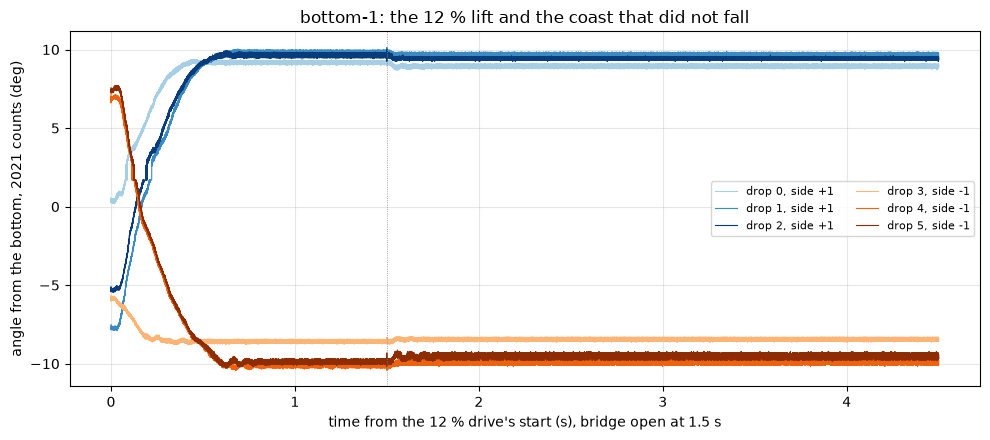

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for (_, r), color in zip(BOTTOM_CSV.iterrows(),
                         figures.shades("Blues", 3).tolist()
                         + figures.shades("Oranges", 3).tolist()):
    df, _ = load_sweep(DATA / "bottom-1" / r["folder"], BOTTOM)
    d = df[df["seg"] > 0]
    t = np.arange(len(d)) / FS
    ax.plot(t, d["theta"], lw=0.8, color=color,
            label=f"drop {r['k']}, side {r['side']:+d}")
ax.axvline(1.5, **figures.EDGE_STYLE)
figures.label(ax, x="time from the 12 % drive's start (s), bridge open "
              "at 1.5 s", y=f"angle from the bottom, {BOTTOM} counts (deg)",
              title="bottom-1: the 12 % lift and the coast that did not "
              "fall")
ax.legend(fontsize=8, ncol=2)
figures.finish(fig)

What you are looking at. The six drops' angle from the bottom against time, the 12 % drive to 1.5 s, then the coast. Each trace stays flat after the bridge opens. Nothing fell.

## 3. The static friction

Three readings of the friction that holds the back-driven train still against gravity, the holds that did not fall, the start of each fall and where the swings died.

In [16]:
LADDER_CSV = pd.read_csv(DATA / "ladder-1/ladder.csv")
SEEK = LADDER_CSV["first_pos"].to_numpy()   # where each rung started


def hold_report(name, counts):
    """Angle and gravity's torque at a rest, and the motor's share."""
    th = np.abs(theta_deg(counts, BOTTOM))
    tau = gravity_coins(th)             # mN m, coins-scale
    print(f"{name:24s} {th.mean():5.2f} deg (sd {th.std(ddof=1):.2f}, n "
          f"{len(th)}): {tau.mean():5.2f} mN m coins-scale, "
          f"{tau.mean() * SCALE:5.2f} absolute = "
          f"{tau.mean() * SCALE / GEAR * 1e3:4.1f} uN m, "
          f"{tau.mean() * SCALE / GEAR / KE:4.1f} mA at the motor")
    return th, tau * SCALE


TH_UP, HELD_UP = hold_report("12 % rest, up side", up12)
TH_DN, HELD_DN = hold_report("12 % rest, down side", dn12)
hold_report("seek rests, up side", SEEK[SEEK > BOTTOM])
hold_report("seek rests, down side", SEEK[SEEK < BOTTOM])
HELD_LO = min(HELD_UP.mean(), HELD_DN.mean())   # the sides' means
print(f"lower bound on the held static friction {HELD_LO:.1f} mN m")
SEEK_MAX = np.abs(theta_deg(SEEK, BOTTOM)).max()
print(f"seek rests {theta_deg(SEEK.min(), BOTTOM):+.1f} to "
      f"{theta_deg(SEEK.max(), BOTTOM):+.1f} deg, the farthest "
      f"{gravity_coins(SEEK_MAX) * SCALE:.1f} mN m absolute")

12 % rest, up side        9.52 deg (sd 0.33, n 3): 13.85 mN m coins-scale, 16.66 absolute = 54.1 uN m, 46.7 mA at the motor
12 % rest, down side      9.51 deg (sd 0.83, n 3): 13.83 mN m coins-scale, 16.65 absolute = 54.0 uN m, 46.6 mA at the motor
seek rests, up side       6.44 deg (sd 2.68, n 17):  9.37 mN m coins-scale, 11.28 absolute = 36.6 uN m, 31.6 mA at the motor
seek rests, down side     6.00 deg (sd 2.77, n 28):  8.74 mN m coins-scale, 10.51 absolute = 34.1 uN m, 29.4 mA at the motor
lower bound on the held static friction 16.6 mN m
seek rests -12.5 to +13.2 deg, the farthest 23.0 mN m absolute


The 12 % rests held through their 3 s coast at 9.52 and 9.51 degrees, 6 of 6. Gravity there is 16.66 and 16.65 mN m at the output, so the train's static friction, back-driven with the bridge open, holds at least 16.6 mN m. That is a lower bound, and section 11.7 measures it. At the motor it is 54 uN m, 46.7 mA at Ke. The seek to the start of each ladder rung left the arm anywhere from -12.5 to +13.2 degrees, and the farthest of those rests held 23.0 mN m.

In [17]:
J_REFL = J_MOTOR * GEAR ** 2            # kg m2, rotor + train at the output
J_COINS = COINS_G / 1e3 * (COINS_R_MM / 1e3) ** 2   # kg m2, point masses
J_OUT = J_REFL + J_COINS                # coins-scale, as the note takes it
J_ARM = (BLOCK_G * BLOCK_R_MM ** 2 + MOUNT_G * MOUNT_R_MM ** 2) / 1e9
J_TOTAL = J_OUT + J_ARM                 # kg m2, the arm as point masses
print(f"at the output: rotor + train {J_REFL * 1e3:.3f} g m2, coins "
      f"{J_COINS * 1e3:.3f}, arm {J_ARM * 1e3:.3f}, sum "
      f"{J_TOTAL * 1e3:.3f} g m2 (coins-scale {J_OUT * 1e3:.3f})")

at the output: rotor + train 0.610 g m2, coins 0.584, arm 0.088, sum 1.283 g m2 (coins-scale 1.195)


In [18]:
CYCLES = pd.read_csv(DATA / "lift-1/cycles.csv")
FALL_ROWS, DRIVE_ROWS = {}, {}
for _, r in CYCLES.iterrows():
    df, _ = load_sweep(DATA / "lift-1" / r["folder"], BOTTOM)
    s1 = df[df["seg"] == 1].reset_index(drop=True)   # the drive
    s2 = df[df["seg"] == 2].reset_index(drop=True)   # the 3 s coast
    DRIVE_ROWS[r["k"]] = tel.drive_rows(s1).reset_index(drop=True)
    # the stream opens before the bridge does: from 2 rows after
    z = int(np.flatnonzero(s2["duty_counts"].to_numpy() == 0)[0]) + 2
    FALL_ROWS[r["k"]] = (s2, s2.iloc[z:].reset_index(drop=True))
print(f"{len(CYCLES)} cycles: drives of {sorted(CYCLES['spin_ms'].unique())}"
      f" ms, each followed by a 3 s coast")

12 cycles: drives of [np.int64(500), np.int64(700), np.int64(1000)] ms, each followed by a 3 s coast


In [19]:
fall_rest = []
for _, r in CYCLES.iterrows():
    s2, f = FALL_ROWS[r["k"]]
    end = s2["pos"].iloc[-10000:].median()   # the coast's last 0.5 s
    # the pot's last move of more than 3 counts off its end rest
    moving = np.flatnonzero(np.abs(s2["pos"].to_numpy() - end) > 3)
    fall_rest.append({
        "k": r["k"], "side": r["side"], "duty_pct": r["duty_pct"],
        "repeat": r["repeat"], "fall_end_pos": end,
        "end_deg": theta_deg(end, BOTTOM),
        "t_still_s": (moving[-1] + 1) / FS if len(moving) else 0.0})
FALL_REST = pd.DataFrame(fall_rest)
show(FALL_REST, n=None)
SWING = FALL_REST["end_deg"].abs()
print(f"swing rests {SWING.min():.1f} to {SWING.max():.1f} deg from the "
      f"bottom, {gravity_coins(SWING).min() * SCALE:.1f} to "
      f"{gravity_coins(SWING).max() * SCALE:.1f} mN m absolute")

,k,side,duty_pct,repeat,fall_end_pos,end_deg,t_still_s
0,0,1,20,0,2092.000,4.643,2.786
1,1,1,20,1,2104.000,5.348,2.331
2,2,1,30,0,2018.000,-0.161,2.946
3,3,1,30,1,2015.000,-0.323,2.989
4,4,1,40,0,1922.000,-4.577,2.998
5,5,1,40,1,1914.000,-4.937,0.741
6,6,-1,20,0,1895.000,-5.966,0.534
7,7,-1,20,1,1912.000,-5.044,0.579
8,8,-1,30,0,2047.000,1.686,2.984
9,9,-1,30,1,2059.000,2.506,3.000


swing rests 0.2 to 7.4 deg from the bottom, 0.3 to 13.0 mN m absolute


In [20]:
RELEASE_S = 0.08                        # s, the fall's start fitted
rel = []
for _, r in CYCLES.iterrows():
    _, f = FALL_ROWS[r["k"]]
    tf = np.arange(len(f)) / FS
    th = np.asarray(theta_deg(f["pos"], BOTTOM))   # signed
    m0 = tf < RELEASE_S
    # theta = theta0 + alpha t^2 / 2 from rest: twice the square term
    alpha = 2 * np.polyfit(tf[m0], np.radians(th[m0]), 2)[0]   # rad/s2
    sin0 = np.sin(np.radians(th[0]))   # gravity pulls to the bottom
    rel.append({"k": r["k"], "side": r["side"], "duty_pct": r["duty_pct"],
                "theta0": th[0], "alpha_rad_s2": alpha,
                "release_coins": abs(-TAU_COINS * sin0
                                     - J_OUT * alpha * 1e3),
                "tau_g_mn_m": -TAU_H * sin0,              # absolute
                "j_alpha_mn_m": J_TOTAL * alpha * 1e3,    # absolute
                "release_mn_m": abs(-TAU_H * sin0
                                    - J_TOTAL * alpha * 1e3)})
RELEASE = pd.DataFrame(rel)
show(RELEASE, n=None)
rc, ra = RELEASE["release_coins"], RELEASE["release_mn_m"]
print(f"release friction {rc.mean():.1f} +/- {rc.std(ddof=1):.1f} mN m "
      f"coins-scale; absolute with the arm's weight and inertia "
      f"{ra.mean():.1f} +/- {ra.std(ddof=1):.1f} (n {len(rc)})")
for side in (1, -1):
    x = RELEASE[RELEASE["side"] == side]["release_mn_m"]
    print(f"   side {side:+d}: {x.min():.1f} to {x.max():.1f} mN m")
print(f"fit over the first {RELEASE_S * 1e3:.0f} ms; in motor units "
      f"{ra.mean() / GEAR * 1e3:.0f} uN m, "
      f"{ra.mean() / GEAR / KE:.0f} mA at Ke")

,k,side,duty_pct,theta0,alpha_rad_s2,release_coins,tau_g_mn_m,j_alpha_mn_m,release_mn_m
0,0,1,20,20.578,-6.154,22.071,-35.411,-7.893,27.518
1,1,1,20,20.578,-1.197,27.993,-35.411,-1.535,33.876
2,2,1,30,36.433,-17.913,28.314,-59.831,-22.976,36.855
3,3,1,30,36.389,-14.598,32.223,-59.769,-18.724,41.045
4,4,1,40,48.305,-32.122,24.132,-75.227,-41.202,34.025
5,5,1,40,49.321,-31.074,26.361,-76.404,-39.858,36.546
6,6,-1,20,-21.120,4.687,24.563,36.301,6.012,30.290
7,7,-1,20,-22.967,8.990,21.924,39.312,11.531,27.780
8,8,-1,30,-38.800,27.304,19.835,63.129,35.022,28.107
9,9,-1,30,-39.122,26.590,21.054,63.569,34.106,29.463


release friction 25.2 +/- 3.6 mN m coins-scale; absolute with the arm's weight and inertia 33.4 +/- 4.7 (n 12)
   side +1: 27.5 to 41.0 mN m
   side -1: 27.8 to 39.1 mN m
fit over the first 80 ms; in motor units 108 uN m, 94 mA at Ke


The start of each fall. Over the first 80 ms of a coast the arm starts from rest, so its angle is $\theta_0 + \alpha t^2 / 2$, and a quadratic gives the acceleration $\alpha$ ("alpha"). Gravity less $J \alpha$ is the friction the fall starts against. Gravity is the absolute torque, the coins and the arm. $J$ is the inertia at the output, the coins at their radius, the block and lid at the cups' center and the mount at its centroid as point masses, 0.088 g m2 for the arm, and the rotor and train reflected through $N^2$, 1.283 g m2 in all. The beam's own spread about its centroid is left out, a few percent of the arm's term. The coins-scale reading, the coins' gravity and inertia alone, is printed beside it.

The swings died 0.2 to 7.4 degrees from the bottom, all inside the 9.5 degree band of the holds, where gravity is 0.3 to 13.0 mN m.

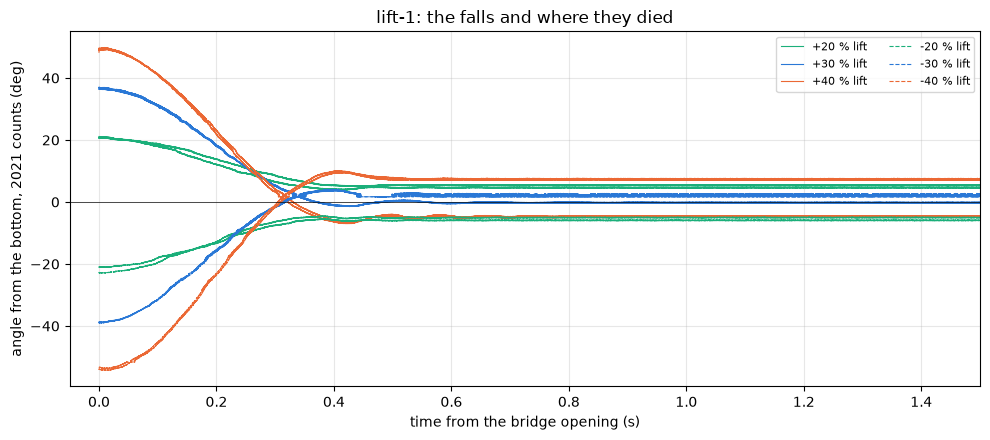

In [21]:
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = {20: GREEN, 30: BLUE, 40: ORANGE}
for _, r in CYCLES.iterrows():
    _, f = FALL_ROWS[r["k"]]
    t = np.arange(len(f)) / FS
    ax.plot(t, theta_deg(f["pos"], BOTTOM), lw=0.8,
            color=colors[r["duty_pct"]], ls="-" if r["side"] > 0 else "--",
            label=(f"{r['side'] * r['duty_pct']:+d} % lift"
                   if r["repeat"] == 0 else None))
ax.axhline(0, color=INK, lw=0.5)
ax.set_xlim(-0.05, 1.5)
figures.label(ax, x="time from the bridge opening (s)",
              y=f"angle from the bottom, {BOTTOM} counts (deg)",
              title="lift-1: the falls and where they died")
ax.legend(fontsize=8, ncol=2)
figures.finish(fig)

What you are looking at. The angle from the bottom through each coast after a lift, the up side solid and the down side dashed, one color per lift duty. The release friction reads 33.4 +/- 4.7 mN m (n 12), 27.5 to 41.0 on the up side and 27.8 to 39.1 on the down side, the two sides inside each other's scatter. At the motor that is 108 uN m, 94 mA at Ke. Confidence moderate to low. The first 80 ms also hold the lash unwinding, where the motor turns before the pot moves, so part of this reading may be the arm waiting on the lash. The held bound of 16.6 mN m has no such problem.

## 4. The torque curve

Each ladder rung holds a duty for 3 s. The arm rests where the motor's torque through the train equals gravity plus the friction that resists its rise. A rung's first window shows where it started and its last shows the rest, the crest current and the crest tap volts.

In [22]:
def rung_row(r, block="ladder-1", ladder=None, probe=None):
    """One ladder rung: where it started, where it rested at the end of
    the hold, the crest current, the crest tap volts and the window.
    Sitting 1's ladder by default, another sitting's by its block."""
    ladder = LADDER_CSV if ladder is None else ladder
    probe = probe_for if probe is None else probe
    folder = DATA / block / r["folder"]
    df, _ = load_sweep(folder)
    segs = sorted(df["seg"].unique())
    first = tel.settled(df[df["seg"] == segs[1]])   # the first 100 ms
    last = tel.settled(df[df["seg"] == segs[-1]])   # the hold's last 100
    cmd = last["cmd_duty_q15"].iloc[0]
    pr = probe(f"{block}/{r['folder']}")
    return {
        "k": r["k"], "side": r["side"], "duty_pct": r["duty_pct"],
        "approach": r["approach"],
        "min_into": (r["t_start"] - ladder["t_start"].min()) / 60,
        "first_pos": first["pos"].median(), "rest_pos": last["pos"].median(),
        "rest_range": last["pos"].max() - last["pos"].min(),
        "rest_sd": last["pos"].std(), "rest_deg_nominal": r["rest_deg"],
        "duty_ticks": last["duty_counts"].abs().median(),
        "duty_ticks_min": last["duty_counts"].abs().min(),
        "duty_ticks_cmd": int(BOARD.drive_ticks(int(cmd))),
        "window_valid": last["window_valid"].mean(),
        "i_crest_a": last["i_a"].mean(),
        "i_sd_counts": last["current_raw"].std(),
        "v_on_v": abs(last["vdiff_v"].mean()),   # signed by direction
        "D": last["D"].median(),
        "ntc_c": np.nan if pr is None else pr["ntc_c"],
        "rail_probe_v": np.nan if pr is None else pr["rail_v"]}


RUNGS = pd.DataFrame([rung_row(r) for _, r in LADDER_CSV.iterrows()])
print(f"{len(RUNGS)} rungs over {RUNGS['min_into'].max():.0f} minutes")

45 rungs over 40 minutes


In [23]:
MOVE_COUNTS = 8         # counts, a rung whose rest left its start
STILL_RANGE = 8         # counts, the pos range of a settled rest
STILL_I_SD = 4.5        # counts, the current sd of a quiet stall
R = RUNGS
R["theta"] = theta_deg(R["rest_pos"], BOTTOM)
R["outside_table"] = outside_table(R["rest_pos"])
R["past_soft"] = (R["rest_pos"] < SOFT[0]) | (R["rest_pos"] > SOFT[1])
R["moved"] = (R["rest_pos"] - R["first_pos"]).abs() > MOVE_COUNTS
R["stalled"] = ((R["rest_range"] <= STILL_RANGE)
                & (R["i_sd_counts"] <= STILL_I_SD))
R["v_on_valid"] = R["duty_ticks"] >= BOARD.v_window_min_ticks
print(f"gates: moved over {MOVE_COUNTS} counts, rest range <= "
      f"{STILL_RANGE} counts, current sd <= {STILL_I_SD} counts; tap floor "
      f"{BOARD.v_window_min_ticks} ticks")
# under the tap floor V_on comes from the side's own line on current
for side in (1, -1):
    ok = R[(R["side"] == side) & R["v_on_valid"]]
    fv = results.fit_line(ok["i_crest_a"], ok["v_on_v"])
    low = (R["side"] == side) & ~R["v_on_valid"]
    R.loc[low, "v_on_v"] = (fv["intercept"]
                            + fv["slope"] * R.loc[low, "i_crest_a"])
    print(f"side {side:+d}: V_on = {fv['intercept']:.3f} "
          f"{fv['slope']:+.3f} x i (rms {fv['rms'] * 1e3:.0f} mV, n "
          f"{fv['n']}), set on {int(low.sum())} rungs under the tap floor")
vc, iw = construction_c(R["D"].to_numpy(), R["v_on_v"].to_numpy(),
                        R["i_crest_a"].to_numpy())
R["v_c_v"], R["i_w_a"], R["v_a_v"] = vc, iw, R["D"] * R["v_on_v"]
R["tau_coins"] = gravity_coins(R["theta"])   # mN m, coins-scale
R["tau_mn_m"] = R["tau_coins"] * SCALE       # mN m, absolute

gates: moved over 8 counts, rest range <= 8 counts, current sd <= 4.5 counts; tap floor 93 ticks
side +1: V_on = 4.956 -0.621 x i (rms 9 mV, n 21), set on 2 rungs under the tap floor
side -1: V_on = 4.978 -0.649 x i (rms 8 mV, n 20), set on 2 rungs under the tap floor


A rung enters the curve if it moved more than 8 counts from its start, settled to a pos range of 8 counts or less with a current sd of 4.5 counts or less, and rested inside the soft limits. The terminal sample is valid only from the tap floor of 93 ticks, so the 6 % rungs, 72 ticks, take $V_\mathrm{on}$ from their side's own line of $V_\mathrm{on}$ on current.

In [24]:
show(R[["k", "side", "duty_pct", "approach", "first_pos", "rest_pos",
        "rest_range", "theta", "outside_table", "past_soft", "duty_ticks",
        "window_valid", "i_crest_a", "i_sd_counts", "v_on_v", "i_w_a",
        "v_c_v", "tau_mn_m", "moved", "stalled"]], n=None)
held = ((R["duty_ticks"] == R["duty_ticks_cmd"])
        & (R["duty_ticks_min"] == R["duty_ticks"]))
print(f"rungs holding the commanded window to the last row: "
      f"{int(held.sum())} of {len(R)}")

,k,side,duty_pct,approach,first_pos,rest_pos,rest_range,theta,outside_table,past_soft,duty_ticks,window_valid,i_crest_a,i_sd_counts,v_on_v,i_w_a,v_c_v,tau_mn_m,moved,stalled
0,0,1,4,below,2106.000,2106.000,6,5.460,False,False,48.000,0.000,0.050,1.059,4.925,0.028,0.086,9.586,False,True
1,1,1,6,below,1848.000,2012.000,5,-0.484,False,False,72.000,1.000,0.072,1.120,4.911,0.050,0.178,0.852,True,True
2,2,1,8,below,2013.000,2047.000,14,1.686,False,False,96.000,1.000,0.094,1.004,4.904,0.072,0.270,2.964,True,False
3,3,1,10,below,2060.000,2135.000,5,7.135,False,False,120.000,1.000,0.114,1.137,4.896,0.093,0.362,12.514,True,True
4,4,1,12,below,1844.000,2175.000,7,9.540,False,False,144.000,1.000,0.136,1.081,4.882,0.116,0.453,16.698,True,True
5,5,1,14,below,2193.000,2211.000,7,11.528,False,False,168.000,1.000,0.158,1.339,4.869,0.138,0.543,20.135,True,True
6,6,1,16,below,1845.000,2302.000,4,15.783,False,False,192.000,1.000,0.179,1.120,4.851,0.160,0.634,27.402,True,True
7,7,1,18,below,1879.000,2350.000,7,18.443,False,False,216.000,1.000,0.199,1.180,4.833,0.180,0.724,31.873,True,True
8,8,1,20,below,1870.000,2373.000,5,19.798,False,False,240.000,1.000,0.219,1.115,4.817,0.201,0.813,34.124,True,True
9,9,1,22,below,1843.000,2448.000,7,23.879,False,False,264.000,1.000,0.239,1.166,4.798,0.221,0.902,40.784,True,True


rungs holding the commanded window to the last row: 45 of 45


In [25]:
USE = R[R["moved"] & ~R["past_soft"] & R["stalled"]].copy()
BELOW = USE[USE["approach"] == "below"]
dropped = R[~R.index.isin(USE.index)]
print(f"torque-curve rungs {len(USE)} of {len(R)}, {len(BELOW)} from below")
show(dropped[["k", "side", "duty_pct", "approach", "window_valid",
              "rest_range", "moved", "past_soft", "stalled"]], n=None)

torque-curve rungs 34 of 45, 30 from below


,k,side,duty_pct,approach,window_valid,rest_range,moved,past_soft,stalled
0,0,1,4,below,0.000,6,False,False,True
2,2,1,8,below,1.000,14,True,False,False
19,19,1,54,below,1.000,8,True,True,True
22,22,1,46,above,1.000,9,True,False,False
23,23,-1,4,below,0.000,5,False,False,True
24,24,-1,6,below,1.000,5,False,False,True
25,25,-1,8,below,1.000,5,False,False,True
26,26,-1,10,below,1.000,5,False,False,True
27,27,-1,12,below,1.000,5,False,False,True
41,41,-1,50,below,1.000,3,True,True,True


Every rung held its commanded window to the last row, 45 of 45, and the current limit never engaged (section 10). 34 of 45 rungs enter the curve, 30 of them from below. Dropped are the 4 % rungs and the down side's 6 to 12 % rungs, which never moved, the 8 % up rung, which crept over a 14-count range, the 46 % up rung approached from above, range 9, and the three rungs that rested past the soft limits.

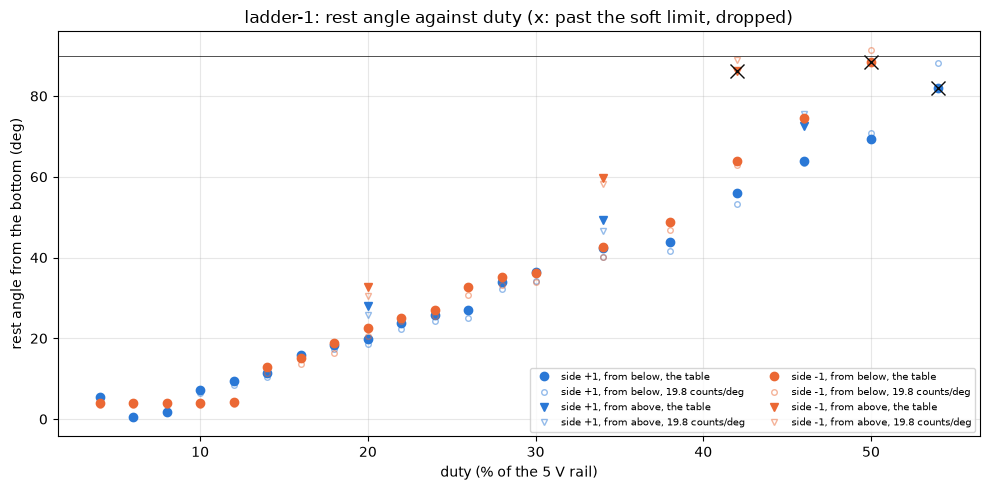

In [26]:
fig, ax = plt.subplots(figsize=(10, 5))
for side, color in ((1, BLUE), (-1, ORANGE)):
    for ap, mk in (("below", "o"), ("above", "v")):
        d = R[(R["side"] == side) & (R["approach"] == ap)]
        ax.plot(d["duty_pct"], d["theta"].abs(), mk, color=color,
                label=f"side {side:+d}, from {ap}, the table")
        ax.plot(d["duty_pct"], d["rest_deg_nominal"].abs(), mk,
                color=color, mfc="none", alpha=0.5, ms=4,
                label=f"side {side:+d}, from {ap}, 19.8 counts/deg")
    x = R[(R["side"] == side) & R["past_soft"]]
    ax.plot(x["duty_pct"], x["theta"].abs(), "x", color=INK, ms=10)
ax.axhline(90, color=INK, lw=0.5)
figures.label(ax, x="duty (% of the 5 V rail)",
              y="rest angle from the bottom (deg)",
              title="ladder-1: rest angle against duty (x: past the soft "
              "limit, dropped)")
ax.legend(fontsize=7, ncol=2)
figures.finish(fig)

What you are looking at. The rest angle against duty, filled through the table and open through the nominal 19.8 counts per degree, circles from below and triangles from above, the x marks the three rungs past the soft limits. The two scales part most near the bottom and at the ends, where the table's local scale differs most from 19.8.

From below, gravity's torque against the winding current is a line on each side. Its slope is Kt through the gears at the rising stall, and its intercept is the friction the rising arm sticks against.

In [27]:
def torque_line(d, y="tau_mn_m", x="i_w_a"):
    return results.fit_line(d[x], d[y])


FITS = {s: torque_line(BELOW[BELOW["side"] == s]) for s in (1, -1)}
FITS["pooled"] = torque_line(BELOW)
FITS_COINS = {s: torque_line(BELOW[BELOW["side"] == s], "tau_coins")
              for s in (1, -1)}
FITS_COINS["pooled"] = torque_line(BELOW, "tau_coins")
for key, f in FITS.items():
    fc = FITS_COINS[key]
    print(f"{str(key):>6s}: coins-scale {fc['intercept']:+.2f} + "
          f"{fc['slope']:.1f} i; absolute {f['intercept']:+.2f} "
          f"+/- {f['intercept_se']:.2f} + {f['slope']:.1f} +/- "
          f"{f['slope_se']:.1f} i (mN m, A); rms {f['rms']:.2f} mN m, "
          f"n {f['n']}; {f['slope'] / KT_IDEAL:.3f} of Ke x N")

     1: coins-scale -6.75 + 179.3 i; absolute -8.12 +/- 1.19 + 215.8 +/- 4.2 i (mN m, A); rms 2.03 mN m, n 17; 0.604 of Ke x N
    -1: coins-scale -7.81 + 194.7 i; absolute -9.40 +/- 1.63 + 234.3 +/- 5.6 i (mN m, A); rms 1.78 mN m, n 13; 0.656 of Ke x N
pooled: coins-scale -6.93 + 185.2 i; absolute -8.34 +/- 1.34 + 222.9 +/- 4.7 i (mN m, A); rms 2.81 mN m, n 30; 0.624 of Ke x N


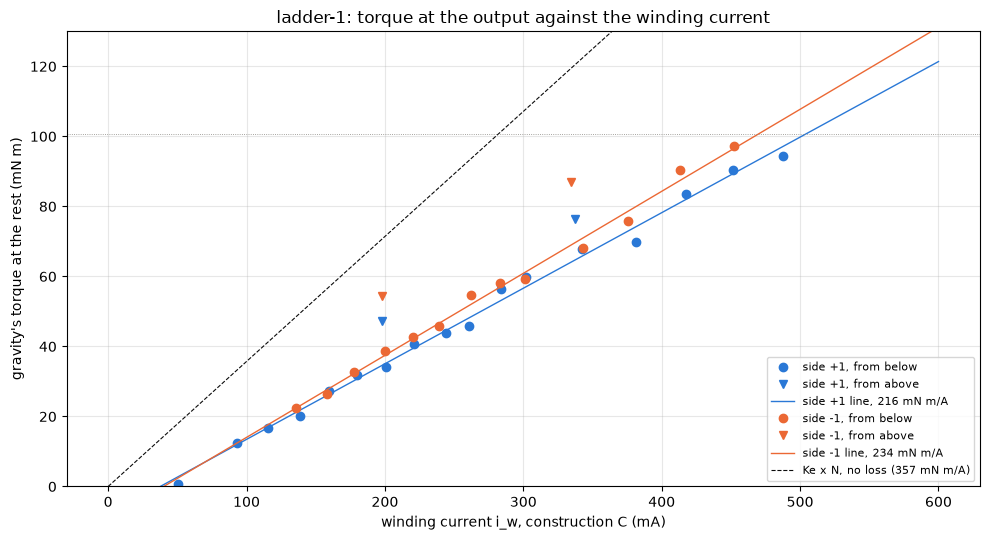

In [28]:
fig, ax = plt.subplots(figsize=(10, 5.5))
xx = np.linspace(0, 0.6, 10)
for side, color in ((1, BLUE), (-1, ORANGE)):
    for ap, mk in (("below", "o"), ("above", "v")):
        d = USE[(USE["side"] == side) & (USE["approach"] == ap)]
        ax.plot(d["i_w_a"] * 1e3, d["tau_mn_m"], mk, color=color,
                label=f"side {side:+d}, from {ap}")
    f = FITS[side]
    ax.plot(xx * 1e3, f["intercept"] + f["slope"] * xx, color=color,
            lw=1, label=f"side {side:+d} line, {f['slope']:.0f} mN m/A")
ax.plot(xx * 1e3, KT_IDEAL * xx, "--", color=INK, lw=0.8,
        label=f"Ke x N, no loss ({KT_IDEAL:.0f} mN m/A)")
ax.axhline(TAU_H, **figures.EDGE_STYLE)
ax.set_ylim(0, 130)
figures.label(ax, x="winding current i_w, construction C (mA)",
              y="gravity's torque at the rest (mN m)",
              title="ladder-1: torque at the output against the winding "
              "current")
ax.legend(fontsize=8)
figures.finish(fig)

What you are looking at. Gravity's torque at each rest against the winding current, the from-below lines per side, the dashed line the lossless $K_e N$ of 357.1 mN m/A and the dotted line the 100.75 mN m at horizontal. The up side reads 215.8 +/- 4.2 mN m/A and the down side 234.3 +/- 5.6, 0.604 and 0.656 of $K_e N$, with residual rms 2.03 and 1.78 mN m. Pooled, the slope is 222.9 mN m/A, 0.624 of the lossless value. The intercepts are -8.12 and -9.40 mN m, 38 and 40 mA of current before the arm takes any torque.

side +1: 6 to 50 %, largest |residual| 4.27 mN m, trend on duty -0.002 +/- 0.042 mN m per %
side -1: 14 to 46 %, largest |residual| 3.15 mN m, trend on duty +0.001 +/- 0.055 mN m per %


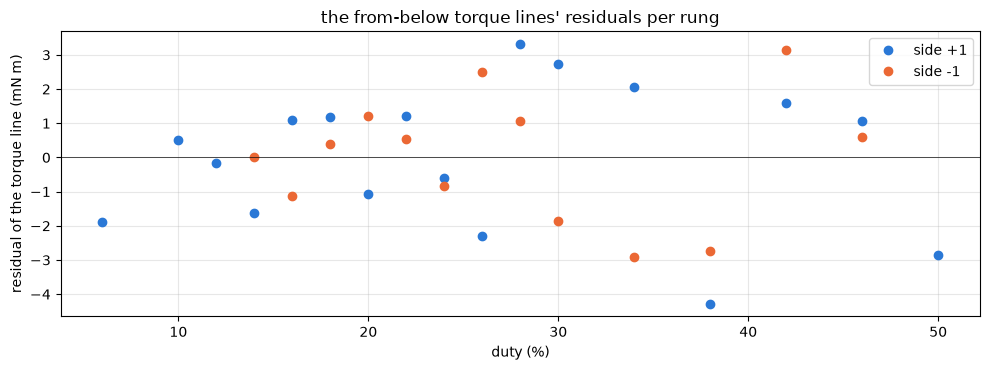

In [29]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for side, color in ((1, BLUE), (-1, ORANGE)):
    d = BELOW[BELOW["side"] == side]
    res = FITS[side]["resid"]
    ax.plot(d["duty_pct"], res, "o", color=color, label=f"side {side:+d}")
    tr = results.fit_line(d["duty_pct"], res)
    print(f"side {side:+d}: {d['duty_pct'].min()} to "
          f"{d['duty_pct'].max()} %, largest |residual| "
          f"{np.abs(res).max():.2f} mN m, trend on duty "
          f"{tr['slope']:+.3f} +/- {tr['slope_se']:.3f} mN m per %")
ax.axhline(0, color=INK, lw=0.5)
figures.label(ax, x="duty (%)", y="residual of the torque line (mN m)",
              title="the from-below torque lines' residuals per rung")
ax.legend()
figures.finish(fig)

What you are looking at. Each from-below rung's residual about its side's line. They scatter with no trend in duty, -0.002 +/- 0.042 mN m per % on the up side over 6 to 50 % and +0.001 +/- 0.055 on the down side over 14 to 46 %, the largest 4.27 and 3.15 mN m. The line holds over the whole range each side was read.

In [30]:
for side in (1, -1):
    d = BELOW[BELOW["side"] == side]
    inside = torque_line(d[~d["outside_table"]])
    crest = torque_line(d, x="i_crest_a")
    nominal = results.fit_line(
        d["i_w_a"], gravity_coins(d["rest_deg_nominal"]) * SCALE)
    print(f"side {side:+d}: table-only {inside['slope']:.1f} +/- "
          f"{inside['slope_se']:.1f}, {inside['intercept']:+.2f} (n "
          f"{inside['n']}); crest current {crest['slope']:.1f}, "
          f"{crest['intercept']:+.2f}; nominal 19.8 counts/deg "
          f"{nominal['slope']:.1f}, {nominal['intercept']:+.2f}")
TABLE_ONLY = {s: torque_line(BELOW[(BELOW["side"] == s)
                                   & ~BELOW["outside_table"]])
              for s in (1, -1)}

side +1: table-only 219.0 +/- 5.3, -8.71 (n 15); crest current 221.3, -13.27; nominal 19.8 counts/deg 216.2, -10.21
side -1: table-only 232.9 +/- 6.9, -9.10 (n 12); crest current 240.3, -15.02; nominal 19.8 counts/deg 240.5, -13.55


Three variants of the same lines. Without the rungs the table had to extrapolate past its ends the slopes read 219.0 +/- 5.3 and 232.9 +/- 6.9 mN m/A. With the as-read crest current in place of $i_w$ they read 221.3 and 240.3, the intercepts -13.27 and -15.02. Through the nominal 19.8 counts per degree they read 216.2 and 240.5.

In [31]:
sens = []
for b in (BOTTOM_LO, BOTTOM, BOTTOM_HI):
    tau = gravity_coins(theta_deg(BELOW["rest_pos"], b)) * SCALE
    d = BELOW.assign(tau_b=tau)
    for key, part in ((1, d[d["side"] == 1]), (-1, d[d["side"] == -1]),
                      ("pooled", d)):
        f = torque_line(part, "tau_b")
        sens.append({"bottom": b, "line": str(key), "slope": f["slope"],
                     "slope_se": f["slope_se"], "intercept": f["intercept"],
                     "intercept_se": f["intercept_se"], "rms": f["rms"]})
SENS = pd.DataFrame(sens)
show(SENS, n=None)
for line, g in SENS.groupby("line", sort=False):
    s = g.set_index("bottom")
    i_pct = np.ptp(s["intercept"]) / abs(s.loc[BOTTOM, "intercept"]) * 100
    print(f"{line:>6s}: slope spread {np.ptp(s['slope']) / s.loc[BOTTOM,
          'slope'] * 100:.1f} % over the three, {BOTTOM} against "
          f"{BOTTOM_HI} {abs(s.loc[BOTTOM, 'slope'] - s.loc[BOTTOM_HI,
          'slope']) / s.loc[BOTTOM, 'slope'] * 100:.2f} %; intercept "
          f"spread {np.ptp(s['intercept']):.2f} mN m, {i_pct:.0f} % of "
          f"its value")

,bottom,line,slope,slope_se,intercept,intercept_se,rms
0,2007,1,215.189,4.485,-6.979,1.273,2.173
1,2007,-1,236.927,5.750,-11.173,1.669,1.823
2,2007,pooled,222.496,4.093,-8.138,1.173,2.461
3,2021,1,215.821,4.192,-8.124,1.190,2.031
4,2021,-1,234.271,5.603,-9.404,1.626,1.776
5,2021,pooled,222.857,4.677,-8.339,1.341,2.813
6,2024,1,215.793,4.127,-8.335,1.171,1.999
7,2024,-1,233.646,5.570,-8.991,1.616,1.766
8,2024,pooled,222.814,4.889,-8.347,1.401,2.940


     1: slope spread 0.3 % over the three, 2021 against 2024 0.01 %; intercept spread 1.36 mN m, 17 % of its value
    -1: slope spread 1.4 % over the three, 2021 against 2024 0.27 %; intercept spread 2.18 mN m, 23 % of its value
pooled: slope spread 0.2 % over the three, 2021 against 2024 0.02 %; intercept spread 0.21 mN m, 3 % of its value


### The bottom's effect

The same lines with the bottom at each of the three candidates. The pooled slope moves 0.2 % across them and each side's slope up to 1.4 %, the down side the most. 2021 against 2024 moves every slope under 0.3 %. The intercepts move 1.36 and 2.18 mN m, 17 and 23 % of their small values, since they sit near zero. The bottom's effect is folded into the brackets below, each spanning the three bottoms as well as the fit's standard error about each.

In [32]:
def bracket(line, col):
    """(value at the bottom of record, lo, hi): lo and hi span the three
    bottoms and the fit's se about each."""
    g = SENS[SENS["line"] == line].set_index("bottom")
    v = g.loc[BOTTOM, col]
    return (v, (g[col] - g[col + "_se"]).min(),
            (g[col] + g[col + "_se"]).max())


KT_GEAR = {s: bracket(str(s), "slope") for s in (1, -1)}
KT_GEAR["pooled"] = bracket("pooled", "slope")
INTERCEPT = {s: bracket(str(s), "intercept") for s in (1, -1)}
for s in (1, -1, "pooled"):
    v, lo, hi = KT_GEAR[s]
    print(f"{str(s):>6s}: Kt through the gears {v:.1f} ({lo:.1f} to "
          f"{hi:.1f}) mN m/A, {v / KT_IDEAL:.3f} ({lo / KT_IDEAL:.3f} to "
          f"{hi / KT_IDEAL:.3f}) of Ke x N")
for s in (1, -1):
    v, lo, hi = INTERCEPT[s]
    print(f"side {s:+d}: intercept {v:+.2f} ({lo:+.2f} to {hi:+.2f}) mN m"
          f", {-v / FITS[s]['slope'] * 1e3:.0f} mA at zero torque")

     1: Kt through the gears 215.8 (210.7 to 220.0) mN m/A, 0.604 (0.590 to 0.616) of Ke x N
    -1: Kt through the gears 234.3 (228.1 to 242.7) mN m/A, 0.656 (0.639 to 0.680) of Ke x N
pooled: Kt through the gears 222.9 (217.9 to 227.7) mN m/A, 0.624 (0.610 to 0.638) of Ke x N
side +1: intercept -8.12 (-9.51 to -5.71) mN m, 38 mA at zero torque
side -1: intercept -9.40 (-12.84 to -7.37) mN m, 40 mA at zero torque


Kt through the gears at the rising stall is 215.8 (210.7 to 220.0) mN m/A on the up side and 234.3 (228.1 to 242.7) on the down side, 222.9 (217.9 to 227.7) pooled. That is 0.604, 0.656 and 0.624 of $K_e N$, likely the train's efficiency at a rising stall, taken with this servo's own Ke of 1.1591 mV s/rad. The type's Ke, 1.1684, is slightly higher. The intercepts are -8.12 (-9.51 to -5.71) and -9.40 (-12.84 to -7.37) mN m.

The resistance result's as-read line predicts more current at a given duty than these 3 s holds drew. Section 8 takes that up.

## 5. The deadband

The plan meant the from-above rungs and the steps to measure the friction band under load. Both turned out to sit inside it.

In [33]:
above = []
for _, a in R[R["approach"] == "above"].iterrows():
    df, _ = load_sweep(DATA / "ladder-1" / f"ladder/{int(a['k'])}")
    seg = {s: g for s, g in df.groupby("seg")}
    same = R[(R["approach"] == "below") & (R["side"] == a["side"])]
    b = same[same["duty_pct"] == a["duty_pct"]].iloc[0]
    d6 = same[same["duty_pct"] == a["duty_pct"] + 6]
    above.append({
        "k": a["k"], "side": a["side"], "duty_pct": a["duty_pct"],
        "step_first": seg[3]["pos"].iloc[:200].median(),   # first 10 ms
        "step_last": seg[3]["pos"].iloc[-200:].median(),   # last 10 ms
        "hold_end": seg[5]["pos"].iloc[-200:].median(),    # the d hold
        "theta_above": a["theta"], "theta_below": b["theta"],
        "theta_d6_below": d6["theta"].iloc[0] if len(d6) else np.nan,
        "i_w_a": b["i_w_a"], "v_on_v": b["v_on_v"], "v_c_v": b["v_c_v"]})
ABOVE = pd.DataFrame(above)
ABOVE["moved"] = (ABOVE[["step_first", "step_last", "hold_end"]]
                  .nunique(axis=1) > 1)
show(ABOVE.drop(columns=["i_w_a", "v_on_v", "v_c_v"]), n=None)
print(f"from-above rungs whose pos changed after the step down: "
      f"{int(ABOVE['moved'].sum())} of {len(ABOVE)}")

,k,side,duty_pct,step_first,step_last,hold_end,theta_above,theta_below,theta_d6_below,moved
0,20,1,20,2515.000,2515.000,2515.000,27.898,19.798,27.112,False
1,21,1,34,2927.000,2927.000,2927.000,49.269,42.363,NaN,False
2,22,1,46,3501.000,3501.000,3501.000,72.696,63.832,NaN,False
3,42,-1,20,1402.000,1402.000,1402.000,-32.769,-22.541,-32.819,False
4,43,-1,34,855.000,855.000,855.000,-59.746,-42.506,NaN,False
5,44,-1,42,247.000,247.000,247.000,-86.290,-63.982,NaN,False


from-above rungs whose pos changed after the step down: 0 of 6


In [34]:
ABOVE_OVER = 6          # % of duty, the plan's step down to the duty
# 6 % at the rung's own volts per amp, through that side's torque line
r_app = ABOVE["v_c_v"] / ABOVE["i_w_a"]
di_a = ABOVE_OVER / 100 * ABOVE["v_on_v"] / r_app
slope = ABOVE["side"].map({1: FITS[1]["slope"], -1: FITS[-1]["slope"]})
ABOVE["step_mn_m"] = slope * di_a
ABOVE["step_ma"] = di_a * 1e3
show(ABOVE[["k", "side", "duty_pct", "step_ma", "step_mn_m"]], n=None)
BAND_LO = (ABOVE["step_mn_m"].min(), ABOVE["step_mn_m"].max())
print(f"the step down took {ABOVE['step_ma'].min():.0f} to "
      f"{ABOVE['step_ma'].max():.0f} mA off, {BAND_LO[0]:.1f} to "
      f"{BAND_LO[1]:.1f} mN m absolute (coins-scale "
      f"{BAND_LO[0] / SCALE:.1f} to {BAND_LO[1] / SCALE:.1f})")

,k,side,duty_pct,step_ma,step_mn_m
0,20,1,20,71.333,15.395
1,21,1,34,67.565,14.582
2,22,1,46,64.087,13.831
3,42,-1,20,70.984,16.630
4,43,-1,34,67.655,15.850
5,44,-1,42,64.683,15.153


the step down took 64 to 71 mA off, 13.8 to 16.6 mN m absolute (coins-scale 11.5 to 13.8)


The from-above rungs held a duty 6 % higher, then stepped to the duty. The pot read the same count in the step's first and last 10 ms and at the end of the hold, so 0 of 6 moved. Each from-above rest is simply the rest at the duty 6 % higher, k20's 27.90 degrees against the 26 % rung's 27.11 from below and k42's -32.77 against -32.82. The half difference of the from-above and from-below rests is the ladder's rung spacing, not the friction.

What the data give is a bound, and section 11.4 measures it. The step took 64 to 71 mA off, 13.8 to 16.6 mN m of motor torque through each side's line, and the arm did not fall, at 20, 34 and 46 % on the up side and at 20, 34 and 42 % on the down side. So the friction band, the rise's friction plus the fall's, is at least 13.8 to 16.6 mN m at each of those rests. Whether the band grows with load, bounds alone do not show.

In [35]:
def step_row(r, edge, before, after, held, i, a, w):
    """The current's jump and settled change and the angle's change of
    one edge, per % of duty."""
    n = len(before)
    d_duty = ((held - np.median(before["duty_counts"].abs())) / ARR * 100
              if n else np.nan)
    i_before = before["i_a"].mean() if n else np.nan
    th_before = theta_deg(before["pos"].median(), BOTTOM) if n else np.nan
    th_after = theta_deg(after["pos"].iloc[-END_ROWS:].median(), BOTTOM)
    peak = np.nanargmax(np.abs(w))
    return {"k": r["k"], "side": r["side"], "base_pct": r["duty_pct"],
            "step_pct": r["step_pct"], "edge": edge, "d_duty": d_duty,
            "i_before_ma": i_before * 1e3,
            "di_jump_ma": (i[JUMP].mean() - i_before) * 1e3,
            "di_end_ma": (i[-END_ROWS:].mean() - i_before) * 1e3,
            "i_drift_ma": (i[-END_ROWS:].mean() - i[JUMP].mean()) * 1e3,
            "theta_before": th_before, "d_theta": th_after - th_before,
            "w_peak_rev_s": w[peak] / 360 * GEAR,
            "v_on_v": abs(after["vdiff_v"].iloc[40:].mean())}

In [36]:
CHAINS = pd.read_csv(DATA / "steps-1/chains.csv")
STEP_PCT = 5            # % of duty, the plan's step
JUMP = slice(20, 60)    # rows, 1 to 3 ms after the duty register flips
END_ROWS = 1000         # rows, the window's last 50 ms
step_rows, STEP_TRACES = [], {}
for _, r in CHAINS.iterrows():
    df, _ = load_sweep(DATA / "steps-1" / r["folder"], BOTTOM)
    for seg, edge in ((3, "step"), (4, "back")):
        s = df[df["seg"] == seg].reset_index(drop=True)
        e, held = tel.flip_row(s)   # the first row at the new duty
        if e >= 100:                # the 20 ms before the flip
            before = s.iloc[max(0, e - 400):e]
        elif seg == 4:              # the step's last 50 ms instead
            before = df[df["seg"] == 3].iloc[-END_ROWS:]
        else:                       # the hold was not streamed
            before = s.iloc[:e]
        after = s.iloc[e:]
        i = after["i_a"].to_numpy()
        a = angle_of(after["pos"].to_numpy())
        w = pot_speed(after["pos"].to_numpy(), 100)   # deg/s, 5 ms half
        step_rows.append(step_row(r, edge, before, after, held, i, a, w))
        STEP_TRACES[(r["k"], edge)] = (np.arange(len(after)) / FS, i,
                                       a - angle_of(before["pos"].median())
                                       if len(before) else a * np.nan)
STEPS = pd.DataFrame(step_rows)
print(f"{len(CHAINS)} chains, {len(STEPS)} edges; the jump "
      f"{JUMP.start / FS * 1e3:.0f} to {JUMP.stop / FS * 1e3:.0f} ms after "
      f"the flip, the end the last {END_ROWS / FS * 1e3:.0f} ms")

12 chains, 24 edges; the jump 1 to 3 ms after the flip, the end the last 50 ms


In [37]:
STEPS["k_jump"] = STEPS["di_jump_ma"] / STEPS["d_duty"]   # mA per %
STEPS["k_end"] = STEPS["di_end_ma"] / STEPS["d_duty"]     # mA per %
STEPS["k_theta"] = STEPS["d_theta"] / STEPS["d_duty"]     # deg per %
show(STEPS[["k", "side", "base_pct", "step_pct", "edge", "d_duty",
            "theta_before", "d_theta", "i_before_ma", "di_jump_ma",
            "di_end_ma", "k_jump", "k_end", "w_peak_rev_s"]], n=None)
UP = STEPS[STEPS["edge"] == "step"].dropna(subset=["d_duty"])
print(f"current per % at the edge {UP['k_jump'].mean():.2f} +/- "
      f"{UP['k_jump'].std(ddof=1):.2f} mA/%, 300 ms later "
      f"{UP['k_end'].mean():.2f} +/- {UP['k_end'].std(ddof=1):.2f} "
      f"(n {len(UP)}); free steps {K_I_FREE:.2f} mA/%")
print(f"V_on / 100 / R: {UP['v_on_v'].mean() / R_LOCKED * 10:.2f} mA/% "
      f"locked R, {UP['v_on_v'].mean() / 100 / (UP['k_jump'].mean() / 1e3):.2f}"
      f" ohm for the measured jump")
print(f"angle per % {UP['k_theta'].mean():+.3f} +/- "
      f"{UP['k_theta'].std(ddof=1):.3f} deg/%, largest |change| "
      f"{UP['d_theta'].abs().max():.2f} deg; peak pot speed "
      f"{STEPS['w_peak_rev_s'].abs().max():.1f} rev/s at the motor, mean "
      f"{STEPS['w_peak_rev_s'].abs().mean():.1f} "
      f"(free k_w x 5 % = {K_W_FREE * STEP_PCT:.1f})")

,k,side,base_pct,step_pct,edge,d_duty,theta_before,d_theta,i_before_ma,di_jump_ma,di_end_ma,k_jump,k_end,w_peak_rev_s
0,0,1,20,5,step,5.000,21.384,0.061,220.787,49.993,49.727,9.999,9.945,-2.568
1,0,1,20,5,back,-5.000,21.445,0.000,270.514,-51.760,-51.218,10.352,10.244,-2.826
2,1,1,20,-5,step,-5.000,20.402,-0.126,220.913,-53.105,-53.066,10.621,10.613,-2.537
3,1,1,20,-5,back,5.000,20.277,0.000,167.847,51.789,51.317,10.358,10.263,-2.444
4,2,1,34,5,step,5.000,42.724,-0.155,361.881,48.568,46.384,9.714,9.277,-2.573
5,2,1,34,5,back,-5.000,42.570,0.000,408.264,-49.049,-49.899,9.810,9.980,-2.217
6,3,1,34,-5,step,-5.000,42.415,0.052,359.867,-51.003,-51.350,10.201,10.270,-2.380
7,3,1,34,-5,back,5.000,42.467,0.000,308.517,50.523,49.644,10.105,9.929,-2.322
8,4,1,46,5,step,5.000,63.981,-0.334,472.893,47.356,44.420,9.471,8.884,-1.770
9,4,1,46,5,back,-5.000,63.647,0.000,517.312,-50.169,-50.413,10.034,10.083,1.806


current per % at the edge 9.93 +/- 0.38 mA/%, 300 ms later 9.81 +/- 0.58 (n 10); free steps 1.08 mA/%
V_on / 100 / R: 11.22 mA/% locked R, 4.77 ohm for the measured jump
angle per % -0.011 +/- 0.026 deg/%, largest |change| 0.33 deg; peak pot speed 2.8 rev/s at the motor, mean 2.1 (free k_w x 5 % = 28.2)


In [38]:
UP["drift_pct"] = UP["i_drift_ma"] / (UP["i_before_ma"]
                                     + UP["di_jump_ma"]) * 100
print(f"current drift over the 300 ms after the jump "
      f"{UP['i_drift_ma'].min():+.1f} to {UP['i_drift_ma'].max():+.1f} mA")
print("mean drift by base duty, %: " + ", ".join(
    f"{b} % {x:+.2f}" for b, x in UP.groupby("base_pct")["drift_pct"]
    .mean().items()))
back = STEPS[STEPS["edge"] == "back"].set_index("k")
end_back = back["i_before_ma"] + back["di_end_ma"]
start = UP.set_index("k")["i_before_ma"]
BACK_DIFF = (end_back - start).dropna()
print(f"the step back ends {BACK_DIFF.min():+.1f} to {BACK_DIFF.max():+.1f}"
      f" mA from the current before the step, at most "
      f"{(BACK_DIFF / start).abs().max() * 100:.1f} % (largest drift over "
      f"one window {UP['drift_pct'].abs().max():.2f} %); the angle back "
      f"{back['d_theta'].abs().max():.2f} deg at most")
NO_BEFORE = STEPS[(STEPS["edge"] == "step") & STEPS["d_duty"].isna()]
print(f"step edges with no rows before the flip: k "
      f"{NO_BEFORE['k'].tolist()}")
print(f"|di| per 5 % step: {UP['di_jump_ma'].abs().min():.0f} to "
      f"{UP['di_jump_ma'].abs().max():.0f} mA")

current drift over the 300 ms after the jump -2.9 to +0.0 mA
mean drift by base duty, %: 20 % -0.04, 34 % -0.16, 42 % -0.34, 46 % -0.39
the step back ends -6.0 to +1.0 mA from the current before the step, at most 1.3 % (largest drift over one window 0.56 %); the angle back 0.04 deg at most
step edges with no rows before the flip: k [6, 7]
|di| per 5 % step: 47 to 53 mA


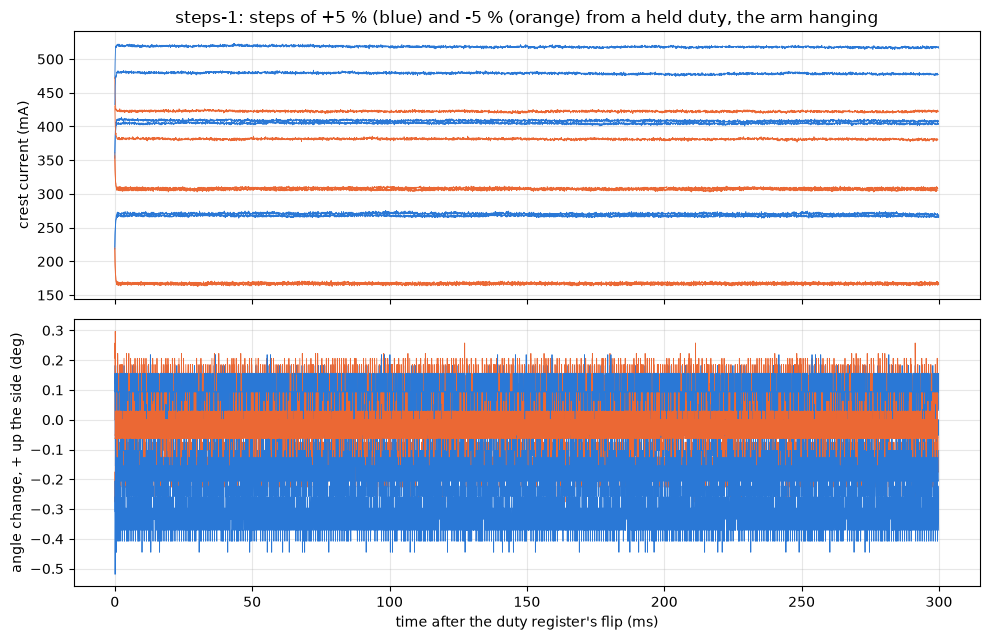

In [39]:
fig, axs = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
for (k, edge), (t, i, a) in STEP_TRACES.items():
    if edge != "step":
        continue
    r = CHAINS.set_index("k").loc[k]
    m = t < 0.3
    color = BLUE if r["step_pct"] > 0 else ORANGE
    axs[0].plot(t[m] * 1e3, i[m] * 1e3, lw=0.6, color=color)
    axs[1].plot(t[m] * 1e3, a[m] * np.sign(r["side"]), lw=0.6, color=color)
figures.label(axs[0], y="crest current (mA)",
              title="steps-1: steps of +5 % (blue) and -5 % (orange) from "
              "a held duty, the arm hanging")
figures.label(axs[1], x="time after the duty register's flip (ms)",
              y="angle change, + up the side (deg)")
figures.finish(fig)

What you are looking at. The crest current (top) and the angle change (bottom) after each step edge, the +5 % steps in blue and the -5 % in orange. The current steps and stays. The angle does not move.

A step of 5 % changes the current by 9.93 +/- 0.38 mA per % 1 to 3 ms after the edge and 9.81 +/- 0.58 mA per % over the window's last 50 ms, n 10, 47 to 53 mA a step. Two of the twelve step edges, k6 and k7, have no rows before them, since the duty flips on row 0 of the streamed segment, so they are left out. Their back edges are measured and still. The measured jump is a stalled winding at 4.77 ohm. The free steps give 1.08 mA per %, since a free rotor turns the volts into speed and the held arm turns them all into current.

The angle changes -0.011 +/- 0.026 degrees per %, the largest change 0.33 degrees, and the pot's peak slope reads 2.1 rev/s at the motor on average, its noise. No delay and no time constant exist to report. Inside +/- 5 % of duty the load's step response is a pure current step and a still output. The current drifts down by up to 2.9 mA over the 300 ms after the jump, at most 0.56 % in one window, at the top duties. The step back leaves the current -6.0 to +1.0 mA from where it was before the step, at most 1.3 % over the two windows, consistent with that drift. The angle comes back to within 0.04 degrees.

So a constant-duty hold has a deadband of at least +/- 5 % of duty, 47 to 53 mA at the motor, at every angle tried. For stage 5 this is the floor a position loop has to push through before the output answers. It is a lower bound, and its size needs larger steps (section 10). Section 11.4 measures it.

## 6. The two sides

The two sides' lines differ in slope. What the data say about whether the train itself is asymmetric.

In [40]:
matched = R[(R["approach"] == "below") & R["moved"] & ~R["past_soft"]]
m = matched.pivot_table(index="duty_pct", columns="side",
                        values=["i_w_a", "rest_deg_nominal", "theta",
                                "tau_mn_m"]).dropna()
SIDES = pd.DataFrame({
    "i_dn_over_up": m[("i_w_a", -1)] / m[("i_w_a", 1)],
    "theta_nominal": m[("rest_deg_nominal", -1)].abs()
    / m[("rest_deg_nominal", 1)],
    "theta_table": m[("theta", -1)].abs() / m[("theta", 1)],
    "tau_per_a": (m[("tau_mn_m", -1)] / m[("i_w_a", -1)])
    / (m[("tau_mn_m", 1)] / m[("i_w_a", 1)])})
show(SIDES.reset_index(), n=None)
for col in SIDES:
    x = SIDES[col]
    print(f"{col:14s} down over up {x.mean():.4f} sd {x.std(ddof=1):.4f}"
          f" se {x.std(ddof=1) / np.sqrt(len(x)):.4f} (n {len(x)})")
at46 = SIDES.loc[46]
print(f"at 46 %: nominal {at46['theta_nominal']:.2f}, table "
      f"{at46['theta_table']:.2f}, torque per amp {at46['tau_per_a']:.2f}")

,duty_pct,i_dn_over_up,theta_nominal,theta_table,tau_per_a
0,14,0.978,1.113,1.111,1.134
1,16,0.991,0.919,0.966,0.976
2,18,0.987,0.945,1.023,1.035
3,20,0.996,1.118,1.139,1.137
4,22,0.998,1.086,1.052,1.051
5,24,0.979,1.057,1.044,1.063
6,26,1.006,1.222,1.210,1.182
7,28,0.999,1.033,1.034,1.030
8,30,0.998,0.994,0.992,0.995
9,34,1.001,1.000,1.003,1.001


i_dn_over_up   down over up 0.9929 sd 0.0088 se 0.0024 (n 13)
theta_nominal  down over up 1.0738 sd 0.0926 se 0.0257 (n 13)
theta_table    down over up 1.0765 sd 0.0752 se 0.0209 (n 13)
tau_per_a      down over up 1.0673 sd 0.0613 se 0.0170 (n 13)
at 46 %: nominal 1.17, table 1.17, torque per amp 1.07


In [41]:
def split_sigma(fits):
    """The down side's slope less the up side's, in their joint se."""
    d = fits[-1]["slope"] - fits[1]["slope"]
    return d / np.hypot(fits[-1]["slope_se"], fits[1]["slope_se"])


SPLIT_ALL = split_sigma(FITS)
SPLIT_TABLE = split_sigma(TABLE_ONLY)
for name, f, sig in (("all rungs", FITS, SPLIT_ALL),
                     ("table-only", TABLE_ONLY, SPLIT_TABLE)):
    print(f"{name:10s}: up {f[1]['slope']:.1f} +/- {f[1]['slope_se']:.1f}"
          f", down {f[-1]['slope']:.1f} +/- {f[-1]['slope_se']:.1f} "
          f"mN m/A, {sig:.1f} sigma")
SIDE_TPA = {}
for b in (BOTTOM_LO, BOTTOM, BOTTOM_HI):
    th = np.abs(theta_deg(matched["rest_pos"], b))
    t = matched.assign(tpa=gravity_coins(th) / matched["i_w_a"])
    p = t.pivot_table(index="duty_pct", columns="side",
                      values="tpa").dropna()
    x = p[-1] / p[1]
    SIDE_TPA[b] = x.mean()
    print(f"bottom {b}: torque per amp down over up {x.mean():.3f} sd "
          f"{x.std(ddof=1):.3f} se {x.std(ddof=1) / np.sqrt(len(x)):.3f}")
edges = R[R["approach"] == "below"].sort_values("duty_pct")
for side in (1, -1):
    e = edges[edges["side"] == side]
    first = e[e["moved"]]["duty_pct"].min()
    still = e[~e["moved"] & (e["duty_pct"] < first)]
    print(f"side {side:+d}: first rung that moved {first} %; before it "
          f"{len(still)} rungs held, starting from "
          f"{sorted(still['first_pos'].unique().tolist())} counts")

all rungs : up 215.8 +/- 4.2, down 234.3 +/- 5.6 mN m/A, 2.6 sigma
table-only: up 219.0 +/- 5.3, down 232.9 +/- 6.9 mN m/A, 1.6 sigma
bottom 2007: torque per amp down over up 1.014 sd 0.065 se 0.018
bottom 2021: torque per amp down over up 1.067 sd 0.061 se 0.017
bottom 2024: torque per amp down over up 1.080 sd 0.063 se 0.018
side +1: first rung that moved 6 %; before it 1 rungs held, starting from [2106.0] counts
side -1: first rung that moved 14 %; before it 5 rungs held, starting from [1934.0, 1938.0] counts


At matched duty the winding current is the same both ways, down over up 0.9929 sd 0.0088 over 13 duties, so nothing electrical separates the sides. The angle ratio down over up is 1.074 through the nominal scale and 1.077 through the table, 1.17 for both at 46 %. The torque per amp reads 1.067 down over up at the bottom of record, se 0.017, and it moves with the bottom, 1.014 at 2007 and 1.080 at 2024. The slopes differ by 2.6 sigma with every rung and by 1.6 sigma once the rungs the table had to extrapolate are left out.

So the side split rests on two things this sitting leaves open, where the bottom is and the table's ends. A direction asymmetry of the train is not established. Section 11.3 measures it over three sittings. The candidates the data do not yet separate are a real asymmetry of the train, the table's extrapolation past its ends, the commutation angle each rest happens to sit at, and a radial-load term on the pot. Warming does not move torque per amp, and the down side's currents are 0.9929 of the up side's in any case. The inner-cup sitting, with the sides alternated at each duty and its own bottom, is the test of the split.

The breakaway differs too. The up side moved at 6 %, from a rest at 1848 counts on the far side of the bottom, with gravity helping. The down side held through five rungs, 4 to 12 %, all from rests at 1934 and 1938 counts, one rotor angle five times, and first moved at 14 %. That is one sample a side.

## 7. The lift and the fall

The free ladder's rungs at 5 V give the free speed at 30 and 40 % each way and at -20 %. The +20 % has no rung and is read off the free steps' speed line, 86.3 rev/s.

In [42]:
FREE = {}               # (duty %, direction): (rev/s, crest mA) on 5 V
for key, v in LADDER["rungs"].items():
    rail, _, pct, _, d = key.split()
    if rail == "5":
        FREE[(int(pct), int(d))] = (v["speed_rev_s"]["value"],
                                    v["i_crest_ma"]["value"])
LINE_A, LINE_B = (FREE_STEPS["speed_duty_line_slope_rev_s_per_pct"]["value"],
                  FREE_STEPS["speed_duty_line_intercept_rev_s"]["value"])
print({k: round(v[0], 1) for k, v in FREE.items()})
print(f"the free steps' speed line at 20 %: {LINE_A * 20 + LINE_B:.1f} "
      f"rev/s")

{(20, -1): 82.1, (30, -1): 140.1, (30, 1): 136.3, (40, -1): 198.2, (40, 1): 192.7, (60, -1): 311.8, (60, 1): 299.9}
the free steps' speed line at 20 %: 86.3 rev/s


In [43]:
WIN_DEG = 2.0           # deg, half the angle window a speed is read over
TAKE_UP_S = 0.03        # s, the lash and the first spin left out
SPEED_HALF = 250        # rows, the pot slope's half window, 12.5 ms


def lift_row(r, drive=None, bottom=None, traces=None):
    """One lift, sitting 1's by default, another's by its drive rows."""
    d = (DRIVE_ROWS if drive is None else drive)[r["k"]]
    t = np.arange(len(d)) / FS
    th = np.abs(theta_deg(d["pos"], BOTTOM if bottom is None else bottom))
    w_motor = pot_speed(d["pos"].to_numpy(), SPEED_HALF) / 360 * GEAR
    v_on = np.abs(d["vdiff_v"].to_numpy())
    _, i_w = construction_c(d["D"].to_numpy(), v_on, d["i_a"].to_numpy())
    out = {"k": r["k"], "side": r["side"], "duty_pct": r["duty_pct"],
           "repeat": r["repeat"], "theta_start": th[0],
           "theta_top": th[-400:].mean(),
           "moving_at_cut": abs(np.nanmean(w_motor[-600:-250])) * 360
           / GEAR > 5}
    for a0 in (10, 20, 30, 40):
        m = ((th > a0 - WIN_DEG) & (th < a0 + WIN_DEG)
             & np.isfinite(w_motor) & (t > TAKE_UP_S))
        ok = m.sum() > 50
        out[f"w_{a0}"] = abs(np.nanmean(w_motor[m])) if ok else np.nan
        out[f"i_{a0}"] = np.nanmean(i_w[m]) if ok else np.nan
    free = FREE.get((r["duty_pct"], r["side"]), (np.nan, np.nan))
    out["w_free"], out["i_free"] = free[0], free[1] / 1e3
    (LIFT_TRACES if traces is None else traces)[r["k"]] = (th, np.abs(
        w_motor))
    return out


LIFT_TRACES = {}
print(f"speed over +/- {SPEED_HALF / FS * 1e3:.1f} ms, windows of +/- "
      f"{WIN_DEG:.0f} deg, from {TAKE_UP_S * 1e3:.0f} ms in")
LIFT = pd.DataFrame([lift_row(r) for _, r in CYCLES.iterrows()])
show(LIFT, n=None)

speed over +/- 12.5 ms, windows of +/- 2 deg, from 30 ms in


,k,side,duty_pct,repeat,theta_start,theta_top,moving_at_cut,w_10,i_10,w_20,i_20,w_30,i_30,w_40,i_40,w_free,i_free
0,0,1,20,0,0.054,20.902,False,51.946,0.105,3.840,0.194,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1,20,1,10.346,20.676,False,53.780,0.101,4.019,0.193,NaN,NaN,NaN,NaN,NaN,NaN
2,2,1,30,0,9.947,36.443,False,96.841,0.136,82.792,0.169,42.366,0.235,NaN,NaN,136.324,0.105
3,3,1,30,1,0.000,36.866,False,101.803,0.133,80.199,0.171,44.191,0.232,NaN,NaN,136.324,0.105
4,4,1,40,0,0.431,48.722,True,142.310,0.171,136.873,0.180,110.620,0.225,75.710,0.291,192.665,0.117
5,5,1,40,1,1.200,49.107,True,136.395,0.175,137.211,0.179,111.562,0.224,77.439,0.289,192.665,0.117
6,6,-1,20,0,1.478,21.006,False,64.560,0.104,4.079,0.196,NaN,NaN,NaN,NaN,82.098,0.091
7,7,-1,20,1,9.719,22.832,False,61.312,0.098,22.525,0.169,NaN,NaN,NaN,NaN,82.098,0.091
8,8,-1,30,0,2.708,38.745,False,122.414,0.122,102.862,0.161,62.539,0.222,5.336,0.300,140.136,0.101
9,9,-1,30,1,2.641,38.893,False,124.630,0.123,102.486,0.162,63.773,0.222,5.661,0.298,140.136,0.101


The pot's slope carries a ripple of a couple of degrees, so each lift's speed is the mean over a window of +/- 2 degrees at 10, 20, 30 and 40 degrees, from 30 ms in, past where the motor spins through the lash.

At 10 degrees the motor turns at 52 to 54 rev/s at +20 %, 97 to 102 at +30 %, 136 to 142 at +40 %, 61 to 65 at -20 %, 122 to 125 at -30 % and 170 at -40 %. The -40 % repeat that started 7.1 degrees out read 106. The free speeds are 86 (the line), 136, 193, 82, 140 and 198.

In [44]:
FREE_DIR = PAIR_DIR / "ladder" / "capture-1"   # the free ladder
WINDOW_MS, WINDOW_MIN_MS = 100, 20      # ms, the ladder's spin window
free_rows = []
fcyc = pd.read_csv(FREE_DIR / "cycles.csv")
for _, r in fcyc[(fcyc["volts_set"] == 5.0)
                 & fcyc["duty_pct"].isin((20, 30, 40))].iterrows():
    df, _ = load_sweep(FREE_DIR / r["folder"])
    for seg, g in df[df["cmd_duty_q15"] != 0].groupby("seg"):
        ticks = g["duty_counts"].abs()
        held = g[ticks == ticks.iloc[len(g) // 2:].median()]
        n = int(min(WINDOW_MS * FS / 1e3, len(held) // 2))
        n = min(max(n, int(WINDOW_MIN_MS * FS / 1e3)), len(held))
        win = held.iloc[-n:]            # the held duty's last window
        v_on = abs(win["vdiff_v"].mean())
        D = win["D"].median()
        _, i_c = construction_c(D, v_on, win["i_a"].mean())
        free_rows.append({"duty_pct": r["duty_pct"],
                          "side": int(np.sign(g["duty_counts"].iloc[-1])),
                          "i_crest_a": win["i_a"].mean(), "i_c_a": i_c})
FREE_C = pd.DataFrame(free_rows).groupby(["duty_pct", "side"]).mean()
show(FREE_C.reset_index(), n=None)
print("ladder result's crest, mA: " + ", ".join(
    f"{p} % {d:+d} {v[1]:.1f}" for (p, d), v in FREE.items()
    if p in (20, 30, 40)))

,duty_pct,side,i_crest_a,i_c_a
0,20,-1,0.088,0.070
1,20,1,0.091,0.072
2,30,-1,0.101,0.085
3,30,1,0.105,0.089
4,40,-1,0.111,0.097
5,40,1,0.117,0.103


ladder result's crest, mA: 20 % -1 90.7, 30 % -1 100.8, 30 % +1 105.4, 40 % -1 111.4, 40 % +1 117.2


The free rung's current goes through construction C as well, so the crest term comes off both currents. It is read from the free ladder's own sweeps at 5 V, the held duty's last window of each spin, the window the ladder notebook reads. The crest means agree with the ladder result's within 3 mA.

In [45]:
loss = []
for _, r in LIFT.iterrows():
    key = (r["duty_pct"], r["side"])
    for a0 in (10, 20, 30):
        if np.isfinite(r[f"w_{a0}"]) and key in FREE_C.index:
            lost = r["w_free"] - r[f"w_{a0}"]
            pred = (R_C * (r[f"i_{a0}"] - FREE_C.loc[key, "i_c_a"]) / KE
                    / (2 * np.pi))      # rev/s, R_C di / Ke, both under C
            loss.append({"k": r["k"], "side": r["side"],
                         "duty_pct": r["duty_pct"], "deg": a0,
                         "lost": lost, "pred": pred, "share": pred / lost,
                         "rest": lost - pred})   # + lost more than R di
LOSS = pd.DataFrame(loss)
show(LOSS, n=None)
SHARE = {}
for side in (1, -1):
    x = LOSS[(LOSS["side"] == side) & LOSS["deg"].isin((20, 30))]
    SHARE[side] = x["share"]
    print(f"side {side:+d}, 20 and 30 deg: R_C di / Ke over the loss "
          f"{x['share'].min():.2f} to {x['share'].max():.2f}, the loss "
          f"less it {x['rest'].min():+.1f} to {x['rest'].max():+.1f} rev/s")
x = LOSS[LOSS["deg"] == 10]
print(f"10 deg windows: {x['share'].min():.2f} to {x['share'].max():.2f}, "
      f"the loss less it {x['rest'].min():+.1f} to {x['rest'].max():+.1f}")

,k,side,duty_pct,deg,lost,pred,share,rest
0,0,1,20,10,NaN,18.973,NaN,NaN
1,0,1,20,20,NaN,70.023,NaN,NaN
2,1,1,20,10,NaN,16.887,NaN,NaN
3,1,1,20,20,NaN,69.580,NaN,NaN
4,2,1,30,10,39.483,26.921,0.682,12.562
5,2,1,30,20,53.532,45.620,0.852,7.912
6,2,1,30,30,93.958,83.835,0.892,10.124
7,3,1,30,10,34.521,25.370,0.735,9.151
8,3,1,30,20,56.125,46.694,0.832,9.431
9,3,1,30,30,92.133,81.875,0.889,10.258


side +1, 20 and 30 deg: R_C di / Ke over the loss 0.79 to 0.89, the loss less it +7.9 to +12.4 rev/s
side -1, 20 and 30 deg: R_C di / Ke over the loss 0.93 to 1.21, the loss less it -9.2 to +5.5 rev/s
10 deg windows: 0.68 to 1.44, the loss less it -7.0 to +15.4


In [46]:
at30 = LIFT["i_30"].dropna()
static = {s: (TAU_H * np.sin(np.radians(30)) - FITS[s]["intercept"])
          / FITS[s]["slope"] for s in (1, -1)}
LIFT_RATIO = at30 / LIFT.loc[at30.index, "side"].map(static)
print(f"lifting through 30 deg: {at30.min() * 1e3:.0f} to "
      f"{at30.max() * 1e3:.0f} mA; the static lines at 30 deg: up "
      f"{static[1] * 1e3:.0f}, down {static[-1] * 1e3:.0f} mA; ratio "
      f"{LIFT_RATIO.min():.2f} to {LIFT_RATIO.max():.2f}, mean "
      f"{LIFT_RATIO.mean():.2f}")
m40 = (LIFT["side"] == -1) & (LIFT["duty_pct"] == 40)
print(f"-40 % starts: {LIFT[m40]['theta_start'].round(1).tolist()} deg")

lifting through 30 deg: 214 to 235 mA; the static lines at 30 deg: up 271, down 255 mA; ratio 0.83 to 0.89, mean 0.86
-40 % starts: [1.7, 7.1] deg


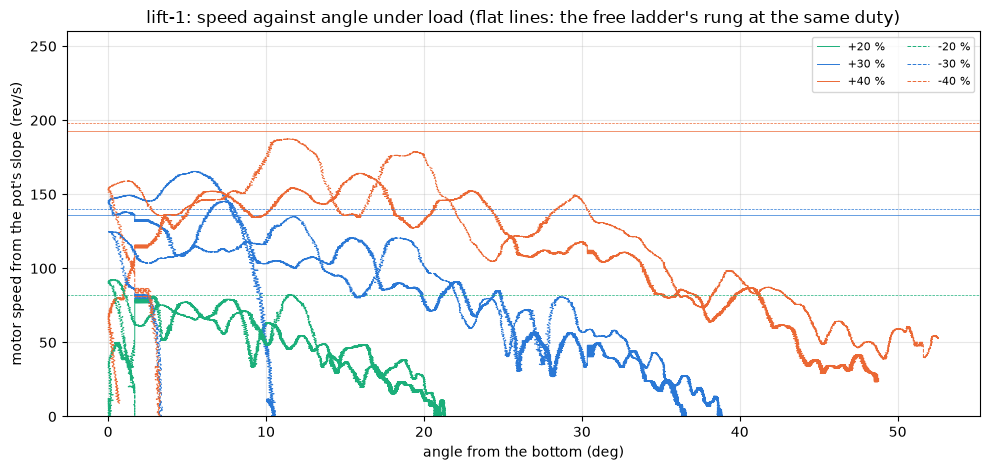

In [47]:
fig, ax = plt.subplots(figsize=(10, 4.8))
colors = {20: GREEN, 30: BLUE, 40: ORANGE}
for _, r in CYCLES[CYCLES["repeat"] == 0].iterrows():
    th, w = LIFT_TRACES[r["k"]]
    c, ls = colors[r["duty_pct"]], "-" if r["side"] > 0 else "--"
    ax.plot(th, w, lw=0.7, color=c, ls=ls,
            label=f"{r['side'] * r['duty_pct']:+d} %")
    free = FREE.get((r["duty_pct"], r["side"]))
    if free:
        ax.axhline(free[0], color=c, lw=0.5, ls=ls)
ax.set_ylim(0, 260)
figures.label(ax, x="angle from the bottom (deg)",
              y="motor speed from the pot's slope (rev/s)",
              title="lift-1: speed against angle under load (flat lines: "
              "the free ladder's rung at the same duty)")
ax.legend(fontsize=8, ncol=2)
figures.finish(fig)

What you are looking at. The motor's speed from the pot's slope against the angle while lifting, the first of each pair, up solid and down dashed, the flat lines the free ladder's rung at the same duty. The first degrees spin through the lash before the arm moves.

The loss grows with the angle, 53 to 56 rev/s at 20 degrees and 81 to 94 at 30 degrees for the up side's 30 and 40 %. The torque curve's prediction of the loss is $R_C (i_w - i_{c,\mathrm{free}}) / K_e$, with $R_C$ the resistance result's construction C value and both currents under construction C. Over the 20 and 30 degree windows it explains 0.79 to 0.89 of the loss on the up side, which loses 7.9 to 12.4 rev/s more than the prediction. On the down side it explains 0.93 to 1.21. There the loss less the prediction is -9.2 to -1.3 rev/s at 30 and 40 % and +2.3 and +5.5 at 20 %. The remainder takes opposite signs on the two sides at 30 and 40 %, which points at a term set by the direction of drive, the brush drop's direction term the candidate, low confidence. The 10 degree windows scatter from 0.68 to 1.44 and are left out of the number.

Lifting through 30 degrees the motor draws 214 to 235 mA, against 271 and 255 mA for the static from-below lines at 30 degrees, a ratio of 0.83 to 0.89. The moving arm draws less current than the one that just stuck, about the size of the lines' intercepts.

In [48]:
def fall_fit(j, tau_h, a, w, al):
    """J alpha + gravity = -T_c sgn(w) - b w by least squares, mN m: j the
    inertia at the output, tau_h gravity's torque at horizontal."""
    X = np.c_[-np.sign(w), -np.radians(w)]
    y = j * np.radians(al) * 1e3 + tau_h * np.sin(np.radians(a))
    coef = np.linalg.lstsq(X, y, rcond=None)[0]
    return coef, np.sqrt(((y - X @ coef) ** 2).mean())

In [49]:
SG_ROWS = 801           # rows, the 40 ms Savitzky-Golay window
FAST_DEG_S = 100        # deg/s, where the EMF and the pot are compared


def fall_row(k):
    _, f = FALL_ROWS[k]
    tf = np.arange(len(f)) / FS
    th = np.asarray(theta_deg(f["pos"], BOTTOM))      # signed
    a = savgol_filter(th, SG_ROWS, 3)
    w = savgol_filter(th, SG_ROWS, 3, deriv=1, delta=1 / FS)    # deg/s
    al = savgol_filter(th, SG_ROWS, 3, deriv=2, delta=1 / FS)   # deg/s2
    w_emf = f["emf_v"].to_numpy() / KE / (2 * np.pi) / GEAR * 360
    first = tf < 1.0
    ip = int(np.argmax(np.abs(w[first])))     # the speed's peak
    mm = (np.abs(w) > FAST_DEG_S) & first
    moving = np.flatnonzero(np.abs(w) > 10)
    stop = int(moving[-1]) if len(moving) else len(w) - 1
    mv = (np.abs(w) > 20) & first & (tf > 0.01)
    coef_c, _ = fall_fit(J_OUT, TAU_COINS, a[mv], w[mv], al[mv])
    coef, rms = fall_fit(J_TOTAL, TAU_H, a[mv], w[mv], al[mv])
    FALL_TRACES[k] = (tf, w, w_emf)
    return {"k": k, "w_peak": w[ip], "theta_peak": a[ip],
            "peak_coins": gravity_coins(a[ip]),
            "emf_ratio": (w_emf[mm].sum() / w[mm].sum()
                          if mm.sum() > 100 else np.nan),
            "coulomb_coins": coef_c[0], "viscous_coins": coef_c[1],
            "coulomb": coef[0], "viscous": coef[1],
            "fit_rms": rms,
            "recoil_deg": np.ptp(th[stop - 2000:stop])
            if stop > 2000 else np.nan,
            "stop_s": (stop + 1) / FS, "end_deg": th[-10000:].mean()}


FALL_TRACES = {}
FALL = CYCLES[["k", "side", "duty_pct", "repeat"]].merge(
    pd.DataFrame([fall_row(k) for k in CYCLES["k"]]), on="k")
show(FALL, n=None)

,k,side,duty_pct,repeat,w_peak,theta_peak,peak_coins,emf_ratio,coulomb_coins,viscous_coins,coulomb,viscous,fit_rms,recoil_deg,stop_s,end_deg
0,0,1,20,0,-84.377,15.911,22.948,NaN,10.186,7.971,12.441,9.423,16.310,1.052,0.458,4.660
1,1,1,20,1,-73.738,15.838,22.846,NaN,20.570,-2.539,24.965,-3.284,12.691,0.797,0.477,5.379
2,2,1,30,0,-160.784,16.148,23.281,1.005,10.737,6.837,12.808,8.289,19.879,1.138,0.637,-0.176
3,3,1,30,1,-165.283,16.376,23.601,0.999,13.841,5.466,16.861,6.486,20.519,0.860,0.581,-0.292
4,4,1,40,0,-232.425,22.681,32.278,1.023,4.564,8.642,5.614,10.365,23.337,0.636,0.718,-4.601
5,5,1,40,1,-240.679,22.765,32.391,1.024,3.058,8.894,3.717,10.700,23.917,0.888,0.684,-4.931
6,6,-1,20,0,94.565,-11.919,17.288,NaN,17.405,1.708,21.261,1.751,21.518,1.760,0.415,-5.944
7,7,-1,20,1,108.286,-18.705,26.844,0.644,14.342,4.630,17.388,5.459,23.310,0.888,0.450,-5.019
8,8,-1,30,0,204.649,-11.652,16.907,0.999,5.404,7.841,7.035,9.206,35.171,1.089,0.643,1.686
9,9,-1,30,1,208.024,-11.797,17.114,1.000,4.483,8.079,5.494,9.677,34.597,1.089,0.936,2.178


In [50]:
EMF_R = FALL["emf_ratio"].dropna()
print(f"EMF / Ke / N over the pot's speed above {FAST_DEG_S} deg/s: "
      f"{EMF_R.mean():.3f} +/- {EMF_R.std(ddof=1):.3f} (n {len(EMF_R)})")
FALL["peak_mn_m"] = FALL["peak_coins"] * SCALE   # gravity, exact
for _, r in FALL.iterrows():
    print(f"   {int(r['side'] * r['duty_pct']):+d} %: friction at the "
          f"speed peak {r['peak_mn_m']:.1f} mN m at "
          f"{abs(r['w_peak']):.0f} deg/s")
COULOMB, VISCOUS = FALL["coulomb"], FALL["viscous"]   # absolute
cc, vc = FALL["coulomb_coins"], FALL["viscous_coins"]
cm, cs = COULOMB.mean(), COULOMB.std(ddof=1)
vm, vs = VISCOUS.mean(), VISCOUS.std(ddof=1)
print(f"coins-scale: Coulomb {cc.mean():.1f} +/- {cc.std(ddof=1):.1f} mN m"
      f", viscous {vc.mean():.2f} +/- {vc.std(ddof=1):.2f} mN m s/rad")
print(f"absolute: Coulomb {cm:.1f} +/- {cs:.1f} mN m, viscous {vm:.2f} "
      f"+/- {vs:.2f} mN m s/rad, fit rms {FALL['fit_rms'].min():.0f} to "
      f"{FALL['fit_rms'].max():.0f} mN m")
print(f"viscous at the motor {vm / GEAR ** 2 * 1e3:.3f} uN m s/rad")
RECOIL = FALL["recoil_deg"]
print(f"recoil after the stop {RECOIL.min():.2f} to {RECOIL.max():.2f} "
      f"deg, mean {RECOIL.mean():.2f} (pot-table lash_hand "
      f"{LASH_HAND:.2f}); falls end "
      f"{FALL['end_deg'].abs().min():.1f} to "
      f"{FALL['end_deg'].abs().max():.1f} deg out, stop after "
      f"{FALL['stop_s'].min():.2f} to {FALL['stop_s'].max():.2f} s")

EMF / Ke / N over the pot's speed above 100 deg/s: 0.966 +/- 0.121 (n 9)
   +20 %: friction at the speed peak 27.6 mN m at 84 deg/s
   +20 %: friction at the speed peak 27.5 mN m at 74 deg/s
   +30 %: friction at the speed peak 28.0 mN m at 161 deg/s
   +30 %: friction at the speed peak 28.4 mN m at 165 deg/s
   +40 %: friction at the speed peak 38.8 mN m at 232 deg/s
   +40 %: friction at the speed peak 39.0 mN m at 241 deg/s
   -20 %: friction at the speed peak 20.8 mN m at 95 deg/s
   -20 %: friction at the speed peak 32.3 mN m at 108 deg/s
   -30 %: friction at the speed peak 20.3 mN m at 205 deg/s
   -30 %: friction at the speed peak 20.6 mN m at 208 deg/s
   -40 %: friction at the speed peak 48.1 mN m at 295 deg/s
   -40 %: friction at the speed peak 49.2 mN m at 293 deg/s
coins-scale: Coulomb 11.3 +/- 5.8 mN m, viscous 5.50 +/- 3.37 mN m s/rad
absolute: Coulomb 13.8 +/- 7.0 mN m, viscous 6.51 +/- 4.11 mN m s/rad, fit rms 13 to 35 mN m
viscous at the motor 0.069 uN m s/rad
recoil

In [51]:
rep = LIFT.merge(FALL[["k", "end_deg"]], on="k").groupby(
    ["side", "duty_pct"]).agg(w10=("w_10", np.ptp), top=("theta_top",
                                                          np.ptp),
                              end=("end_deg", np.ptp))
show(rep.reset_index(), n=None)
REPEAT = rep

,side,duty_pct,w10,top,end
0,-1,20,3.248,1.826,0.925
1,-1,30,2.217,0.149,0.492
2,-1,40,63.920,0.759,0.308
3,1,20,1.834,0.226,0.719
4,1,30,4.962,0.424,0.116
5,1,40,5.915,0.385,0.329


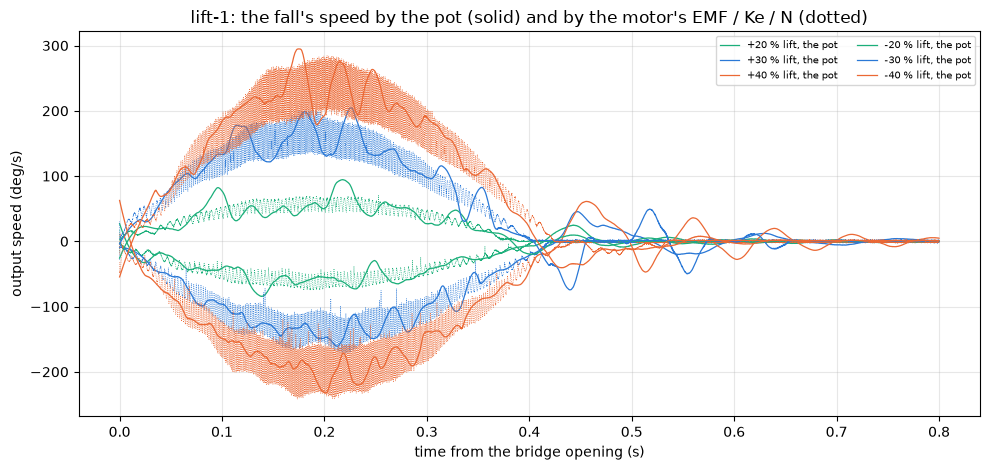

In [52]:
fig, ax = plt.subplots(figsize=(10, 4.8))
colors = {20: GREEN, 30: BLUE, 40: ORANGE}
for _, r in CYCLES[CYCLES["repeat"] == 0].iterrows():
    tf, w, w_emf = FALL_TRACES[r["k"]]
    m = tf < 0.8
    c = colors[r["duty_pct"]]
    ax.plot(tf[m], w[m], lw=0.9, color=c,
            label=f"{r['side'] * r['duty_pct']:+d} % lift, the pot")
    ax.plot(tf[m], w_emf[m], lw=0.5, ls=":", color=c)
figures.label(ax, x="time from the bridge opening (s)",
              y="output speed (deg/s)",
              title="lift-1: the fall's speed by the pot (solid) and by "
              "the motor's EMF / Ke / N (dotted)")
ax.legend(fontsize=7, ncol=2)
figures.finish(fig)

What you are looking at. The fall's output speed through the pot (solid) and through the motor's EMF over Ke and N (dotted), the first of each pair. The two agree through each fall, and the EMF drops to zero at the stop.

From 21 to 54 degrees the arm falls and stops 0.42 to 0.94 s after the bridge opens, the -30 % repeat k9 the 0.94. The 20 % falls stop on their own side, the 30 % falls at the bottom or just past it, and the 40 % falls on the far side. Above 100 deg/s the EMF over Ke and N tracks the pot's speed at 0.966 +/- 0.121 over 9 falls, so the train back-drives the motor at N times the output with no slip.

At the speed's peak the acceleration is zero and gravity's torque is the friction. Per fall it reads 27.6 and 27.5 mN m at 84 and 74 deg/s (+20 %), 28.0 and 28.4 at 161 and 165 (+30 %), 38.8 and 39.0 at 232 and 241 (+40 %), 20.8 and 32.3 at 95 and 108 (-20 %), 20.3 and 20.6 at 205 and 208 (-30 %) and 48.1 and 49.2 at 295 and 293 (-40 %). It grows with speed. A regression through each fall, $J \alpha + \tau \sin\theta = -T_c \,\mathrm{sgn}(\omega) - b \omega$, with $\tau$ here the torque at horizontal, $T_c$ the Coulomb term, $b$ the viscous one and $\omega$ ("omega") the speed, with the same absolute gravity and inertia, gives $T_c$ 13.8 +/- 7.0 mN m and $b$ 6.51 +/- 4.11 mN m s/rad, 0.069 uN m s/rad at the motor, low confidence, with a fit rms of 13 to 35 mN m.

After the stop the pot recoils 0.64 to 2.46 degrees, mean 1.24, while the EMF reads zero. That is the output turning back inside the lash with the motor still, and it matches the pot table's hand rock of 1.24 degrees. The two repeats agree to 0.12 to 0.93 degrees at the fall's end and 0.15 to 1.83 degrees at the top, and to 1.8 to 5.9 rev/s at 10 degrees, except the -40 % pair, which started at 1.7 and 7.1 degrees.

## 8. The stall current per duty

Every settled rung of 6 % or more with a valid window, the three stop rungs included since they are stalls too, both as read and under construction C.

In [53]:
ST = R[R["stalled"] & (R["window_valid"] > 0.99)
       & (R["duty_pct"] >= 6)].copy()
FA = results.fit_line(ST["v_a_v"], ST["i_crest_a"])   # as read
FC = results.fit_line(ST["i_w_a"], ST["v_c_v"])       # construction C
ST["resid_mv"] = FC["resid"] * 1e3
print(f"as read: i = {FA['intercept'] * 1e3:+.1f} mA + "
      f"{FA['slope'] * 1e3:.1f} mA/V x D V_on, 1/slope "
      f"{1 / FA['slope']:.3f} ohm, rms {FA['rms'] * 1e3:.1f} mA, n "
      f"{FA['n']}")
V_ON = ST["v_on_v"].mean()
print(f"   = {FA['slope'] * V_ON / 100 * 1e3:.2f} mA per % at V_on "
      f"{V_ON:.2f} V; the resistance result's as-read line predicts "
      f"{1e3 / R_STOP_A:.1f} mA/V, {-V0_STOP_A / R_STOP_A * 1e3:+.1f} mA")
print(f"   the warm hold draws {(1 - FA['slope'] * R_STOP_A) * 100:.1f} % "
      f"under the cold line's slope")
print(f"C: v_c = {FC['intercept'] * 1e3:+.0f} mV + {FC['slope']:.3f} +/- "
      f"{FC['slope_se']:.3f} ohm x i_w, rms {FC['rms'] * 1e3:.0f} mV; "
      f"resistance C {R_C:.3f} ohm, {V0_C * 1e3:+.0f} mV")
for side in (1, -1):
    f = results.fit_line(ST[ST["side"] == side]["i_w_a"],
                         ST[ST["side"] == side]["v_c_v"])
    print(f"   side {side:+d}: {f['slope']:.3f} +/- {f['slope_se']:.3f} "
          f"ohm, {f['intercept'] * 1e3:+.0f} mV, n {f['n']}")

as read: i = +15.3 mA + 208.8 mA/V x D V_on, 1/slope 4.789 ohm, rms 4.5 mA, n 41
   = 10.00 mA per % at V_on 4.79 V; the resistance result's as-read line predicts 228.4 mA/V, -2.5 mA
   the warm hold draws 8.6 % under the cold line's slope
C: v_c = -82 mV + 4.538 +/- 0.032 ohm x i_w, rms 26 mV; resistance C 4.177 ohm, +31 mV
   side +1: 4.564 +/- 0.050 ohm, -94 mV, n 20
   side -1: 4.517 +/- 0.041 ohm, -71 mV, n 21


In [54]:
BAND = (16, 46)         # % of duty, the middle of the stall line
mid = ST[ST["duty_pct"].between(*BAND)]
RESID_BAND = mid["resid_mv"].abs().max()
TREND = results.fit_line(mid["duty_pct"], mid["resid_mv"])
TREND_SIGMA = abs(TREND["slope"] / TREND["slope_se"])
print(f"{BAND[0]} to {BAND[1]} %: |residual| at most {RESID_BAND:.1f} mV "
      f"(n {len(mid)}); trend {TREND['slope']:+.3f} +/- "
      f"{TREND['slope_se']:.3f} mV per %, {TREND_SIGMA:.1f} sigma")
for lo, hi in ((6, 14), (50, 54)):
    x = ST[ST["duty_pct"].between(lo, hi)]["resid_mv"]
    print(f"{lo} to {hi} %: residuals {x.min():+.0f} to {x.max():+.0f} mV"
          f", mean {x.mean():+.0f} (n {len(x)})")

16 to 46 %: |residual| at most 37.9 mV (n 29); trend +0.425 +/- 0.355 mV per %, 1.2 sigma
6 to 14 %: residuals -3 to +38 mV, mean +21 (n 9)
50 to 54 %: residuals +25 to +79 mV, mean +50 (n 3)


As read, the 41 rungs sit on one line, $i = 15.3 \,\mathrm{mA} + 208.8 \,\mathrm{mA/V} \times D V_\mathrm{on}$, rms 4.5 mA, 1 / slope 4.789 ohm. At 5 V that is 10.00 mA per % of duty after a 3 s hold. The resistance result's as-read line predicts 228.4 mA/V, so the warm hold draws 8.6 % under the cold line's slope.

Under construction C the line is $V_c = -82 \,\mathrm{mV} + 4.538 \,\Omega \times i_w$, +/- 0.032 ohm, rms 26 mV, the sides 4.564 and 4.517 ohm. Over 16 to 46 % its residuals lie within +/- 37.9 mV with no trend in duty, 1.2 sigma. They bow up at both ends, a mean of +21 mV over 6 to 14 % and +50 mV over 50 to 54 %.

In [55]:
X3 = np.c_[np.ones(len(ST)), ST["i_w_a"], ST["i_w_a"] ** 3]
CUBIC, *_ = np.linalg.lstsq(X3, ST["v_c_v"], rcond=None)
res3 = ST["v_c_v"] - X3 @ CUBIC
cov3 = (res3 ** 2).sum() / (len(ST) - 3) * np.linalg.inv(X3.T @ X3)
CUBIC_SE = np.sqrt(np.diag(cov3))
V0_3, R0_3, C_3 = CUBIC
WARM_CUBIC = C_3 * 0.5 ** 2 / R0_3      # share of R0 at 0.5 A
print(f"v_c = V0 + R0 i + c i^3: V0 {V0_3 * 1e3:+.0f} +/- "
      f"{CUBIC_SE[0] * 1e3:.0f} mV, R0 {R0_3:.3f} +/- {CUBIC_SE[1]:.3f} "
      f"ohm, c {C_3:.2f} +/- {CUBIC_SE[2]:.2f} ohm/A^2; rms "
      f"{np.sqrt((res3 ** 2).mean()) * 1e3:.0f} mV")
print(f"at 0.5 A the cubic term is {WARM_CUBIC * 100:.1f} % of R0, "
      f"{WARM_CUBIC / ALPHA_CU:.0f} C of copper")

v_c = V0 + R0 i + c i^3: V0 -21 +/- 7 mV, R0 4.110 +/- 0.041 ohm, c 1.64 +/- 0.14 ohm/A^2; rms 12 mV
at 0.5 A the cubic term is 10.0 % of R0, 26 C of copper


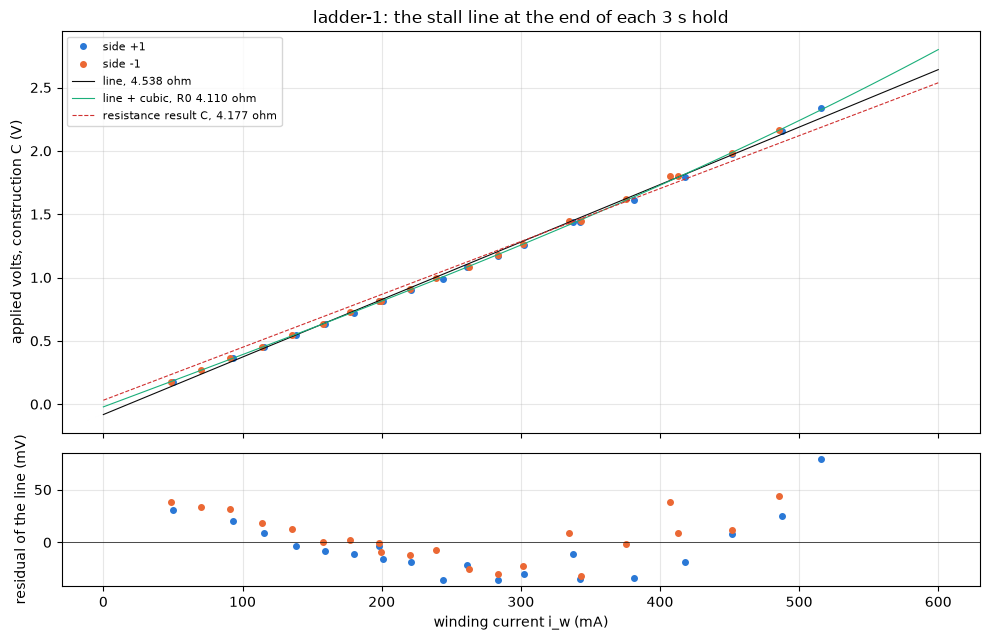

In [56]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})
xx = np.linspace(0, 0.6, 50)
for side, color in ((1, BLUE), (-1, ORANGE)):
    d = ST[ST["side"] == side]
    ax1.plot(d["i_w_a"] * 1e3, d["v_c_v"], "o", ms=4, color=color,
             label=f"side {side:+d}")
    ax2.plot(d["i_w_a"] * 1e3, d["resid_mv"], "o", ms=4, color=color)
ax1.plot(xx * 1e3, FC["intercept"] + FC["slope"] * xx, color=INK, lw=0.8,
         label=f"line, {FC['slope']:.3f} ohm")
ax1.plot(xx * 1e3, V0_3 + R0_3 * xx + C_3 * xx ** 3, color=GREEN, lw=0.8,
         label=f"line + cubic, R0 {R0_3:.3f} ohm")
ax1.plot(xx * 1e3, V0_C + R_C * xx, **figures.HIGHLIGHT_STYLE,
         label=f"resistance result C, {R_C:.3f} ohm")
ax2.axhline(0, color=INK, lw=0.5)
figures.label(ax1, y="applied volts, construction C (V)",
              title="ladder-1: the stall line at the end of each 3 s hold")
figures.label(ax2, x="winding current i_w (mA)",
              y="residual of the line (mV)")
ax1.legend(fontsize=8)
figures.finish(fig)

What you are looking at. The applied volts under construction C against the winding current at the end of each hold (top), the straight line, the line with a cubic term and the resistance result's C line, and the straight line's residuals (bottom).

A term $c i^3$ for warming over the fixed 3 s hold takes the rms to 12 mV with $R_0$ 4.110 +/- 0.041 ohm, $V_0$ -21 +/- 7 mV and $c$ 1.64 +/- 0.14 ohm/A^2, 10.0 % of $R_0$ at 0.5 A. Against the resistance result's 4.177 ohm and +31 mV, the end-of-hold line is steeper and the cubic's cold $R_0$ is lower. Two readings of the bow stay open. One is warming through the hold. The other is the crest term $g$ taken below the duty band it was measured over, where it is a large share of a small current.

bottom-1  26.26 -> 26.39 C over minutes 0 to 3; rail probe 4.985 V sd 0.011
ladder-1  26.46 -> 26.84 C over minutes 3 to 43; rail probe 4.988 V sd 0.008
lift-1    26.72 -> 26.97 C over minutes 44 to 53; rail probe 4.987 V sd 0.009
steps-1   26.99 -> 27.08 C over minutes 54 to 63; rail probe 4.986 V sd 0.008
sitting: 26.26 -> 27.08 C, +0.82 C over 63 min; ladder up side 26.35 C, down side 26.58 C


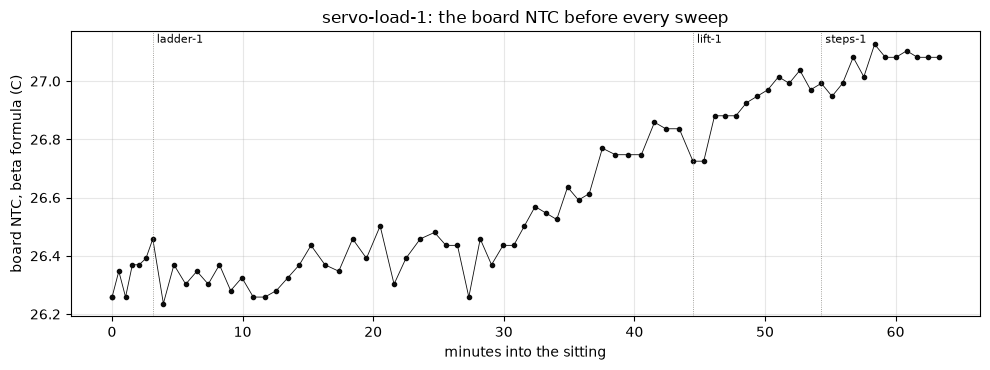

In [57]:
P = PROBES.copy()
P["minutes"] = (P["t_host"] - P["t_host"].min()) / 60
blocks = ("bottom-1", "ladder-1", "lift-1", "steps-1")
for blk in blocks:
    d = P[P["folder"].str.startswith(blk)]
    print(f"{blk:9s} {d['ntc_c'].iloc[0]:.2f} -> {d['ntc_c'].iloc[-1]:.2f}"
          f" C over minutes {d['minutes'].iloc[0]:.0f} to "
          f"{d['minutes'].iloc[-1]:.0f}; rail probe {d['rail_v'].mean():.3f}"
          f" V sd {d['rail_v'].std():.3f}")
NTC_OPEN, NTC_CLOSE = P["ntc_c"].iloc[0], P["ntc_c"].iloc[-1]
print(f"sitting: {NTC_OPEN:.2f} -> {NTC_CLOSE:.2f} C, "
      f"{NTC_CLOSE - NTC_OPEN:+.2f} C over {P['minutes'].max():.0f} min; "
      f"ladder up side {R[R['side'] == 1]['ntc_c'].mean():.2f} C, down "
      f"side {R[R['side'] == -1]['ntc_c'].mean():.2f} C")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(P["minutes"], P["ntc_c"], "o-", ms=3, color=INK, lw=0.6)
for blk in blocks[1:]:
    t0 = P[P["folder"].str.startswith(blk)]["minutes"].iloc[0]
    ax.axvline(t0, **figures.EDGE_STYLE)
    ax.text(t0, NTC_CLOSE + 0.05, f" {blk}", fontsize=8)
figures.label(ax, x="minutes into the sitting",
              y="board NTC, beta formula (C)",
              title="servo-load-1: the board NTC before every sweep")
figures.finish(fig)

What you are looking at. The board NTC at each probe through the sitting, the blocks marked. It read 26.26 C at the first probe and 27.08 C at the last, +0.82 C over 63 minutes. The ladder's up side ran at 26.35 C on average and its down side, run after it, at 26.58 C.

In [58]:
start = []
for _, r in R.iterrows():
    df, _ = load_sweep(DATA / "ladder-1" / f"ladder/{int(r['k'])}")
    s1 = df[df["seg"] == sorted(df["seg"].unique())[1]].reset_index()
    e = tel.drive_start(s1)                 # the duty's first row
    early = s1.iloc[e + 40:e + 100]          # 2 to 5 ms after the edge
    start.append({"k": r["k"], "i_start_a": early["i_a"].mean(),
                  "move_5ms": s1["pos"].iloc[e + 100] - s1["pos"].iloc[e]})
W = R.merge(pd.DataFrame(start), on="k")
W["start_over_end"] = W["i_start_a"] / W["i_crest_a"]
below = W[(W["approach"] == "below") & (W["duty_pct"] >= 6)]
for name, d in (("moved", below[below["moved"]]),
                ("never moved", below[~below["moved"]])):
    x = (1 - d["start_over_end"]) * 100
    print(f"{name:11s}: start under end by {x.min():+.1f} to "
          f"{x.max():+.1f} % (n {len(d)})")
print("over end: " + ", ".join(
    f"k{int(r['k'])} {r['start_over_end']:.4f}"
    for _, r in below[below["start_over_end"] >= 1].iterrows()))

moved      : start under end by -0.1 to +14.6 % (n 33)
never moved: start under end by +3.0 to +7.0 % (n 4)
over end: k28 1.0007


In [59]:
C0 = W[(W["duty_pct"] >= 6) & (W["move_5ms"].abs() <= 2)].copy()
C0["v_c0"], C0["i_w0"] = construction_c(
    C0["D"].to_numpy(), C0["v_on_v"].to_numpy(), C0["i_start_a"].to_numpy())
F0 = results.fit_line(C0["i_w0"], C0["v_c0"])
print(f"start currents, construction C: {F0['slope']:.3f} +/- "
      f"{F0['slope_se']:.3f} ohm, {F0['intercept'] * 1e3:+.0f} mV, rms "
      f"{F0['rms'] * 1e3:.0f} mV, n {F0['n']}")

start currents, construction C: 4.774 +/- 0.120 ohm, -34 mV, rms 82 mV, n 28


The winding as its own thermometer. The current 2 to 5 ms into each hold, with the copper at its rest temperature, against the current at its end, 3.1 s later, would give the warming over the hold. It does not work here. The start reads under the end by -0.1 to +14.6 % at every duty that moved the arm but one, the 14 % down rung k28, equal at 1.0007, and by 3.0 to 7.0 % on the four rungs that never moved. The motor spins through its lash at the start of a hold that moves the arm, and its EMF holds the current down while it does. The start currents' own line has an rms of 82 mV.

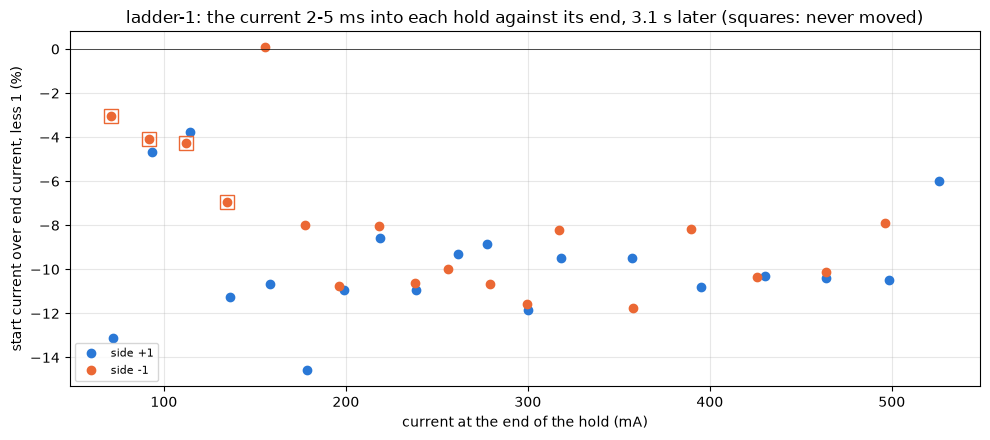

In [60]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for side, color in ((1, BLUE), (-1, ORANGE)):
    d = below[below["side"] == side]
    ax.plot(d["i_crest_a"] * 1e3, (d["start_over_end"] - 1) * 100,
            "o", color=color, label=f"side {side:+d}")
    n = d[~d["moved"]]
    ax.plot(n["i_crest_a"] * 1e3, (n["start_over_end"] - 1) * 100,
            "s", mfc="none", ms=10, color=color)
ax.axhline(0, color=INK, lw=0.5)
figures.label(ax, x="current at the end of the hold (mA)",
              y="start current over end current, less 1 (%)",
              title="ladder-1: the current 2-5 ms into each hold against "
              "its end, 3.1 s later (squares: never moved)")
ax.legend(fontsize=8)
figures.finish(fig)

What you are looking at. Each hold's start current over its end current, less 1, against the end current, the squares the rungs that never moved. Almost every hold that moved the arm starts low, the lash spin, so the figure shows that effect and not the warming.

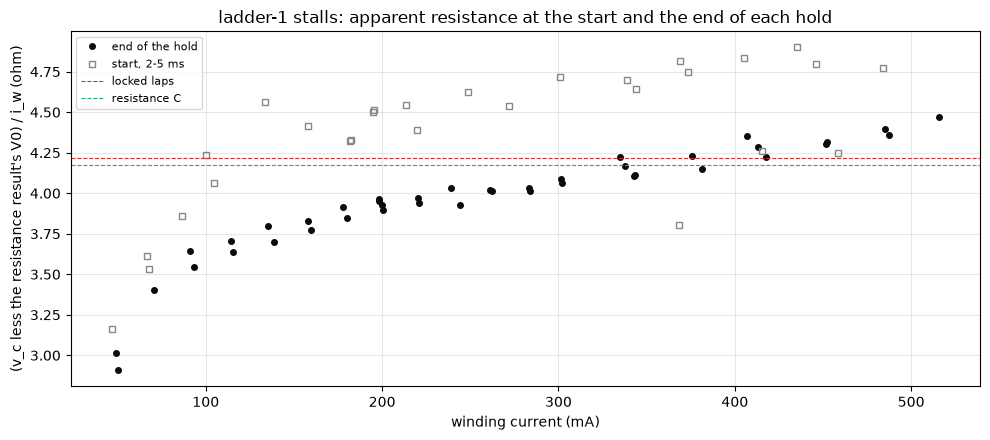

In [61]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(ST["i_w_a"] * 1e3, (ST["v_c_v"] - V0_C) / ST["i_w_a"], "o",
        ms=4, color=INK, label="end of the hold")
ax.plot(C0["i_w0"] * 1e3, (C0["v_c0"] - V0_C) / C0["i_w0"], "s",
        ms=4, mfc="none", color=MUTED, label="start, 2-5 ms")
ax.axhline(R_LOCKED, **figures.HIGHLIGHT_STYLE, label="locked laps")
ax.axhline(R_C, color=GREEN, lw=0.8, ls="--", label="resistance C")
figures.label(ax, x="winding current (mA)",
              y="(v_c less the resistance result's V0) / i_w (ohm)",
              title="ladder-1 stalls: apparent resistance at the start and "
              "the end of each hold")
ax.legend(fontsize=8)
figures.finish(fig)

What you are looking at. The apparent resistance at the start and at the end of each hold, the resistance result's V0 taken off, against the locked laps' 4.219 ohm and construction C's 4.177. The end of a hold reads high and the starts scatter wide.

In [62]:
# the resistance notebook's meter holds as the analysis note reads them:
# the crest fell about 2.2 % over 2.5 s at about 0.37 A
METER_FALL, METER_A, METER_S = 0.022, 0.37, 2.5
HOLD_A, HOLD_S = 0.5, 3.0              # the ladder's top holds
meter_scaled = METER_FALL * (HOLD_A / METER_A) ** 2 * HOLD_S / METER_S
print(f"meter fall {METER_FALL * 100:.1f} % at {METER_A} A over {METER_S} "
      f"s, scaled by i^2 and time to {HOLD_A} A over {HOLD_S} s: "
      f"{meter_scaled * 100:.1f} % = {meter_scaled / ALPHA_CU:.0f} C; the "
      f"cubic {WARM_CUBIC * 100:.1f} % = {WARM_CUBIC / ALPHA_CU:.0f} C; "
      f"heating tau {TAU_HEAT_S:.1f} s")
m = R[(R["approach"] == "below") & R["duty_pct"].between(14, 46)]
p = m.pivot_table(index="duty_pct", columns="side", values="i_crest_a")
SIDE_I = (p[-1] / p[1]).dropna()
R_FWD = RES["r_term_by_direction_ohm_fwd"]["value"]
R_REV = RES["r_term_by_direction_ohm_rev"]["value"]
print(f"end current down over up, 14 to 46 %: {SIDE_I.mean():.4f} sd "
      f"{SIDE_I.std(ddof=1):.4f} = {(1 / SIDE_I.mean() - 1) / ALPHA_CU:+.1f}"
      f" C as warming; locked laps R_fwd / R_rev {R_FWD / R_REV:.4f}")

meter fall 2.2 % at 0.37 A over 2.5 s, scaled by i^2 and time to 0.5 A over 3.0 s: 4.8 % = 12 C; the cubic 10.0 % = 26 C; heating tau 3.4 s
end current down over up, 14 to 46 %: 0.9937 sd 0.0080 = +1.6 C as warming; locked laps R_fwd / R_rev 1.0045


What is left for the warming. The cubic says 10.0 % at 0.5 A, 26 C of copper. The resistance notebook's meter holds fell about 2.2 % over 2.5 s at about 0.37 A, which scales by $i^2$ and time to 4.8 % at 0.5 A over 3 s, 12 C, against a heating time constant of 3.4 s. So a 3 s hold at 0.5 A warms the winding by somewhere from 12 to 26 C, low confidence. The design line holds either way. A servo holding a load at 5 V draws 10.00 mA per % after 3 s and 15.3 mA at zero duty by the line, under the cold line, so a stall threshold set from the cold line sits above a warm hold's current.

Warming does not explain the side split. The down side's end currents at matched duty are 0.9937 of the up side's, sd 0.0080, 1.6 C if read as warming, and the locked laps split the two directions by 1.0045. Either way it is current, and the split in question is torque per amp.

## 9. The pot under load

The push block did not run, so what this sitting gives is bounds.

In [63]:
st = STEPS[STEPS["edge"] == "step"].dropna(subset=["d_theta"])
up5, dn5 = st[st["step_pct"] > 0], st[st["step_pct"] < 0]
for name, x in (("+5 %", up5), ("-5 %", dn5)):
    print(f"{name}: pot moved {x['d_theta'].round(2).tolist()} deg, mean "
          f"{x['d_theta'].mean():+.3f} se "
          f"{x['d_theta'].std(ddof=1) / np.sqrt(len(x)):.3f}")
POT_DIFF = up5["d_theta"].mean() - dn5["d_theta"].mean()
POT_SE = np.hypot(up5["d_theta"].std(ddof=1) / np.sqrt(len(up5)),
                  dn5["d_theta"].std(ddof=1) / np.sqrt(len(dn5)))
POT_BOUND = st["d_theta"].abs().max()
print(f"(+5) less (-5): {POT_DIFF:+.3f} +/- {POT_SE:.3f} deg, "
      f"{abs(POT_DIFF / POT_SE):.1f} sigma; bound {POT_BOUND:.2f} deg")
rest = USE
fn = results.fit_line(rest["tau_mn_m"], rest["rest_sd"])
print(f"pot sd at rest {rest['rest_sd'].mean():.2f} counts, against the "
      f"held torque {fn['slope']:+.4f} +/- {fn['slope_se']:.4f} counts per"
      f" mN m ({abs(fn['slope'] / fn['slope_se']):.1f} sigma); up side "
      f"{rest[rest['side'] == 1]['rest_sd'].mean():.2f}, down "
      f"{rest[rest['side'] == -1]['rest_sd'].mean():.2f}")
smooth = POT["table_smooth_rms_counts"]["value"]
print(f"the table's smooth part {smooth:.0f} counts rms, "
      f"{smooth / POT['pot_scale_counts_per_deg']['value']:.1f} deg; the "
      f"bottom's bracket {abs(theta_deg(BOTTOM_HI, BOTTOM_LO)):.1f} deg")

+5 %: pot moved [0.06, -0.15, -0.33, 0.05, -0.09] deg, mean -0.094 se 0.073
-5 %: pot moved [-0.13, 0.05, 0.07, 0.0, 0.06] deg, mean +0.012 se 0.037
(+5) less (-5): -0.106 +/- 0.082 deg, 1.3 sigma; bound 0.33 deg
pot sd at rest 1.04 counts, against the held torque +0.0008 +/- 0.0023 counts per mN m (0.4 sigma); up side 1.28, down 0.74
the table's smooth part 12 counts rms, 0.7 deg; the bottom's bracket 0.9 deg


Under the +/- 5 % steps the output stayed still while the current changed by 47 to 53 mA. The pot moved -0.094 degrees on average for +5 % and +0.012 for -5 %, a difference of -0.106 +/- 0.082 degrees, 1.3 sigma, not a finding. A torque-to-reading coupling is at most 0.33 degrees per step of 5 %. The pot's sd at rest is 1.04 counts and does not change with the held torque, 0.4 sigma. It is 1.28 counts on the up side and 0.74 on the down, a split this sitting leaves open.

The recoil after every fall, 1.24 degrees with zero EMF, is the lash seen from the pot, as the pot table's hand rock found. A radial-load term that turns with the arm is not separated here from the table's own smooth part, 12 counts rms, 0.7 degrees, or from the bottom's 0.9 degree bracket. The push block is the measurement.

## 10. The end-stop rungs, the capture and what comes next

### The rungs past the soft limits

The ladder's top was 75 degrees, and both sides ran one rung past horizontal. Three rungs rested against something past the soft limits for 3 s with the duty never folded, since the experiment image's open-loop hold has no soft-limit guard.

In [64]:
STOPS = R[R["past_soft"]].copy()
STOPS["to_end"] = np.where(STOPS["rest_pos"] > 2048,
                           SERVO_ENDS[1] - STOPS["rest_pos"],
                           STOPS["rest_pos"] - SERVO_ENDS[0])
show(STOPS[["k", "side", "duty_pct", "approach", "rest_pos", "to_end",
            "rest_range", "i_crest_a", "duty_ticks", "duty_ticks_cmd"]],
     n=None)
print(f"soft limits {SOFT}, free ends {SERVO_ENDS}; lap cap "
      f"{SERVO.lap_cap_a} A, held-stall cap {SERVO.stop_hold_a} A; over the"
      f" lap cap: {int((STOPS['i_crest_a'] > SERVO.lap_cap_a).sum())} of "
      f"{len(STOPS)}")

,k,side,duty_pct,approach,rest_pos,to_end,rest_range,i_crest_a,duty_ticks,duty_ticks_cmd
19,19,1,54,below,3753.000,39.000,8,0.526,648.000,648
41,41,-1,50,below,196.000,114.000,3,0.496,600.000,600
44,44,-1,42,above,247.000,165.000,2,0.420,504.000,504


soft limits (314, 3560), free ends (82, 3792); lap cap 0.45 A, held-stall cap 0.5 A; over the lap cap: 2 of 3


k19 at 54 % rested at 3753 counts, 39 from the high free end, at 0.526 A. k41 at 50 % rested at 196, 114 from the low free end, at 0.496 A. k44 at 42 % from above rested at 247, 165 from it, at 0.420 A. Whether each sat on the hard stop or in the pot's end region, the data do not say. Two of the three ran above the README's 0.45 A lap cap for 3 s into the plastic output stopper, so the free ends want a re-read at the stops. Sitting 2 ran before one.

In [65]:
import json  # noqa: E402

ONE = sorted(DATA.glob("*-1/**/meta.json"))    # sitting 1's blocks
metas = [json.loads(p.read_text()) for p in ONE]
dropped = sum(m["rows_dropped"] for m in metas)
limit = {m["drive"]["current_limit_counts"] for m in metas}
peak = 0
for _, r in R.iterrows():
    df, _ = load_sweep(DATA / "ladder-1" / f"ladder/{int(r['k'])}")
    peak = max(peak, (df["current_raw"] - df["zero_i"]).abs().max())
rails = PROBES["rail_v"]
print(f"{len(metas)} sweeps, rows dropped {dropped}; current limit "
      f"{limit} counts, the ladder's largest current over its zero "
      f"{peak:.0f} counts; rail probe {rails.mean():.3f} +/- "
      f"{rails.std():.3f} V")

75 sweeps, rows dropped 0; current limit {942} counts, the ladder's largest current over its zero 653 counts; rail probe 4.987 +/- 0.008 V


### The capture itself

All 75 sweeps dropped no rows. The current limit stayed at 942 counts and the ladder's largest current over its zero was 653, so the limit never engaged. The rail probe read 4.987 +/- 0.008 V before every sweep.

- The bottom's 12 % for 1.5 s lifts the arm only to 9.5 degrees, inside the static band, so no drop happened. The lifts' falls from 21 degrees did fall, so a drop needs a start past about 20 degrees.
- The ladder's from-above step of 6 % sits inside the deadband, so the arm never fell after the step down.
- The ladder's top of 75 degrees let each side run one rung past horizontal into the stops.
- The steps of 5 % sit inside the deadband, so the block recorded current steps and no motion.
- The pot table stops short of the ladder's top rests on both sides and of the guards, so the end slope carries the angle there.
- The 4 % rungs sit under the current window floor and the 6 % rungs under the tap floor.
- The seek to the start leaves the arm at a friction rest anywhere from -12.5 to +13.2 degrees, so the low rungs depend on which side the arm sat.
- The up side ran first and the down side after it, so direction and time are confounded in the ladder.

### The next sitting's plan

Sitting 2 runs on the plan as committed on the `load-plan-2` branch and documented in the README's `load` section.

- The bottom lifts at 20 % for 1 s, so the arm starts past the static band. The lifts' falls from 21 degrees did fall.
- The ladder alternates the sides at each duty, stops a side once a rest passes 60 degrees and leaves out a rung the last two rests predict past 80, so no hold runs to a stop.
- The from-above rungs go 16 % over, then walk down a stair of 2 % every 300 ms onto the duty.
- The steps go 10, 15 and 20 % at two angles a side, so the first size that moves the arm brackets the band.
- The coins sit in the inner cup pair, 41.57 mm out, a second torque that checks the arm's term and the deadband.

Sittings 2 and 3 ran this plan with the coins in the inner pair, sitting 3 with the one-step from-above approach and the larger steps of the plan on disk, and section 11 reads them.

## 11. The inner cup pair: sittings 2 and 3

Sittings `servo-load-2` and `servo-load-3` ran on the same rig with the same arm, the 22 quarters moved from the outer cup pair to the inner one. Two masses on one train separate the arm's own term from Kt through the gears, and a second sitting at the same mass repeats the first. The blocks are `bottom-2`, `ladder-2`, `lift-2` and `steps-2`, the same with `-3`, and the manifests `sittings/servo-load-2.csv` and `sittings/servo-load-3.csv`. Sections 1 to 9 read sitting 1 alone and stay as they are. This section reads the three sittings with sitting 1's helpers (`load_sweep`, `rung_row`, `torque_line`) and recomputes sitting 1 wherever it compares.

### 11.1 The setup

The manifests give each sitting's bottom of record, the hand hang, and its guards. The coins' torque at horizontal comes from the rig's CAD radius of each cup pair, the arm's own term from the weighing in section 1.

In [66]:
import re  # noqa: E402

SITTINGS = (1, 2, 3)


def sitting_log(n):
    """(events, probes) of the manifest of sitting servo-load-n."""
    ev = pd.read_csv(PAIR_DIR / "sittings" / f"servo-load-{n}.csv")
    pr = ev[ev["event"] == "probe"]["detail"].str.extract(
        r"(.+?): pos (\d+), ntc_raw (\d+), vbus_raw (\d+)")
    probes = pd.DataFrame({
        "t_host": ev.loc[pr.index, "t_host"], "pos": pr[1].astype(int),
        "ntc_c": BOARD.ntc_c_beta(pr[2].astype(int)),
        "rail_v": SC.rail_v(pr[3].astype(int)),
        "folder": pr[0].str.replace(f"telemetry/{PAIR}/load/", "",
                                    regex=False)})
    return ev, probes


def hand_bottom(ev):
    """The bottom of record: the hand hang's probe, or the bottom the
    sitting was given from that hang."""
    text = " ".join(ev["detail"].fillna(""))
    hit = (re.search(r"hanging: pos (\d+)", text)
           or re.search(r"bottom (\d+) counts from OSC_LOAD_BOTTOM", text))
    return int(hit[1])


def probe_in(n):
    """Sitting n's probe lookup; a retried sweep probes twice and the
    last probe is the one that ran."""
    probes = LOGS[n][1]

    def look(folder_rel):
        hit = probes[probes["folder"] == folder_rel]
        return None if hit.empty else hit.iloc[-1]
    return look

In [67]:
LOGS = {n: sitting_log(n) for n in SITTINGS}
INNER_R_MM, OUTER_R_MM = RIG.stack_radii()[0], RIG.stack_radii()[1]
SITS = pd.DataFrame(index=pd.Index(SITTINGS, name="sitting"))
SITS["cups"] = ["outer", "inner", "inner"]
SITS["r_mm"] = [OUTER_R_MM, INNER_R_MM, INNER_R_MM]
SITS["bottom"] = [hand_bottom(LOGS[n][0]) for n in SITTINGS]
SITS["tau_coins"] = torque_mn_m(COINS_G, SITS["r_mm"])  # at horizontal
SITS["tau_h"] = SITS["tau_coins"] + TAU_ARM    # mN m, with the arm
# kg m2 at the output: coins, the arm as point masses, rotor and train
SITS["j_out"] = (COINS_G / 1e3 * (SITS["r_mm"] / 1e3) ** 2 + J_ARM
                 + J_REFL)
for n in SITTINGS:
    g = LOGS[n][0].loc[LOGS[n][0]["event"] == "guards", "detail"]
    SITS.loc[n, "guards"] = g.iloc[0]
show(SITS.assign(j_out_g_m2=SITS["j_out"] * 1e3).drop(columns="j_out"))
print(f"the arm's own {TAU_ARM:.2f} mN m (weighed), the reflected rotor "
      f"and train {J_REFL * 1e3:.3f} g m2; sitting 1's sections use the "
      f"bottom {BOTTOM:.0f}, this section {SITS.loc[1, 'bottom']}")

,cups,r_mm,bottom,tau_coins,tau_h,guards,j_out_g_m2
sitting,,,,,,,
1,outer,68.430,2024,83.709,100.747,414 to 3460 counts,1.283
2,inner,41.570,2025,50.852,67.890,414 to 3460 counts,0.914
3,inner,41.570,2025,50.852,67.890,414 to 3460 counts,0.914


the arm's own 17.04 mN m (weighed), the reflected rotor and train 0.610 g m2; sitting 1's sections use the bottom 2021, this section 2024


The coins' torque at horizontal drops from 83.71 mN m in the outer pair to 50.85 in the inner pair at 41.57 mm, and with the arm's 17.04 the totals are 100.75 and 67.89. The inertia at the output drops from 1.283 to 0.914 g m2, the coins and the arm's parts as point masses plus the rotor and train's 0.610. The bottoms of record are the hand hangs, 2024, 2025 and 2025 counts. Sitting 1's sections use 2021, the 12 % rests' degree midpoint, and this section re-reads sitting 1 at its hang so the three sittings share one rule. Section 11.2 prints how little that moves.

In [68]:
KEEP = ["rail", "found", "given", "retry", "skip"]
for n in (2, 3):
    ev = LOGS[n][0]
    sizes = pd.read_csv(DATA / f"steps-{n}" / "chains.csv")["step_pct"]
    steps = sorted(int(x) for x in sizes.abs().unique())
    print(f"sitting {n}: step sizes {steps} %")
    for _, e in ev[ev["event"].isin(KEEP)].iterrows():
        print(f"  {e['event']}: {e['detail']}")

sitting 2: step sizes [10, 15, 20] %
  rail: 5.0 V: reads 5.011 V, DPS 5.250 V
  found: bottom 2004 counts, the drops rest 318.7 counts apart, hanging it read 2025
  skip: 16 % stepped -20 % is out of range
sitting 3: step sizes [10, 15, 20, 25] %
  rail: 5.0 V: reads 5.001 V, DPS 5.250 V
  given: bottom 2025 counts from OSC_LOAD_BOTTOM, no hang prompt
  found: bottom 2025 counts by hand; the drops rest 422.0 counts apart about 2056
  skip: from above at +34 %: no overshoot of 10 % or more rests under 65 deg
  skip: from above at -24 %: no overshoot of 10 % or more rests under 65 deg
  skip: from above at -28 %: no overshoot of 10 % or more rests under 65 deg
  retry: 1: the sweep failed, the arm settling, once more
  skip: 16 % stepped -20 % is out of range
  skip: 16 % stepped -25 % is out of range
  skip: 16 % stepped -20 % is out of range
  skip: 16 % stepped -25 % is out of range


The two inner-pair sittings ran different plans. Sitting 2 worked from the drops' count midpoint, 2004, for its guards and nominal degrees, walked its from-above rungs down a stair onto the duty (section 11.6) and stepped by 10, 15 and 20 %. Sitting 3 was given the hand bottom 2025, approached from above by one step down from a predicted overshoot and stepped by 10, 15, 20 and 25 %. It retried one failed sweep once. Both left out the steps that would have taken a 16 % hold past -20 %, and sitting 3 left out three from-above rungs whose overshoot the plan predicted under 65 degrees.

### 11.2 The torque curve with two masses

Every rung of the three ladders goes through sitting 1's `rung_row`. The gates are section 4's with one more, a current window valid over 99 % of the rest. Under the tap floor $V_{on}$ comes from each sitting and side's own line on current, as in section 4.

In [69]:
def ladder_rows(n):
    """Every rung of sitting n's ladder through sitting 1's rung_row."""
    block = f"ladder-{n}"
    lad = pd.read_csv(DATA / block / "ladder.csv")
    rows = [rung_row(r, block, lad, probe_in(n)) for _, r in lad.iterrows()]
    out = pd.DataFrame(rows)
    out.insert(0, "sitting", n)
    return out


LAD = pd.concat([ladder_rows(n) for n in SITTINGS], ignore_index=True)
LAD = LAD.sort_values(["sitting", "k"]).reset_index(drop=True)
print(LAD.groupby(["sitting", "approach"]).size().unstack().to_string())

approach  above  below
sitting               
1             6     39
2             6     29
3             3     29


In [70]:
I_VALID = 0.99          # share of valid current windows over the rest

bottoms = LAD["sitting"].map(SITS["bottom"])
LAD["theta"] = theta_deg(LAD["rest_pos"], bottoms)
LAD["outside_table"] = outside_table(LAD["rest_pos"])
LAD["past_soft"] = (LAD["rest_pos"] < SOFT[0]) | (LAD["rest_pos"] > SOFT[1])
LAD["moved"] = (LAD["rest_pos"] - LAD["first_pos"]).abs() > MOVE_COUNTS
LAD["stalled"] = ((LAD["rest_range"] <= STILL_RANGE)
                & (LAD["i_sd_counts"] <= STILL_I_SD))
LAD["v_on_valid"] = LAD["duty_ticks"] >= BOARD.v_window_min_ticks
LAD["i_valid"] = LAD["window_valid"] > I_VALID
# under the tap floor V_on comes from the sitting and side's own line
for (n, side), m in LAD.groupby(["sitting", "side"]).groups.items():
    ok = LAD.loc[m][LAD.loc[m, "v_on_valid"] & LAD.loc[m, "i_valid"]]
    fv = results.fit_line(ok["i_crest_a"], ok["v_on_v"])
    low = LAD.index.isin(m) & ~LAD["v_on_valid"]
    LAD.loc[low, "v_on_v"] = (fv["intercept"]
                            + fv["slope"] * LAD.loc[low, "i_crest_a"])
    print(f"sitting {n} side {side:+d}: V_on {fv['intercept']:.3f} "
          f"{fv['slope']:+.3f} x i (rms {fv['rms'] * 1e3:.0f} mV), set on "
          f"{int(low.sum())} rungs under the tap floor")
vc, iw = construction_c(LAD["D"].to_numpy(), LAD["v_on_v"].to_numpy(),
                        LAD["i_crest_a"].to_numpy())
LAD["v_c_v"], LAD["i_w_a"] = vc, iw
LAD["sin_theta"] = np.sin(np.radians(LAD["theta"].abs()))
LAD["tau_coins"] = LAD["sitting"].map(SITS["tau_coins"]) * LAD["sin_theta"]
LAD["tau_mn_m"] = LAD["sitting"].map(SITS["tau_h"]) * LAD["sin_theta"]

sitting 1 side -1: V_on 4.978 -0.649 x i (rms 8 mV), set on 2 rungs under the tap floor
sitting 1 side +1: V_on 4.956 -0.621 x i (rms 9 mV), set on 2 rungs under the tap floor
sitting 2 side -1: V_on 4.999 -0.756 x i (rms 3 mV), set on 2 rungs under the tap floor
sitting 2 side +1: V_on 4.978 -0.721 x i (rms 3 mV), set on 2 rungs under the tap floor
sitting 3 side -1: V_on 5.001 -0.754 x i (rms 2 mV), set on 2 rungs under the tap floor
sitting 3 side +1: V_on 4.981 -0.736 x i (rms 3 mV), set on 2 rungs under the tap floor


In [71]:
CURVE = LAD[LAD["moved"] & ~LAD["past_soft"] & LAD["stalled"]
            & LAD["i_valid"] & (LAD["approach"] == "below")].copy()
CURVE["ath"] = CURVE["theta"].abs()        # deg from the bottom, unsigned
below = LAD[LAD["approach"] == "below"]
out = below[~below.index.isin(CURVE.index)]
print("from-below rungs in the curve by sitting: "
      + ", ".join(f"{n}: {int((CURVE['sitting'] == n).sum())} of "
                  f"{int((below['sitting'] == n).sum())}" for n in SITTINGS))
show(out[["sitting", "k", "side", "duty_pct", "moved", "past_soft",
          "stalled", "i_valid"]], n=None)

from-below rungs in the curve by sitting: 1: 30 of 39, 2: 21 of 29, 3: 25 of 29


,sitting,k,side,duty_pct,moved,past_soft,stalled,i_valid
0,1,0,1,4,False,False,True,False
2,1,2,1,8,True,False,False,True
19,1,19,1,54,True,True,True,True
23,1,23,-1,4,False,False,True,False
24,1,24,-1,6,False,False,True,True
25,1,25,-1,8,False,False,True,True
26,1,26,-1,10,False,False,True,True
27,1,27,-1,12,False,False,True,True
41,1,41,-1,50,True,True,True,True
45,2,0,1,4,False,False,True,False


The curve keeps 30, 21 and 25 from-below rungs. The ones left out are the low duties that did not lift the arm off its seek rest, the 4 % rungs under the current window floor, sitting 1's two rungs past the soft limits and its 8 % rung that did not settle.

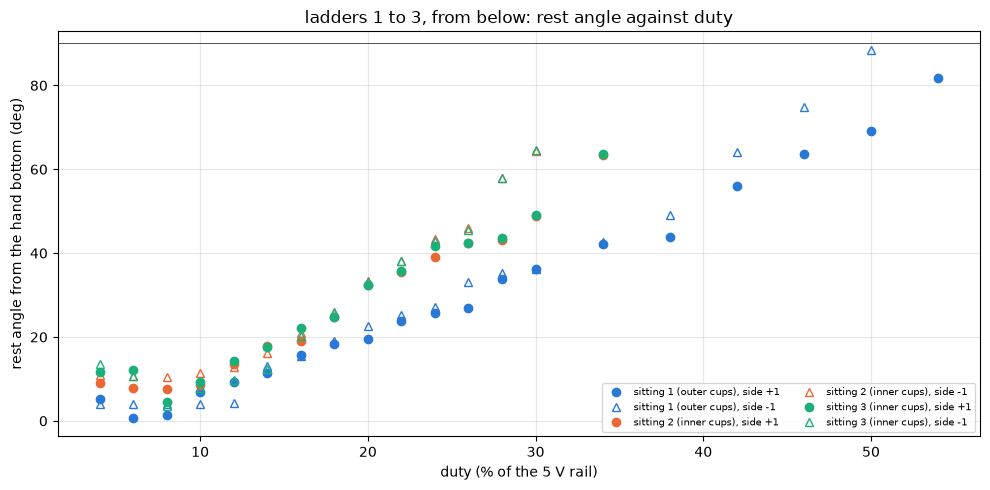

In [72]:
SIT_COLOR = {1: BLUE, 2: ORANGE, 3: GREEN}
fig, ax = plt.subplots(figsize=(10, 5))
for n in SITTINGS:
    for side in (1, -1):
        d = below[(below["sitting"] == n) & (below["side"] == side)]
        ax.plot(d["duty_pct"], d["theta"].abs(),
                **figures.direction_style(side, SIT_COLOR[n]),
                label=f"sitting {n} ({SITS.loc[n, 'cups']} cups), "
                f"side {side:+d}")
ax.axhline(90, color=INK, lw=0.5)
figures.label(ax, x="duty (% of the 5 V rail)",
              y="rest angle from the hand bottom (deg)",
              title="ladders 1 to 3, from below: rest angle against duty")
ax.legend(fontsize=7, ncol=2)
figures.finish(fig)

What you are looking at. The rest angle each from-below rung reached against its duty, filled for side +1 and open for side -1, one color per sitting. The two inner-pair sittings, orange and green, lie on top of each other.

In [73]:
def side_line(d, y="tau_mn_m"):
    """The torque line on the winding current, and its residual trend
    against duty."""
    f = torque_line(d, y)
    f["trend"] = results.fit_line(d["duty_pct"], f["resid"])
    return f


LINES = {}      # (sitting, side): the coins-scale and the absolute line
for (n, side), d in CURVE.groupby(["sitting", "side"]):
    fc, fa = side_line(d, "tau_coins"), side_line(d)
    LINES[(n, side)] = {"coins": fc, "abs": fa}
    tr = fc["trend"]
    print(f"s{n} side {side:+d}: coins-scale K {fc['slope']:.1f} +/- "
          f"{fc['slope_se']:.1f}, c {-fc['intercept']:.2f}, rms "
          f"{fc['rms']:.2f}, max {np.abs(fc['resid']).max():.2f}, trend "
          f"{abs(tr['slope'] / tr['slope_se']):.1f} sigma; absolute Kt "
          f"{fa['slope']:.1f} +/- {fa['slope_se']:.1f} mN m/A, c "
          f"{-fa['intercept']:.2f}, n {fa['n']}, duty "
          f"{d['duty_pct'].min():.0f}-{d['duty_pct'].max():.0f} %")

s1 side -1: coins-scale K 194.1 +/- 4.6, c 7.47, rms 1.47, max 2.60, trend 0.0 sigma; absolute Kt 233.6 +/- 5.6 mN m/A, c 8.99, n 13, duty 14-46 %
s1 side +1: coins-scale K 179.3 +/- 3.4, c 6.93, rms 1.66, max 3.55, trend 0.0 sigma; absolute Kt 215.8 +/- 4.1 mN m/A, c 8.33, n 17, duty 6-50 %
s2 side -1: coins-scale K 190.2 +/- 5.7, c 11.11, rms 0.96, max 1.93, trend 0.0 sigma; absolute Kt 253.9 +/- 7.6 mN m/A, c 14.83, n 10, duty 12-30 %
s2 side +1: coins-scale K 146.2 +/- 6.9, c 4.57, rms 1.40, max 2.38, trend 0.0 sigma; absolute Kt 195.2 +/- 9.2 mN m/A, c 6.10, n 11, duty 12-34 %
s3 side -1: coins-scale K 195.5 +/- 6.3, c 12.45, rms 1.42, max 3.15, trend 0.0 sigma; absolute Kt 261.0 +/- 8.4 mN m/A, c 16.62, n 12, duty 8-30 %
s3 side +1: coins-scale K 150.3 +/- 5.3, c 5.11, rms 1.41, max 2.50, trend 0.0 sigma; absolute Kt 200.7 +/- 7.1 mN m/A, c 6.82, n 13, duty 8-34 %


Each sitting and side gives a straight line. The residual's trend against duty prints 0.0 sigma on all six, the coins-scale rms runs 0.96 to 1.66 mN m and the largest residual is 3.55. The coins-scale slope $K$ of the up side drops from 179.3 with the heavy arm to 146.2 and 150.3 with the light one, and the down side's stays at 194.1, 190.2 and 195.5.

In [74]:
GROUP = {"s1": [1], "s2+3": [2, 3], "s1+2+3": [1, 2, 3]}
KT3 = {}        # (side or "both", group): the absolute line
for g, ns in GROUP.items():
    d = CURVE[CURVE["sitting"].isin(ns)]
    for side in (1, -1):
        KT3[(side, g)] = torque_line(d[d["side"] == side])
    KT3[("both", g)] = torque_line(d)
for (side, g), f in KT3.items():
    side_txt = side if side == "both" else f"side {side:+d}"
    print(f"{side_txt:>9s} {g:7s}: Kt_gear {f['slope']:.1f} +/- "
          f"{f['slope_se']:.1f} mN m/A = {f['slope'] / KT_IDEAL:.3f} of Ke "
          f"x N; c {-f['intercept']:.2f}; rms {f['rms']:.2f}; n {f['n']}")

  side +1 s1     : Kt_gear 215.8 +/- 4.1 mN m/A = 0.604 of Ke x N; c 8.33; rms 2.00; n 17
  side -1 s1     : Kt_gear 233.6 +/- 5.6 mN m/A = 0.654 of Ke x N; c 8.99; rms 1.77; n 13
     both s1     : Kt_gear 222.8 +/- 4.9 mN m/A = 0.624 of Ke x N; c 8.35; rms 2.94; n 30
  side +1 s2+3   : Kt_gear 198.2 +/- 5.4 mN m/A = 0.555 of Ke x N; c 6.52; rms 1.90; n 24
  side -1 s2+3   : Kt_gear 258.9 +/- 5.6 mN m/A = 0.725 of Ke x N; c 16.06; rms 1.67; n 22
     both s2+3   : Kt_gear 221.8 +/- 6.5 mN m/A = 0.621 of Ke x N; c 10.19; rms 3.11; n 46
  side +1 s1+2+3 : Kt_gear 212.1 +/- 3.7 mN m/A = 0.594 of Ke x N; c 8.58; rms 2.35; n 41
  side -1 s1+2+3 : Kt_gear 248.0 +/- 4.1 mN m/A = 0.695 of Ke x N; c 13.55; rms 2.04; n 35
     both s1+2+3 : Kt_gear 225.7 +/- 3.9 mN m/A = 0.632 of Ke x N; c 10.23; rms 3.19; n 76


In [75]:
s1 = CURVE[CURVE["sitting"] == 1].copy()
s1_old = s1.assign(tau_mn_m=TAU_H * np.sin(np.radians(
    np.abs(theta_deg(s1["rest_pos"], BOTTOM)))))
for key, sel in (("side +1", s1["side"] == 1), ("side -1", s1["side"] == -1),
                 ("both", s1["side"] != 0)):
    k_new = torque_line(s1[sel])["slope"]
    k_old = torque_line(s1_old[sel])["slope"]
    print(f"sitting 1 {key}: Kt_gear {k_old:.1f} at the bottom "
          f"{BOTTOM:.0f}, {k_new:.1f} at {SITS.loc[1, 'bottom']}, "
          f"{(k_new / k_old - 1) * 100:+.2f} %")

sitting 1 side +1: Kt_gear 215.8 at the bottom 2021, 215.8 at 2024, -0.01 %
sitting 1 side -1: Kt_gear 234.3 at the bottom 2021, 233.6 at 2024, -0.27 %
sitting 1 both: Kt_gear 222.9 at the bottom 2021, 222.8 at 2024, -0.02 %


With both sides pooled, Kt through the gears is 222.8 mN m/A for the heavy arm (sitting 1 at its hang), 221.8 +/- 6.5 for the light arm and 225.7 +/- 3.9 over all three sittings, 0.632 of $K_e N$. A pooled slope that does not move with the mass says the weighed arm's term is right in pooled form. Per side the lines move, the up side from 215.8 to 198.2 and the down side from 233.6 to 258.9, and section 11.3 reads that. Between the bottoms 2021 and 2024, sitting 1's Kt through the gears moves by 0.27 % or less.

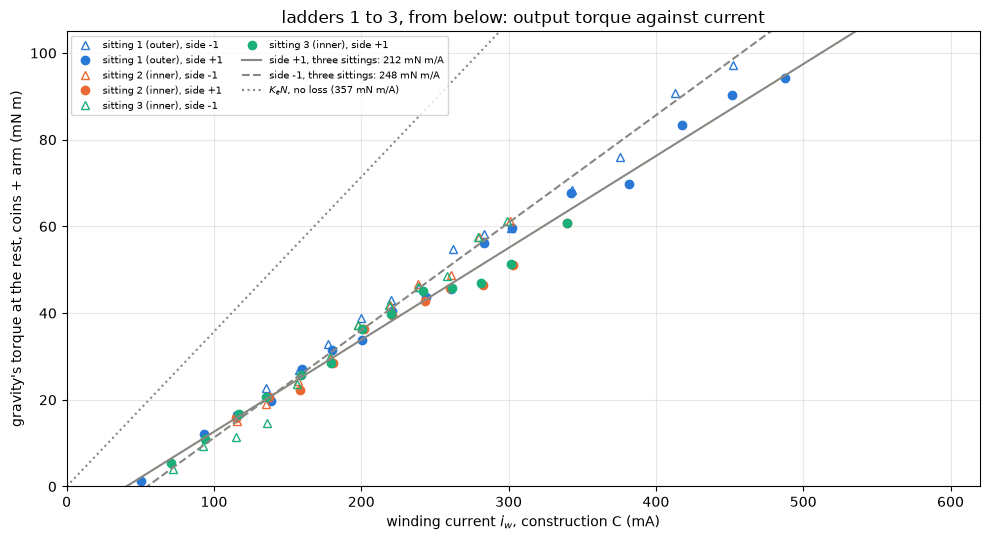

In [76]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for (n, side), d in CURVE.groupby(["sitting", "side"]):
    ax.plot(d["i_w_a"] * 1e3, d["tau_mn_m"],
            **figures.direction_style(side, SIT_COLOR[n]),
            label=f"sitting {n} ({SITS.loc[n, 'cups']}), side {side:+d}")
amps = np.linspace(0, 0.62, 5)
for side, ls in ((1, "-"), (-1, "--")):
    f = KT3[(side, "s1+2+3")]
    ax.plot(amps * 1e3, f["intercept"] + f["slope"] * amps, ls, color=MUTED,
            label=f"side {side:+d}, three sittings: {f['slope']:.0f} mN m/A")
ax.plot(amps * 1e3, KT_IDEAL * amps, ":", color=MUTED,
        label=f"$K_e N$, no loss ({KT_IDEAL:.0f} mN m/A)")
ax.set_xlim(0, 620)
ax.set_ylim(0, 105)
figures.label(ax, x="winding current $i_w$, construction C (mA)",
              y="gravity's torque at the rest, coins + arm (mN m)",
              title="ladders 1 to 3, from below: output torque against "
              "current")
ax.legend(fontsize=7, ncol=2, loc="upper left")
figures.finish(fig)

What you are looking at. Gravity's torque at each from-below rest, coins and arm, against the winding current, one color per sitting, filled for side +1 and open for side -1. The gray lines are each side's fit over the three sittings and the dotted line the lossless $K_e N$. The light arm's down-side rests (open orange and green) sit above its up-side rests at the higher currents.

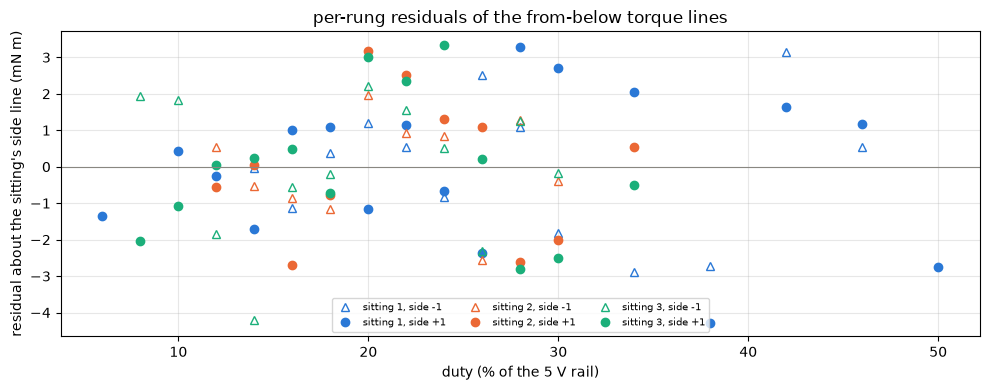

In [77]:
fig, ax = plt.subplots(figsize=(10, 4))
for (n, side), d in CURVE.groupby(["sitting", "side"]):
    ax.plot(d["duty_pct"], LINES[(n, side)]["abs"]["resid"],
            **figures.direction_style(side, SIT_COLOR[n]),
            label=f"sitting {n}, side {side:+d}")
ax.axhline(0, color=MUTED, lw=0.8)
figures.label(ax, x="duty (% of the 5 V rail)",
              y="residual about the sitting's side line (mN m)",
              title="per-rung residuals of the from-below torque lines")
ax.legend(fontsize=7, ncol=3)
figures.finish(fig)

What you are looking at. Each rung's residual about its own sitting and side line against the duty. The residuals stay inside +/- 3.6 mN m with no trend.

In [78]:
def arm_from(k1, t1, k2, t2):
    """The arm's term A from two coins-scale slopes, one Kt for both."""
    return (k2 - k1) / (k1 / t1 - k2 / t2)


def coins_slope(d):
    return torque_line(d, "tau_coins")["slope"]


T1, T23 = SITS.loc[1, "tau_coins"], SITS.loc[2, "tau_coins"]
N_BOOT = 2000           # resamples of the rungs, the generator seeded
ROUTE1 = {}
for side in (1, -1):
    d1 = CURVE[(CURVE["sitting"] == 1) & (CURVE["side"] == side)]
    d2 = CURVE[(CURVE["sitting"] >= 2) & (CURVE["side"] == side)]
    k1, k2 = coins_slope(d1), coins_slope(d2)
    rng = np.random.default_rng(1)
    boots = [arm_from(coins_slope(d1.sample(len(d1), replace=True,
                                            random_state=rng)), T1,
                      coins_slope(d2.sample(len(d2), replace=True,
                                            random_state=rng)), T23)
             for _ in range(N_BOOT)]
    lo, hi = np.percentile(boots, [16, 84])
    ROUTE1[side] = (arm_from(k1, T1, k2, T23), lo, hi)
    # the slope of sittings 2 and 3 the weighed arm predicts
    k2_arm = k1 * (1 + TAU_ARM / T1) / (1 + TAU_ARM / T23)
    se2 = torque_line(d2, "tau_coins")["slope_se"]
    print(f"side {side:+d}: K {k1:.1f} (sitting 1) and {k2:.1f} +/- "
          f"{se2:.1f} (2 + 3); A {ROUTE1[side][0]:.1f} mN m (16 to 84 % "
          f"{lo:.1f} to {hi:.1f}); the weighed arm predicts K {k2_arm:.1f}, "
          f"{(k2 - k2_arm) / se2:+.1f} sigma")

side +1: K 179.3 (sitting 1) and 148.5 +/- 4.0 (2 + 3); A 39.7 mN m (16 to 84 % 31.1 to 52.4); the weighed arm predicts K 161.6, -3.3 sigma


side -1: K 194.1 (sitting 1) and 193.9 +/- 4.2 (2 + 3); A 0.2 mN m (16 to 84 % -4.4 to 4.0); the weighed arm predicts K 175.0, +4.5 sigma


In [79]:
def joint_arm(d, sides=(1, -1)):
    """tau_coins = Kt i - A sin(theta) - c: one A, Kt and c per side.
    Returns (A, its se, rms)."""
    cols = [d["i_w_a"] * (d["side"] == s) for s in sides]
    cols += [-d["sin_theta"]] + [-1.0 * (d["side"] == s) for s in sides]
    design = np.c_[tuple(np.asarray(c, float) for c in cols)]
    y = d["tau_coins"].to_numpy()
    coef = np.linalg.lstsq(design, y, rcond=None)[0]
    res = y - design @ coef
    cov = (res ** 2).sum() / (len(y) - design.shape[1]) * np.linalg.inv(
        design.T @ design)
    k = len(sides)                          # A sits after the slopes
    return coef[k], np.sqrt(cov[k, k]), np.sqrt((res ** 2).mean())


ARM_JOINT = {s: joint_arm(CURVE[CURVE["side"] == s], (s,)) for s in (1, -1)}
ARM_JOINT["both"] = joint_arm(CURVE)
for key, (a, se, rms) in ARM_JOINT.items():
    print(f"{str(key):>4s}: A {a:.1f} +/- {se:.1f} mN m, "
          f"{(a - TAU_ARM) / se:+.1f} sigma from the weighed "
          f"{TAU_ARM:.2f}; rms {rms:.2f} mN m")

   1: A 24.9 +/- 4.1 mN m, +1.9 sigma from the weighed 17.04; rms 2.25 mN m
  -1: A 12.8 +/- 3.3 mN m, -1.3 sigma from the weighed 17.04; rms 1.99 mN m
both: A 18.2 +/- 2.7 mN m, +0.4 sigma from the weighed 17.04; rms 2.21 mN m


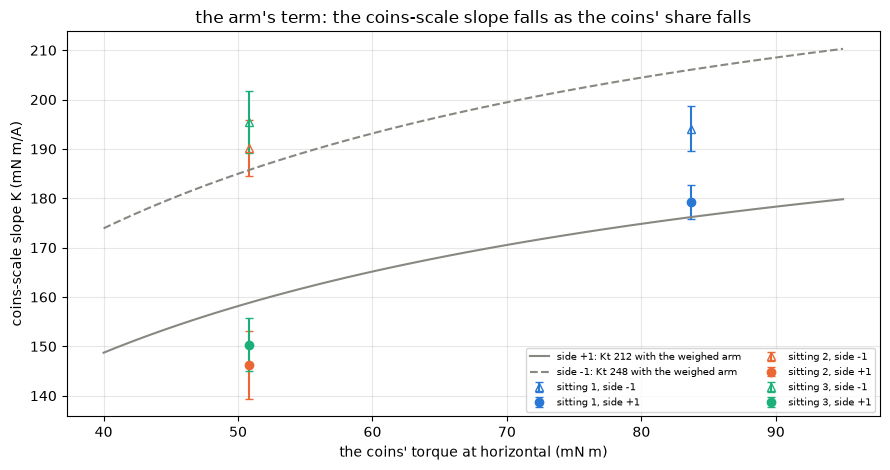

In [80]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for (n, side), f in LINES.items():
    ax.errorbar(SITS.loc[n, "tau_coins"], f["coins"]["slope"],
                yerr=f["coins"]["slope_se"], capsize=3,
                **figures.direction_style(side, SIT_COLOR[n]),
                label=f"sitting {n}, side {side:+d}")
taus = np.linspace(40, 95, 50)
for side, ls in ((1, "-"), (-1, "--")):
    kt = KT3[(side, "s1+2+3")]["slope"]
    ax.plot(taus, kt * taus / (taus + TAU_ARM), ls, color=MUTED,
            label=f"side {side:+d}: Kt {kt:.0f} with the weighed arm")
figures.label(ax, x="the coins' torque at horizontal (mN m)",
              y="coins-scale slope K (mN m/A)",
              title="the arm's term: the coins-scale slope falls as the "
              "coins' share falls")
ax.legend(fontsize=7, ncol=2)
figures.finish(fig)

Solving the coins-scale slopes of the two masses for the arm's term gives 39.7 mN m on the up side (16 to 84 % of a seeded bootstrap over the rungs, 31.1 to 52.4) and 0.2 on the down side (-4.4 to 4.0). The weighed arm predicts a light-arm slope of 161.6 on the up side and 175.0 on the down, and the fits sit -3.3 and +4.5 sigma from those. One rigid arm gives both sides the same term, so the two sides taken one at a time do not measure it. The joint fit with one term for both sides, Kt and the intercept per side, gives 18.2 +/- 2.7 mN m, +0.4 sigma from the weighed 17.04. The per-side joint fits give 24.9 +/- 4.1 and 12.8 +/- 3.3, and section 11.3 shows that gap comes from the rests above 41.5 degrees. The weighed 17.04 stays the number of record. The data's 18 +/- 3 agrees with it and is not a better number.

What you are looking at. The coins-scale slope of each sitting and side against the coins' torque at horizontal, with its standard error. The gray curves are what one Kt per side and the weighed arm predict. The down side's slope stays flat where the curve falls.

In [81]:
cols = ["rest_pos", "theta", "i_w_a", "moved"]
two = below[below["sitting"] == 2].set_index(["side", "duty_pct"])[cols]
three = below[below["sitting"] == 3].set_index(["side", "duty_pct"])[cols]
REP = two.merge(three, left_index=True, right_index=True,
                suffixes=("_2", "_3"))
REP["d_theta"] = REP["theta_3"] - REP["theta_2"]      # deg, 3 less 2
REP["d_i_ma"] = (REP["i_w_a_3"] - REP["i_w_a_2"]) * 1e3
duty = REP.index.get_level_values("duty_pct")
BOTH = REP[REP["moved_2"] & REP["moved_3"] & (duty >= 12)]
print(f"both lifted, >= 12 %: d_theta {BOTH['d_theta'].mean():+.2f} sd "
      f"{BOTH['d_theta'].std():.2f} deg (n {len(BOTH)}), max "
      f"{BOTH['d_theta'].abs().max():.1f}; current "
      f"{BOTH['d_i_ma'].mean():+.1f} sd {BOTH['d_i_ma'].std():.1f} mA")
for side in (1, -1):
    b = BOTH[BOTH.index.get_level_values("side") == side]
    print(f"  side {side:+d}: d_theta {b['d_theta'].mean():+.2f} sd "
          f"{b['d_theta'].std():.2f} deg (n {len(b)}); Kt_gear "
          f"{LINES[(2, side)]['abs']['slope']:.0f} and "
          f"{LINES[(3, side)]['abs']['slope']:.0f} mN m/A")

both lifted, >= 12 %: d_theta +0.75 sd 1.24 deg (n 21), max 3.8; current -0.7 sd 1.0 mA
  side +1: d_theta +0.68 sd 1.12 deg (n 11); Kt_gear 195 and 201 mN m/A
  side -1: d_theta +0.83 sd 1.41 deg (n 10); Kt_gear 254 and 261 mN m/A


At matched duty the rests of sittings 2 and 3 agree to +0.75 sd 1.24 degrees over the 21 rungs where both lifted the arm, 3.8 at most, and the currents to -0.7 sd 1.0 mA. Their side slopes agree within one standard error, 195 and 201 mN m/A up, 254 and 261 down. The two inner-pair sittings are one measurement repeated, and it repeats.

### 11.3 The two sides

Over the full range of rests the light arm's lines split by side far more than the heavy arm's. This part restates the split, then follows it to the rests above 41.5 degrees.

In [82]:
def side_split(d):
    """Up and down lines, the ratio down over up and its sigma."""
    up = torque_line(d[d["side"] == 1])
    dn = torque_line(d[d["side"] == -1])
    sigma = (dn["slope"] - up["slope"]) / np.hypot(up["slope_se"],
                                                  dn["slope_se"])
    return up, dn, dn["slope"] / up["slope"], sigma


SPLIT3 = {}
for g, ns in (("s1", [1]), ("s2", [2]), ("s3", [3]), ("s2+3", [2, 3]),
              ("s1+2+3", [1, 2, 3])):
    up, dn, ratio, sigma = side_split(CURVE[CURVE["sitting"].isin(ns)])
    SPLIT3[g] = (ratio, sigma)
    print(f"{g:7s}: up {up['slope']:.1f} +/- {up['slope_se']:.1f}, down "
          f"{dn['slope']:.1f} +/- {dn['slope_se']:.1f} mN m/A; down/up "
          f"{ratio:.3f}, {sigma:+.1f} sigma; c up {-up['intercept']:.1f}, "
          f"down {-dn['intercept']:.1f} mN m")
inner = CURVE[CURVE["sitting"] >= 2]
up, dn, ratio, sigma = side_split(inner[~inner["outside_table"]])
print(f"s2+3 inside the table only: down/up {ratio:.3f}, {sigma:+.1f} sigma")
for n in (2, 3):
    d = CURVE[CURVE["sitting"] == n]
    nominal = d.assign(tau_mn_m=SITS.loc[n, "tau_h"] * np.sin(np.radians(
        d["rest_deg_nominal"].abs())))
    up, dn, _, _ = side_split(nominal)
    print(f"s{n} at the nominal 19.8 counts/deg: up {up['slope']:.0f}, "
          f"down {dn['slope']:.0f} mN m/A")

s1     : up 215.8 +/- 4.1, down 233.6 +/- 5.6 mN m/A; down/up 1.083, +2.6 sigma; c up 8.3, down 9.0 mN m
s2     : up 195.2 +/- 9.2, down 253.9 +/- 7.6 mN m/A; down/up 1.301, +4.9 sigma; c up 6.1, down 14.8 mN m
s3     : up 200.7 +/- 7.1, down 261.0 +/- 8.4 mN m/A; down/up 1.300, +5.5 sigma; c up 6.8, down 16.6 mN m
s2+3   : up 198.2 +/- 5.4, down 258.9 +/- 5.6 mN m/A; down/up 1.306, +7.8 sigma; c up 6.5, down 16.1 mN m
s1+2+3 : up 212.1 +/- 3.7, down 248.0 +/- 4.1 mN m/A; down/up 1.169, +6.5 sigma; c up 8.6, down 13.6 mN m
s2+3 inside the table only: down/up 1.306, +7.0 sigma
s2 at the nominal 19.8 counts/deg: up 194, down 260 mN m/A
s3 at the nominal 19.8 counts/deg: up 199, down 258 mN m/A


In [83]:
SIDE_I3 = {}            # sitting: current down over up at matched duty
for n in (2, 3):
    d = CURVE[CURVE["sitting"] == n]
    m = d.pivot_table(index="duty_pct", columns="side",
                      values=["i_w_a", "ath"]).dropna()
    ratio = SIDE_I3[n] = m[("i_w_a", -1)] / m[("i_w_a", 1)]
    # half the angle gap: the bottom offset that would close the sides
    offset = (m[("ath", -1)] - m[("ath", 1)]) / 2
    print(f"sitting {n}: current down/up at matched duty {ratio.mean():.4f}"
          f" sd {ratio.std():.4f} (n {len(m)}); as a bottom offset "
          + " ".join(f"{int(k)}%:{v:+.1f}" for k, v in offset.items()))

sitting 2: current down/up at matched duty 0.9913 sd 0.0072 (n 10); as a bottom offset 12%:-0.4 14%:-0.8 16%:+0.9 18%:+0.5 20%:+0.4 22%:+1.2 24%:+2.2 26%:+1.8 28%:+7.4 30%:+7.8
sitting 3: current down/up at matched duty 0.9917 sd 0.0101 (n 12); as a bottom offset 8%:-0.5 10%:-0.7 12%:-2.3 14%:-2.6 16%:-0.9 18%:+0.6 20%:+0.4 22%:+1.2 24%:+0.6 26%:+1.6 28%:+7.1 30%:+7.7


Over sittings 2 and 3 the down side reads 258.9 mN m/A and the up side 198.2, a ratio of 1.306 at +7.8 sigma, against 1.083 at +2.6 sigma in sitting 1. Each inner-pair sitting alone gives 1.301 and 1.300. The rungs inside the pot table give 1.306 at +7.0 sigma, and the nominal 19.8 counts per degree gives 194 against 260 and 199 against 258, so the table does not make it. The current down over up at matched duty is 0.9913 and 0.9917, so the bridge drives both sides alike. A bottom error would close the sides by one constant offset, and the offset that closes them runs from -2.6 to +7.8 degrees with duty. The intercepts differ too, 6.5 mN m up and 16.1 down.

In [84]:
CELL = 23               # counts, about one motor revolution at the output
W_UP = (2790, 2859)     # counts, the up side's sticky rests + one cell
W_DN1 = (1295, 1364)    # counts, sitting 1's down-side candidate
W_DN23 = (1088, 1157)   # counts, sittings 2 and 3's down-side candidate
ANCHOR = W_UP[0]        # a cell edge, so the windows are whole cells
EDGE_DEG = {n: float(theta_deg(W_UP[0], SITS.loc[n, "bottom"]))
            for n in SITTINGS}      # the up window's lower edge, deg
CURVE["grp"] = np.where(CURVE["sitting"] == 1, "s1", "s2+3")
CURVE["in_up"] = (CURVE["side"] == 1) & CURVE["rest_pos"].between(*W_UP)
CURVE["matched"] = CURVE["ath"] < CURVE["sitting"].map(EDGE_DEG)
GROUPS = {"s1": [1], "s2+3": [2, 3]}
MATCHED = {}    # (group, side): the line below the up window's edge
for g, ns in GROUPS.items():
    for side in (1, -1):
        m = CURVE["sitting"].isin(ns) & (CURVE["side"] == side)
        f = torque_line(CURVE[m & CURVE["matched"]])
        MATCHED[(g, side)] = f
        CURVE.loc[m, "resid_matched"] = (CURVE.loc[m, "tau_mn_m"]
                                         - f["slope"] * CURVE.loc[m, "i_w_a"]
                                         - f["intercept"])
top = {n: float(theta_deg(W_UP[1], SITS.loc[n, "bottom"]))
       for n in SITTINGS}
print(f"the up window {W_UP[0]} to {W_UP[1]} counts: " + ", ".join(
    f"sitting {n} {EDGE_DEG[n]:.1f} to {top[n]:.1f} deg" for n in SITTINGS))
for (g, side), f in MATCHED.items():
    print(f"{g:5s} side {side:+d}, below the edge: {f['slope']:.1f} +/- "
          f"{f['slope_se']:.1f} mN m/A, rms {f['rms']:.2f}, n {f['n']}")

the up window 2790 to 2859 counts: sitting 1 41.5 to 45.2 deg, sitting 2 41.5 to 45.2 deg, sitting 3 41.5 to 45.2 deg
s1    side +1, below the edge: 225.3 +/- 6.3 mN m/A, rms 1.51, n 12
s1    side -1, below the edge: 235.4 +/- 8.8 mN m/A, rms 1.26, n 9
s2+3  side +1, below the edge: 222.7 +/- 7.2 mN m/A, rms 1.27, n 15
s2+3  side -1, below the edge: 266.7 +/- 11.3 mN m/A, rms 1.75, n 14


In [85]:
BANDS = (("30-41.5", 30, 41.5), ("41.5-49.5", 41.5, 49.5),
         ("beyond 49.5", 49.5, 90))           # deg from the bottom
rows = []
for (g, side), f in MATCHED.items():
    d = CURVE[CURVE["sitting"].isin(GROUPS[g]) & (CURVE["side"] == side)]
    for name, lo, hi in BANDS:
        b = d[(d["ath"] >= lo) & (d["ath"] < hi)].sort_values("ath")
        rows.append({"group": g, "side": side, "band": name, "n": len(b),
                     "mean": b["resid_matched"].mean(),
                     "residuals": " ".join(f"{v:+.1f}"
                                           for v in b["resid_matched"]),
                     "at_deg": " ".join(f"{v:.0f}" for v in b["ath"])})
BAND_TABLE = pd.DataFrame(rows)
show(BAND_TABLE.round(2), n=None)

,group,side,band,n,mean,residuals,at_deg
0,s1,1,30-41.5,2,1.810,+2.2 +1.4,34 36
1,s1,1,41.5-49.5,2,-2.940,+0.4 -6.3,42 44
2,s1,1,beyond 49.5,3,-2.670,-0.7 -1.5 -5.8,56 64 69
3,s1,-1,30-41.5,3,0.270,+2.2 +0.8 -2.2,33 35 36
4,s1,-1,41.5-49.5,2,-3.250,-3.3 -3.2,43 49
5,s1,-1,beyond 49.5,2,1.260,+2.6 -0.1,64 75
6,s2+3,1,30-41.5,5,0.730,+1.9 +1.7 +0.5 +0.9 -1.3,32 32 36 36 39
7,s2+3,1,41.5-49.5,7,-3.850,+1.4 -2.0 -2.2 -6.3 -5.7 -6.3 -5.8,42 42 42 43 44 49 49
8,s2+3,1,beyond 49.5,2,-4.690,-4.7 -4.6,63 64
9,s2+3,-1,30-41.5,4,1.140,+1.6 +1.7 +0.4 +0.8,33 33 38 38


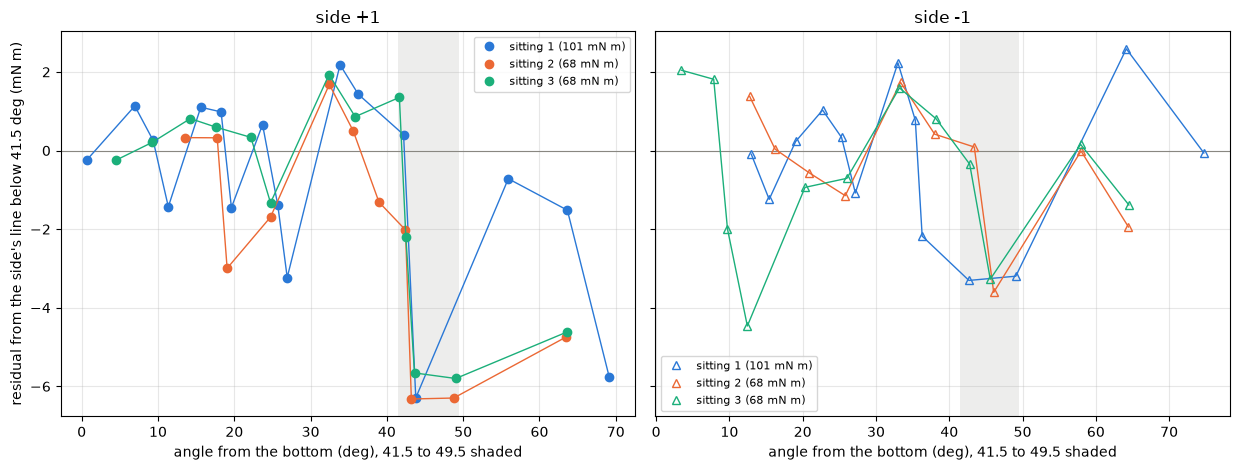

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True)
for ax, side in zip(axes, (1, -1)):
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.axvspan(BANDS[1][1], BANDS[1][2], color=MUTED, alpha=0.15, lw=0)
    for n in SITTINGS:
        d = CURVE[(CURVE["sitting"] == n) & (CURVE["side"] == side)]
        d = d.sort_values("ath")
        ax.plot(d["ath"], d["resid_matched"], "-", color=SIT_COLOR[n], lw=1)
        ax.plot(d["ath"], d["resid_matched"],
                **figures.direction_style(side, SIT_COLOR[n]),
                label=f"sitting {n} ({SITS.loc[n, 'tau_h']:.0f} mN m)")
    figures.label(ax, x="angle from the bottom (deg), 41.5 to 49.5 shaded",
                  title=f"side {side:+d}")
    ax.legend(fontsize=8)
axes[0].set_ylabel("residual from the side's line below 41.5 deg (mN m)")
figures.finish(fig)

Fitting each side over the rests below 41.5 degrees only, the range both sides and both masses cover under the up side's sticky window at 2790 counts, the up side reads 225.3 mN m/A with the heavy arm and 222.7 with the light one. The up side's line is the same at both masses there.

Above 41.5 degrees the rests leave those lines. In sittings 2 and 3 the up side's rests at 42 to 49 degrees sit from +1.4 to -6.3 mN m off the line, five of seven under -2, and the two beyond at 63 and 64 degrees sit at -4.7 and -4.6. The down side's sit at -3.3 and -3.6 at 46 degrees and come back to within 1.9 of the line beyond 49.5. Sitting 1 dips at 42 to 49 degrees on both sides, -6.3 at 44 degrees up and -3.3 and -3.2 down. The rms below the edge is 1.26 to 1.75 mN m. The dip starts at the same angle under 100.75 and 67.89 mN m of load, so it follows the position or the angle and not the torque the train carries.

What you are looking at. Each rest's residual from its side's line below the edge, against the angle from the bottom, one color per sitting. The band 41.5 to 49.5 degrees is shaded. Both panels dip inside it.

In [87]:
SELECT = {"all": CURVE["sitting"] > 0, "without the up window": ~CURVE[
    "in_up"], "below the edge": CURVE["matched"],
    "below the edge, duty >= 16 %": CURVE["matched"]
    & (CURVE["duty_pct"] >= 16)}
rows = []
for name, sel in SELECT.items():
    for g, ns in GROUPS.items():
        up, dn, ratio, sigma = side_split(
            CURVE[sel & CURVE["sitting"].isin(ns)])
        rows.append({"rests": name, "group": g, "up": up["slope"],
                     "up_se": up["slope_se"], "down": dn["slope"],
                     "down_se": dn["slope_se"], "ratio": ratio,
                     "sigma": sigma})
BY_SELECTION = pd.DataFrame(rows)
show(BY_SELECTION.round(3), n=None)
for g, ns in GROUPS.items():
    base = CURVE["matched"] & CURVE["sitting"].isin(ns)
    ratios = [side_split(CURVE[base & (CURVE["duty_pct"] != duty)])[2]
              for duty in sorted(CURVE[base]["duty_pct"].unique())]
    print(f"{g}, below the edge, one duty left out: ratio "
          f"{min(ratios):.3f} to {max(ratios):.3f}")

,rests,group,up,up_se,down,down_se,ratio,sigma
0,all,s1,215.793,4.127,233.646,5.570,1.083,2.575
1,all,s2+3,198.191,5.371,258.860,5.569,1.306,7.842
2,without the up window,s1,217.437,3.782,233.646,5.570,1.075,2.407
3,without the up window,s2+3,200.046,5.385,258.860,5.569,1.294,7.592
4,below the edge,s1,225.266,6.323,235.374,8.844,1.045,0.930
5,below the edge,s2+3,222.678,7.240,266.741,11.312,1.198,3.281
6,"below the edge, duty >= 16 %",s1,225.802,15.015,234.884,11.470,1.040,0.481
7,"below the edge, duty >= 16 %",s2+3,242.936,20.461,298.369,14.023,1.228,2.235


s1, below the edge, one duty left out: ratio 1.006 to 1.109
s2+3, below the edge, one duty left out: ratio 1.177 to 1.243


In [88]:
def one_slope(d):
    """One slope on the current with an intercept per side: (slope, se)."""
    design = np.c_[d["i_w_a"], (d["side"] == 1) * 1.0,
                   (d["side"] == -1) * 1.0]
    y = d["tau_mn_m"].to_numpy()
    coef = np.linalg.lstsq(design, y, rcond=None)[0]
    res = y - design @ coef
    cov = res @ res / (len(y) - 3) * np.linalg.inv(design.T @ design)
    return coef[0], np.sqrt(cov[0, 0])


ONE_SLOPE = {}
for g, ns in (("s1", [1]), ("s2+3", [2, 3]), ("all", [1, 2, 3])):
    d = CURVE[CURVE["sitting"].isin(ns)]
    for name, sel in (("full", d["ath"] > 0), ("below", d["matched"])):
        ONE_SLOPE[(g, name)] = one_slope(d[sel])
print("one slope, an intercept per side, mN m/A: " + "; ".join(
    f"{g} {name} {k:.1f} +/- {se:.1f}"
    for (g, name), (k, se) in ONE_SLOPE.items()))
lo, hi = ONE_SLOPE[("s1", "full")][0], ONE_SLOPE[("s2+3", "below")][0]
below_edge = BY_SELECTION[BY_SELECTION["rests"] == "below the edge"]
print(f"bracket {lo:.1f} to {hi:.1f} mN m/A = {lo / KT_IDEAL:.3f} to "
      f"{hi / KT_IDEAL:.3f} of Ke x N; below the edge the down side reads "
      f"{(below_edge['ratio'].min() - 1) * 100:.1f} to "
      f"{(below_edge['ratio'].max() - 1) * 100:.1f} % over the up side")

one slope, an intercept per side, mN m/A: s1 full 221.3 +/- 3.6; s1 below 228.1 +/- 5.1; s2+3 full 223.6 +/- 6.0; s2+3 below 242.0 +/- 7.7; all full 225.9 +/- 3.4; all below 240.2 +/- 4.8
bracket 221.3 to 242.0 mN m/A = 0.620 to 0.678 of Ke x N; below the edge the down side reads 4.5 to 19.8 % over the up side


In [89]:
def straightness(d):
    """The quadratic term of a parabola in the current and its se, and
    the line's slope over the lower and the upper half of the angles."""
    x, y = d["i_w_a"].to_numpy(), d["tau_mn_m"].to_numpy()
    design = np.c_[x ** 2, x, np.ones_like(x)]
    coef = np.linalg.lstsq(design, y, rcond=None)[0]
    res = y - design @ coef
    cov = res @ res / (len(x) - 3) * np.linalg.inv(design.T @ design)
    half = d["ath"] <= d["ath"].median()
    lo, hi = torque_line(d[half]), torque_line(d[~half])
    return coef[0], np.sqrt(cov[0, 0]), lo, hi


for g, ns in GROUPS.items():
    for side in (1, -1):
        d = CURVE[CURVE["sitting"].isin(ns) & (CURVE["side"] == side)
                  & CURVE["matched"]]
        quad, se, lo, hi = straightness(d)
        print(f"{g:5s} side {side:+d}, below the edge: quadratic {quad:+.0f}"
              f" +/- {se:.0f} mN m/A2 ({quad / se:+.1f} sigma); lower half "
              f"{lo['slope']:.0f} +/- {lo['slope_se']:.0f}, upper half "
              f"{hi['slope']:.0f} +/- {hi['slope_se']:.0f}")

s1    side +1, below the edge: quadratic +60 +/- 89 mN m/A2 (+0.7 sigma); lower half 230 +/- 10, upper half 250 +/- 24
s1    side -1, below the edge: quadratic -214 +/- 183 mN m/A2 (-1.2 sigma); lower half 250 +/- 12, upper half 216 +/- 50
s2+3  side +1, below the edge: quadratic +28 +/- 153 mN m/A2 (+0.2 sigma); lower half 210 +/- 15, upper half 232 +/- 29
s2+3  side -1, below the edge: quadratic +549 +/- 217 mN m/A2 (+2.5 sigma); lower half 215 +/- 29, upper half 297 +/- 18


The table gives the ratio by the rests used. Leaving out the up window's rests barely moves it, 1.075 and 1.294. Below the edge it drops to 1.045 with the heavy arm (0.9 sigma) and 1.198 with the light one (3.3 sigma). A ratio set by the train, a direction-dependent efficiency, would be the same at both masses. Below the edge the light arm's down line also fails a straightness test, a quadratic term of +549 +/- 217 mN m/A$^2$ at +2.5 sigma, 215 over the lower half of its angles and 297 over the upper. Leaving one duty out moves the ratio over 1.006 to 1.109 with the heavy arm and 1.177 to 1.243 with the light one. A side split of Kt through the gears as a ratio is not established. As a bound, the down side reads 4.5 to 19.8 % over the up side below 41.5 degrees.

One slope with an intercept per side gives 221.3 +/- 3.6 (sitting 1), 223.6 +/- 6.0 (sittings 2 and 3) and 225.9 +/- 3.4 (all) over the full range, and 228.1, 242.0 and 240.2 below the edge. Kt through the gears of record stays the pooled 225.7 +/- 3.9 over all three sittings and the full range. Its bracket runs from 221.3 to 242.0, the full range to the matched range, 0.620 to 0.678 of $K_e N$.

In [90]:
NOMINAL = (TC[-1] - TC[0]) / (TA[-1] - TA[0])    # counts/deg, the span


def counts_of(angle):
    """Pot counts at a table angle, past the ends the span's slope."""
    a = np.asarray(angle, float)
    c = np.interp(a, TA, TC)
    c = np.where(a < TA[0], TC[0] + (a - TA[0]) * NOMINAL, c)
    return np.where(a > TA[-1], TC[-1] + (a - TA[-1]) * NOMINAL, c)


def line_rest(n, side, i_w):
    """The rest in counts the side's line below the edge predicts."""
    f = MATCHED[("s1" if n == 1 else "s2+3", side)]
    tau = f["slope"] * np.asarray(i_w) + f["intercept"]
    th = np.degrees(np.arcsin(np.clip(tau / SITS.loc[n, "tau_h"], -1, 1)))
    return counts_of(angle_of(SITS.loc[n, "bottom"]) + side * th)

In [91]:
pair = CURVE[CURVE["sitting"] == 2].merge(
    CURVE[CURVE["sitting"] == 3], on=["side", "duty_pct"])
SD_PAIR = (pair["rest_pos_y"] - pair["rest_pos_x"]).std()   # counts
rows = []
for (n, side), d in CURVE.groupby(["sitting", "side"]):
    d = d.sort_values("duty_pct")
    expect = line_rest(n, side, d["i_w_a"])
    for a in range(len(d) - 1):
        r1, r2 = d.iloc[a], d.iloc[a + 1]
        obs = side * (r2["rest_pos"] - r1["rest_pos"])   # counts moved
        exp = side * (expect[a + 1] - expect[a])         # the line's
        sticky = obs < 0.4 * exp and exp - obs > 2 * SD_PAIR
        rows.append({"sitting": n, "side": side, "duty_1": r1["duty_pct"],
                     "duty_2": r2["duty_pct"], "pos_1": r1["rest_pos"],
                     "pos_2": r2["rest_pos"], "ratio": obs / exp,
                     "sticky": sticky})
STAIR = pd.DataFrame(rows)
sticky = STAIR[STAIR["sticky"]]
in_up = sticky[(sticky["side"] == 1) & (sticky["pos_1"] >= W_UP[0] - 5)
               & (sticky["pos_2"] <= W_UP[1])]
STICKY, IN_UP = sticky, in_up        # for the result file
print(f"repeat sd sittings 2 to 3: {SD_PAIR:.1f} counts; sticky pairs "
      f"{len(sticky)} of {len(STAIR)}, {len(in_up)} in the up window; "
      f"step there {in_up['ratio'].min():.2f} to {in_up['ratio'].max():.2f}"
      f" of the line's")
show(sticky.round(2), n=None)

repeat sd sittings 2 to 3: 22.1 counts; sticky pairs 7 of 70, 4 in the up window; step there 0.13 to 0.24 of the line's


,sitting,side,duty_1,duty_2,pos_1,pos_2,ratio,sticky
24,1,1,34,38,2802.000,2833.000,0.240,True
34,2,-1,24,26,1196.000,1144.000,0.350,True
38,2,1,14,16,2343.000,2364.000,0.280,True
44,2,1,26,28,2808.000,2823.000,0.130,True
48,3,-1,10,12,1867.000,1839.000,0.360,True
66,3,1,24,26,2793.000,2809.000,0.180,True
67,3,1,26,28,2809.000,2831.000,0.210,True


In [92]:
for n in (2, 3):
    up = CURVE[(CURVE["sitting"] == n) & (CURVE["side"] == 1)]
    dn = CURVE[(CURVE["sitting"] == n) & (CURVE["side"] == -1)]
    up, dn = up.set_index("duty_pct"), dn.set_index("duty_pct")
    gain = {}
    for key, d in (("up", up), ("down", dn)):
        k = MATCHED[("s2+3", 1 if key == "up" else -1)]["slope"]
        gain[key] = (d.loc[28, "tau_mn_m"] - d.loc[26, "tau_mn_m"],
                     k * (d.loc[28, "i_w_a"] - d.loc[26, "i_w_a"]))
    print(f"sitting {n}, 26 -> 28 %: the up rest gains "
          f"{gain['up'][0]:+.1f} mN m where its line gives "
          f"{gain['up'][1]:+.1f}; the down rest {gain['down'][0]:+.1f} "
          f"where its line gives {gain['down'][1]:+.1f}")

sitting 2, 26 -> 28 %: the up rest gains +0.7 mN m where its line gives +5.0; the down rest +8.7 where its line gives +5.1
sitting 3, 26 -> 28 %: the up rest gains +1.0 mN m where its line gives +4.4; the down rest +9.0 where its line gives +5.6


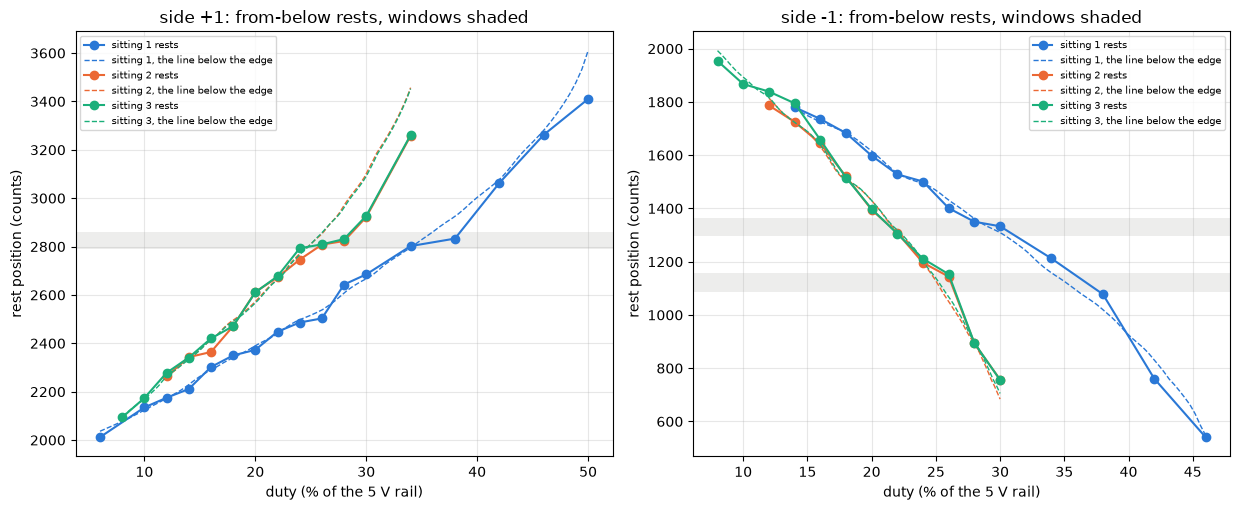

In [93]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
for ax, side, wins in ((axes[0], 1, (W_UP,)), (axes[1], -1,
                                               (W_DN1, W_DN23))):
    for lo, hi in wins:
        ax.axhspan(lo, hi, color=MUTED, alpha=0.15, lw=0)
    for n in SITTINGS:
        d = CURVE[(CURVE["sitting"] == n) & (CURVE["side"] == side)]
        d = d.sort_values("duty_pct")
        ax.plot(d["duty_pct"], d["rest_pos"], "o-", color=SIT_COLOR[n],
                label=f"sitting {n} rests")
        duty = np.linspace(d["duty_pct"].min(), d["duty_pct"].max(), 80)
        amps = np.interp(duty, d["duty_pct"], d["i_w_a"])
        ax.plot(duty, line_rest(n, side, amps), "--", color=SIT_COLOR[n],
                lw=1, label=f"sitting {n}, the line below the edge")
    figures.label(ax, x="duty (% of the 5 V rail)",
                  y="rest position (counts)",
                  title=f"side {side:+d}: from-below rests, windows shaded")
    ax.legend(fontsize=7)
figures.finish(fig)

The staircase of rests against duty shows the up side sticking in counts 2790 to 2859, 41.5 to 45.2 degrees. Of 70 neighbor pairs of rests, 7 move under 0.4 of the step the side's line predicts and miss it by more than twice the 22.1-count repeat between sittings 2 and 3. Four of the seven sit in the up window, sitting 1 at 34 to 38 %, sitting 2 at 26 to 28 % and sitting 3 at 24 to 28 %, each moving 0.13 to 0.24 of the line's step. From 26 to 28 % the up rest gains +0.7 and +1.0 mN m where its line gives +5.0 and +4.4, and the down rest gains +8.7 and +9.0 where its line gives +5.1 and +5.6. On the down side that reads as a stick followed by a release.

What you are looking at. The from-below rests in counts against the duty, one color per sitting, with the rest each side's line below the edge predicts dashed. The shaded bands are the up window and the two down-side candidates.

In [94]:
def smooth(x, n=41):
    return np.convolve(np.asarray(x, float), np.ones(n) / n, mode="same")


def traverse(pos, w_deg_s, i_a, n, side, kind):
    """One lift or fall cut into 23-count cells: per cell the time, the
    table's and the EMF's degrees, the speeds, current, angle and loss.
    w_deg_s is the output speed from the EMF, + toward higher counts."""
    ps = smooth(pos)
    exc = side * (ps - SITS.loc[n, "bottom"])     # counts from the bottom
    a = 20
    b = a + int(np.argmax(exc[a:-20]) if kind == "lift"
                else np.argmin(exc[a:-20]))       # the top, or the end
    j = np.floor((ps[a:b] - ANCHOR) / CELL).astype(int)
    t = np.arange(a, b) / FS
    w = (side if kind == "lift" else -side) * w_deg_s[a:b]
    rows = []
    for cell in range(j.min() + 1, j.max()):     # fully crossed cells
        m = j == cell
        c0, c1 = ANCHOR + cell * CELL, ANCHOR + (cell + 1) * CELL
        far = side * ((c0 + c1) / 2 - SITS.loc[n, "bottom"]) >= 60
        if m.sum() < 20 or not far:
            continue
        dt = m.sum() / FS
        table = abs(float(angle_of(c1) - angle_of(c0)))
        emf = w[m].sum() / FS
        rows.append({"j": cell, "c_lo": c0, "c_hi": c1, "t_mid": t[m].mean(),
                     "table_deg": table, "emf_deg": emf, "r": emf / table,
                     "v_emf": emf / dt, "theta": abs(float(theta_deg(
                         (c0 + c1) / 2, SITS.loc[n, "bottom"]))),
                     "i_ma": np.nan if i_a is None else i_a[a:b][m].mean()
                     * 1e3})
    return pd.DataFrame(rows).sort_values("t_mid").reset_index(drop=True)

In [95]:
def cell_loss(c, n, kind):
    """The loss per cell, mN m: on a lift Ke N i less gravity less
    J alpha, on a fall gravity less J alpha (the friction)."""
    v, tm = np.radians(c["v_emf"].to_numpy()), c["t_mid"].to_numpy()
    acc = np.full(len(c), np.nan)
    acc[1:-1] = (v[2:] - v[:-2]) / (tm[2:] - tm[:-2])   # rad/s2
    grav = SITS.loc[n, "tau_h"] * np.sin(np.radians(c["theta"]))
    inertia = SITS.loc[n, "j_out"] * acc * 1e3          # mN m
    if kind == "lift":
        return KT_IDEAL * c["i_ma"] / 1e3 - grav - inertia
    return grav - inertia


def emf_deg_s(volts):
    return volts / KE / (2 * np.pi) / GEAR * 360     # output deg/s

In [96]:
parts = []
for n in SITTINGS:
    cyc = pd.read_csv(DATA / f"lift-{n}" / "cycles.csv").sort_values("k")
    for _, r in cyc.iterrows():
        side = int(r["side"])
        df, _ = load_sweep(DATA / f"lift-{n}" / r["folder"])
        s1 = df[df["seg"] == 1].reset_index(drop=True)
        s2 = df[df["seg"] == 2].reset_index(drop=True)
        d = s1.iloc[np.flatnonzero(s1["duty_counts"] != 0)[0]:]
        v_c, i_w = construction_c(d["D"].to_numpy(),
                                  d["vdiff_v"].abs().to_numpy(),
                                  d["i_a"].to_numpy())
        # driven, the EMF is V - R i; coasting the taps read it
        w_lift = side * emf_deg_s(v_c - R_C * i_w - V0_C)
        f = s2.iloc[np.flatnonzero(s2["duty_counts"] == 0)[0] + 2:]
        w_fall = emf_deg_s(f["emf_v"].to_numpy())
        for kind, c in (("lift", traverse(d["pos"].to_numpy(), w_lift, i_w,
                                          n, side, "lift")),
                        ("fall", traverse(f["pos"].to_numpy(), w_fall, None,
                                          n, side, "fall"))):
            c["loss"] = cell_loss(c, n, kind)
            parts.append(c.assign(sitting=n, k=int(r["k"]), side=side,
                                  duty=int(r["duty_pct"]), kind=kind))
CELLS = pd.concat(parts, ignore_index=True)
CELLS["grp"] = np.where(CELLS["sitting"] == 1, "s1", "s2+3")
print(f"{CELLS.groupby(['sitting', 'k', 'kind']).ngroups} traverses, "
      f"{len(CELLS)} cells of {CELL} counts")

72 traverses, 2422 cells of 23 counts


In [97]:
def window_stats(c, lo, hi):
    """One traverse: the window's cells against three on each flank."""
    c = c.set_index("j")
    jw = list(range((lo - ANCHOR) // CELL, (hi - ANCHOR) // CELL))
    jl = [jw[0] - 3 + q for q in range(3)]
    jh = [jw[-1] + 1 + q for q in range(3)]
    if not all(q in c.index for q in jw):
        return None
    fl = [q for q in jl + jh if q in c.index]
    both = (sum(q in c.index for q in jl) >= 2
            and sum(q in c.index for q in jh) >= 2)
    w, f = c.loc[jw], c.loc[fl]
    lw, lf = w["loss"].dropna(), f["loss"].dropna()
    return {
        "emf_ratio": (w["emf_deg"].mean() / f["emf_deg"].mean()
                      if len(fl) >= 2 else np.nan),
        "loss_bump": (lw.mean() - lf.mean() if both and len(lw) >= 2
                      and len(lf) >= 4 else np.nan),
        "v_dip_pct": ((w["v_emf"].mean() / f["v_emf"].mean() - 1) * 100
                      if both else np.nan),
        "i_rise_ma": w["i_ma"].mean() - f["i_ma"].mean() if both else np.nan}


def mean_pm(x):
    m, _, se, k = results.wmean(x)
    return f"{m:+.2f} +/- {se:.2f} (n {k})" if k > 1 else f"{m:+.2f} (n {k})"

In [98]:
WINDOWS = {"up 2790-2859": (1, W_UP), "down 1295-1364": (-1, W_DN1),
           "down 1088-1157": (-1, W_DN23)}
rows = []
for name, (side, (lo, hi)) in WINDOWS.items():
    tab_w = float(angle_of(hi) - angle_of(lo)) / (hi - lo)
    tab_f = float(angle_of(lo) - angle_of(lo - 3 * CELL) + angle_of(
        hi + 3 * CELL) - angle_of(hi)) / (6 * CELL)
    print(f"{name}: the table's slope {tab_w:.4f} deg/count in the "
          f"window, {tab_f:.4f} on the flanks")
    for (n, k, kind), c in CELLS[CELLS["side"] == side].groupby(
            ["sitting", "k", "kind"]):
        w = window_stats(c, lo, hi)
        if w:
            rows.append({"window": name, "sitting": n, "k": k,
                         "kind": kind, **w})
WIN = pd.DataFrame(rows)
for (name, kind), x in WIN.groupby(["window", "kind"], sort=False):
    print(f"{name} {kind}s: EMF travel per count, window over flanks "
          f"{mean_pm(x['emf_ratio'])}; loss bump {mean_pm(x['loss_bump'])}"
          f" mN m; speed {mean_pm(x['v_dip_pct'])} %"
          + (f"; current {mean_pm(x['i_rise_ma'])} mA"
             if kind == "lift" else ""))
s1_up = WIN[(WIN["window"] == "up 2790-2859") & (WIN["kind"] == "lift")
            & (WIN["sitting"] == 1)]
print(f"sitting 1 alone, up lifts: loss {mean_pm(s1_up['loss_bump'])}, "
      f"speed {mean_pm(s1_up['v_dip_pct'])} %")
print(f"a flat pot would need the travel per count up "
      f"{(1 / in_up['ratio']).min():.1f} to {(1 / in_up['ratio']).max():.1f}"
      f" x in the up window")

up 2790-2859: the table's slope 0.0538 deg/count in the window, 0.0557 on the flanks
down 1295-1364: the table's slope 0.0579 deg/count in the window, 0.0489 on the flanks
down 1088-1157: the table's slope 0.0477 deg/count in the window, 0.0475 on the flanks
up 2790-2859 falls: EMF travel per count, window over flanks +1.03 +/- 0.01 (n 10); loss bump +3.26 +/- 1.30 (n 10) mN m; speed +0.67 +/- 1.38 (n 10) %
up 2790-2859 lifts: EMF travel per count, window over flanks +1.07 +/- 0.01 (n 10); loss bump +4.57 +/- 1.33 (n 10) mN m; speed -12.11 +/- 3.68 (n 10) %; current +8.16 +/- 2.47 (n 10) mA
down 1295-1364 falls: EMF travel per count, window over flanks +1.28 +/- 0.02 (n 12); loss bump -3.26 +/- 1.20 (n 10) mN m; speed +3.56 +/- 0.49 (n 10) %
down 1295-1364 lifts: EMF travel per count, window over flanks +1.45 +/- 0.05 (n 12); loss bump -4.24 +/- 1.14 (n 10) mN m; speed +3.23 +/- 0.89 (n 10) %; current -5.18 +/- 1.35 (n 10) mA
down 1088-1157 falls: EMF travel per count, window over flan

In [99]:
rows = []
for (n, k, kind), c in CELLS.groupby(["sitting", "k", "kind"]):
    c = c.set_index("j")
    for j0 in c.index:          # the 3-cell bump at every position
        js = [j0 + q for q in range(-3, 6)]
        if all(q in c.index for q in js) and c.loc[js, "loss"].notna().all():
            rows.append({"grp": c["grp"].iloc[0], "side": c["side"].iloc[0],
                         "kind": kind, "c_lo": ANCHOR + j0 * CELL,
                         "bump": c.loc[js[3:6], "loss"].mean()
                         - c.loc[js[:3] + js[6:], "loss"].mean()})
SCAN = pd.DataFrame(rows).groupby(["grp", "side", "kind", "c_lo"])[
    "bump"].agg(["mean", "std", "count"]).reset_index()
SCAN = SCAN[SCAN["count"] >= SCAN["grp"].map({"s1": 2, "s2+3": 4})]
SCAN["se"] = SCAN["std"] / np.sqrt(SCAN["count"])
for (g, side, kind), x in SCAN.groupby(["grp", "side", "kind"]):
    win = W_UP if side == 1 else W_DN1 if g == "s1" else W_DN23
    here = x[x["c_lo"] == win[0]]
    rank = (f"window {here['mean'].iloc[0]:+.1f} +/- {here['se'].iloc[0]:.1f}"
            f", rank {int((x['mean'] > here['mean'].iloc[0]).sum()) + 1} of"
            f" {len(x)}" if len(here) else "window not covered")
    print(f"{g:5s} side {side:+d} {kind}s: {rank}; sd over positions "
          f"{x['mean'].std():.1f} mN m")

s1    side -1 falls: window -4.6 +/- 1.6, rank 26 of 32; sd over positions 9.7 mN m
s1    side -1 lifts: window -4.2 +/- 0.6, rank 30 of 32; sd over positions 4.7 mN m
s1    side +1 falls: window not covered; sd over positions 9.0 mN m
s1    side +1 lifts: window not covered; sd over positions 4.0 mN m
s2+3  side -1 falls: window -3.1 +/- 2.0, rank 34 of 44; sd over positions 3.9 mN m
s2+3  side -1 lifts: window +0.6 +/- 0.2, rank 20 of 43; sd over positions 3.0 mN m
s2+3  side +1 falls: window +6.6 +/- 1.3, rank 6 of 40; sd over positions 5.1 mN m
s2+3  side +1 lifts: window +1.2 +/- 1.3, rank 15 of 39; sd over positions 3.3 mN m


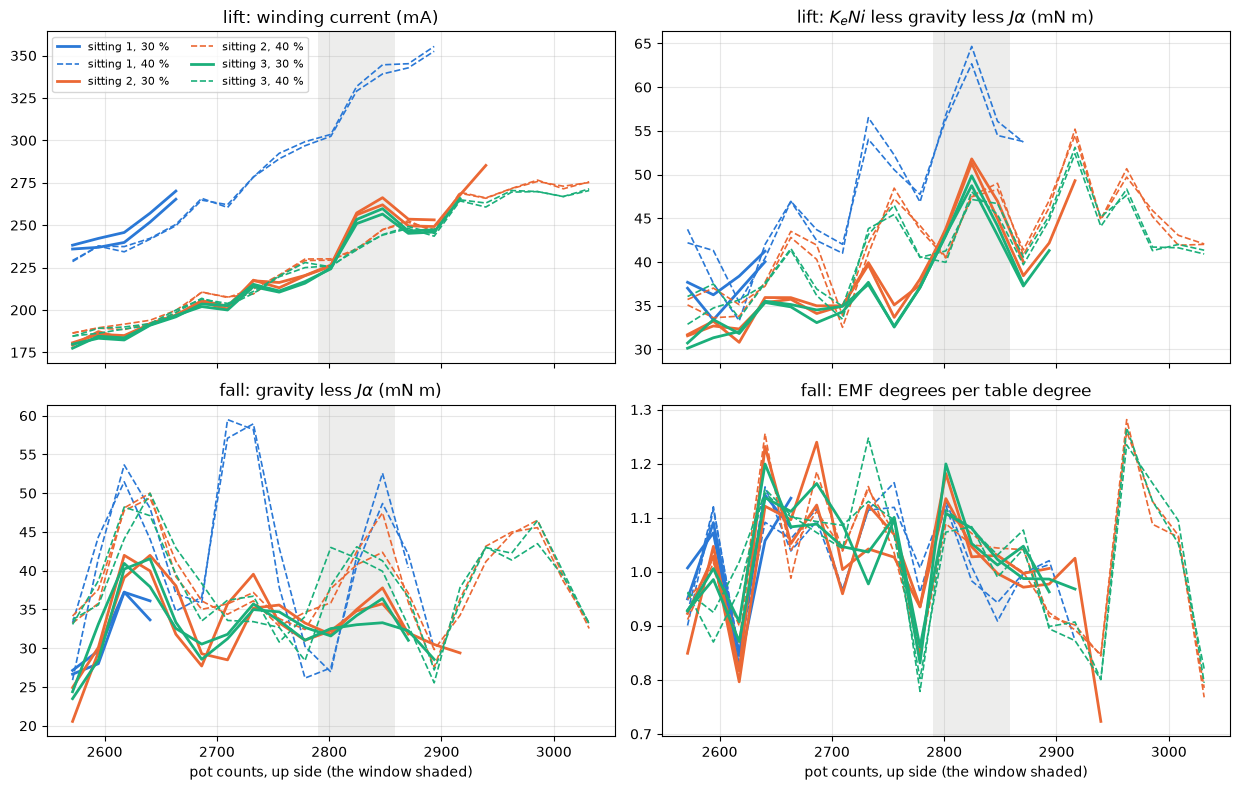

In [100]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8), sharex=True)
panels = ((axes[0, 0], "lift", "i_ma", "lift: winding current (mA)"),
          (axes[0, 1], "lift", "loss", "lift: $K_e N i$ less gravity less "
           "$J \\alpha$ (mN m)"),
          (axes[1, 0], "fall", "loss", "fall: gravity less $J \\alpha$ "
           "(mN m)"),
          (axes[1, 1], "fall", "r", "fall: EMF degrees per table degree"))
for ax, kind, col, title in panels:
    ax.axvspan(*W_UP, color=MUTED, alpha=0.15, lw=0)
    x = CELLS[(CELLS["kind"] == kind) & (CELLS["side"] == 1)
              & (CELLS["duty"] >= 30) & (CELLS["c_lo"] >= 2560)
              & (CELLS["c_hi"] <= 3060)]
    seen = set()
    for (n, k), c in x.groupby(["sitting", "k"]):
        c, duty = c.sort_values("c_lo"), int(c["duty"].iloc[0])
        lab = None if (n, duty) in seen else f"sitting {n}, {duty} %"
        seen.add((n, duty))
        ax.plot((c["c_lo"] + c["c_hi"]) / 2, c[col], color=SIT_COLOR[n],
                lw=2 if duty == 30 else 1.2,
                ls="-" if duty == 30 else "--", label=lab)
    figures.label(ax, title=title, x="pot counts, up side (the window "
                  "shaded)" if kind == "fall" else None)
axes[0, 0].legend(fontsize=8, ncol=2)
figures.finish(fig)

A flat place in the pot would hold the reading still while the output turns, so the motor's EMF travel per pot count would rise through the window. Holding those rungs that way needs the travel up 4.2 to 7.9 times. The lifts and falls through the up window read 1.07 +/- 0.01 and 1.03 +/- 0.01 of their flanks, and the table's own slope there is 0.0538 degrees per count against 0.0557 on the flanks. A flat place in the pot is ruled out.

The lifts lose more through the up window, +4.57 +/- 1.33 mN m, with the speed down 12.11 +/- 3.68 % and the current up 8.16 +/- 2.47 mA against the flanks, sitting 1 alone +6.58 mN m and -13.83 %. The size fits the extra hold the sticky rungs need. The same three-cell bump scanned blind over every position varies with an sd of 3.0 to 4.7 mN m on the lifts, and the up window ranks 15 of 39 on the light arm's lifts (+1.2 +/- 1.3) and 6 of 40 on its falls (+6.6 +/- 1.3). The down-side windows show no bump on the lifts, +0.53 at 1088 to 1157 counts and -4.24 at 1295 to 1364. A tight place at the up window fits the lifts, and it is not exceptional among the positions.

What you are looking at. The up side's lifts and falls at 30 and 40 % cut into cells of 23 counts, about one motor turn at the output, around the shaded up window. Top, the lift's current and loss. Bottom, the fall's friction and its EMF degrees per table degree.

In [101]:
KBAR = torque_line(CURVE[CURVE["matched"]])["slope"]   # pooled, below
rows = []
for n in SITTINGS:
    d = CURVE[CURVE["sitting"] == n]
    j = d[d["side"] == 1].merge(d[d["side"] == -1], on="duty_pct",
                                suffixes=("_u", "_d"))
    # torque held down less up, the small current gap out at KBAR
    j["d_tau"] = (j["tau_mn_m_d"] - j["tau_mn_m_u"]
                  - KBAR * (j["i_w_a_d"] - j["i_w_a_u"]))
    j["both_matched"] = j["matched_u"] & j["matched_d"]
    rows.append(j.assign(sitting=n))
OFFSET = pd.concat(rows, ignore_index=True)
for n, x in OFFSET.groupby("sitting"):
    xm = x[x["both_matched"]]
    tr = results.fit_line(xm["i_w_a_u"], xm["d_tau"])
    print(f"sitting {n}: below the edge {mean_pm(xm['d_tau'])} mN m, "
          f"trend {tr['slope']:+.0f} +/- {tr['slope_se']:.0f} mN m/A "
          f"({tr['slope'] / tr['slope_se']:+.1f} sigma); the up rung in "
          f"the window {mean_pm(x[x['in_up_u']]['d_tau'])}")

sitting 1: below the edge +3.14 +/- 0.90 (n 9) mN m, trend +4 +/- 18 mN m/A (+0.2 sigma); the up rung in the window +4.14 +/- 3.62 (n 2)
sitting 2: below the edge +1.04 +/- 0.69 (n 6) mN m, trend +35 +/- 12 mN m/A (+2.9 sigma); the up rung in the window +7.32 +/- 4.40 (n 2)
sitting 3: below the edge -1.17 +/- 1.08 (n 8) mN m, trend +37 +/- 19 mN m/A (+2.0 sigma); the up rung in the window +5.48 +/- 2.88 (n 3)


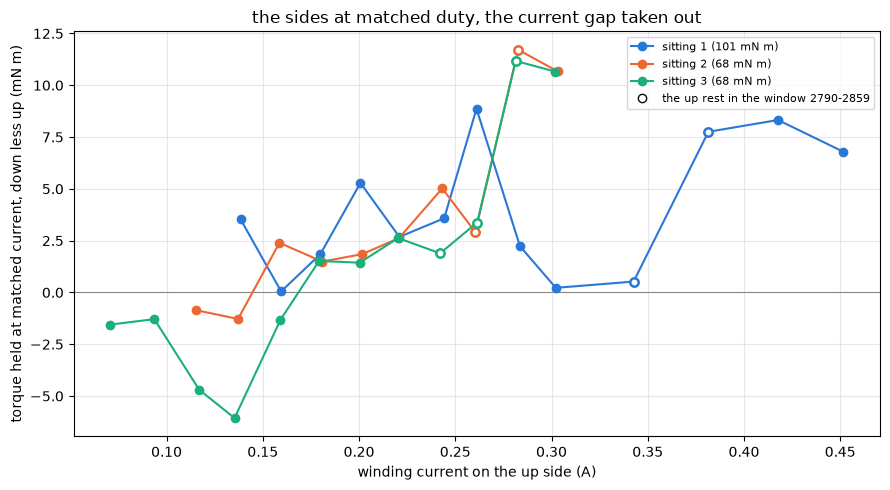

In [102]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.axhline(0, color=MUTED, lw=0.8)
for n, x in OFFSET.groupby("sitting"):
    x = x.sort_values("i_w_a_u")
    ax.plot(x["i_w_a_u"], x["d_tau"], "-o", color=SIT_COLOR[n],
            label=f"sitting {n} ({SITS.loc[n, 'tau_h']:.0f} mN m)")
    w = x[x["in_up_u"]]
    ax.plot(w["i_w_a_u"], w["d_tau"], "o", color="white", mec=SIT_COLOR[n],
            mew=1.8)
ax.plot([], [], "o", color="white", mec=INK, label="the up rest in the "
        "window 2790-2859")
figures.label(ax, x="winding current on the up side (A)",
              y="torque held at matched current, down less up (mN m)",
              title="the sides at matched duty, the current gap taken out")
ax.legend(fontsize=8)
figures.finish(fig)

In [103]:
lifts = CELLS[(CELLS["kind"] == "lift") & (CELLS["t_mid"] > 0.08)
              & CELLS["loss"].notna()]
MOTION_GAP = []         # mN m, up less down, per group and duty
for (g, duty), x in lifts.groupby(["grp", "duty"]):
    top = x.groupby(["sitting", "k"])["theta"].max().min()
    hi = min(40.0, top - 3)     # deg, a range every traverse covers
    if hi < 20:
        continue
    y = x[(x["theta"] >= 15) & (x["theta"] <= hi)]
    t = y.groupby(["sitting", "k", "side"])["loss"].mean().reset_index()
    u, d = t[t["side"] == 1]["loss"], t[t["side"] == -1]["loss"]
    gap = u.mean() - d.mean()
    MOTION_GAP.append(gap)
    se = np.hypot(u.std() / np.sqrt(len(u)), d.std() / np.sqrt(len(d)))
    print(f"{g:5s} {duty} %, 15 to {hi:.0f} deg: lift loss up "
          f"{u.mean():.1f}, down {d.mean():.1f}, up less down {gap:+.1f}"
          f" +/- {se:.1f} mN m (n {len(u)}, {len(d)})")

s1    30 %, 15 to 31 deg: lift loss up 36.5, down 32.8, up less down +3.7 +/- 0.2 mN m (n 2, 2)
s1    40 %, 15 to 40 deg: lift loss up 41.2, down 39.4, up less down +1.8 +/- 0.6 mN m (n 2, 2)
s2+3  20 %, 15 to 21 deg: lift loss up 26.4, down 25.2, up less down +1.2 +/- 0.6 mN m (n 4, 4)
s2+3  30 %, 15 to 40 deg: lift loss up 33.4, down 31.2, up less down +2.2 +/- 0.3 mN m (n 4, 4)
s2+3  40 %, 15 to 40 deg: lift loss up 37.7, down 35.6, up less down +2.1 +/- 0.5 mN m (n 4, 4)


Under the dip sits a constant offset between the sides, the up side losing more. In motion, the lifts' loss over 15 to 40 degrees, below the window, runs up less down +3.7 and +1.8 mN m at 30 and 40 % in sitting 1 and +1.2, +2.2 and +2.1 at 20, 30 and 40 % in sittings 2 and 3, five of five the same sign. At rest below the edge, sitting 1's down side holds +3.14 +/- 0.90 mN m more at matched current, with no trend in current (+4 +/- 18 mN m/A). Sittings 2 and 3 give +1.04 +/- 0.69 and -1.17 +/- 1.08 with trends of +35 +/- 12 and +37 +/- 19 mN m/A, +2.9 and +2.0 sigma.

What you are looking at. At each duty both sides reached, the torque the down side held less the up side's, the small current gap taken out at the pooled slope, against the up side's current. Open circles are the duties whose up rest sits in the window.

In [104]:
for name in ("all", "below the edge"):
    sel = CURVE[SELECT[name]]
    arms = {s: joint_arm(sel[sel["side"] == s], (s,)) for s in (1, -1)}
    arms["both"] = joint_arm(sel)
    print(f"{name}: " + "; ".join(
        f"{key} A {a:.1f} +/- {se:.1f}" for key, (a, se, _) in arms.items())
        + f" mN m (weighed {TAU_ARM:.2f})")
    if name == "below the edge":
        ARM_MATCHED = arms
weight = COINS_G / 1e3 * G_N_PER_KG             # N, the 22 quarters
dip = -BAND_TABLE["residuals"].str.split().explode().astype(float).min()
print(f"the coins weigh {weight:.2f} N; {dip:.1f} mN m is "
      f"{dip / weight:.1f} mm of their travel along the beam")

all: 1 A 24.9 +/- 4.1; -1 A 12.8 +/- 3.3; both A 18.2 +/- 2.7 mN m (weighed 17.04)
below the edge: 1 A 16.9 +/- 4.1; -1 A 14.2 +/- 6.0; both A 15.6 +/- 3.5 mN m (weighed 17.04)
the coins weigh 1.22 N; 6.3 mN m is 5.2 mm of their travel along the beam


Below the edge the arm's term agrees with the scale on each side, 16.9 +/- 4.1 mN m up, 14.2 +/- 6.0 down and 15.6 +/- 3.5 both, against the weighed 17.04. The per-side gap over the full range, 24.9 against 12.8, was the same bend above 41.5 degrees.

In [105]:
PER_CUP = N_COINS // 2                  # quarters in each cup of a pair
ROOM_MM = (RIG.stack_n - PER_CUP) * RIG.unit_t + RIG.cup_room
SHIFT_MM = RIG.cup_clear / 2                # the coins' play in the bore
COIN_BOUND = SHIFT_MM * weight              # mN m, N times mm
print(f"cup bore {RIG.unit_d:.2f} + {RIG.cup_clear:.1f} mm on the "
      f"diameter; {PER_CUP} coins in a cup built for {RIG.stack_n}, "
      f"{ROOM_MM:.2f} mm of room over the stack")
print(f"a shift of {SHIFT_MM:.1f} mm at {weight:.2f} N moves "
      f"{COIN_BOUND:.2f} mN m, {COIN_BOUND / dip:.2f} of the {dip:.1f} "
      f"mN m dip")

cup bore 24.26 + 1.0 mm on the diameter; 11 coins in a cup built for 12, 2.25 mm of room over the stack
a shift of 0.5 mm at 1.22 N moves 0.61 mN m, 0.10 of the 6.3 mN m dip


The dip at 42 to 49 degrees from the bottom shows on both sides, at all three sittings and both masses, about -6.3 mN m on the up side and -3.3 on the down. Its cause is open.

| hypothesis | predicts | evidence | confidence |
|:-|:-|:-|:-|
| A. Something that rides with the arm's angle, such as the coins shifting in their cups near 45 degrees of tilt or the arm on the horn | the same angle on both sides and at both masses, a torque step that persists above it, and a dip that moves with the arm when the arm is re-seated and goes away with the coins packed | both sides dip at 42 to 49 degrees and the light arm's up rests stay low above it. By hand the coins slide and rattle in their cups. The design clearance of 1.0 mm on the diameter allows a 0.5 mm shift, 0.61 mN m at the coins' 1.22 N, about a tenth of the dip, which needs 5.2 mm. The coins explain it only if the printed bore is far wider than designed or the stack tips in the 2.25 mm of room over it | moderate |
| B. Two tight places in the train, at counts 2790 to 2859 and near 1088 to 1196 | a dip that stays at the counts when the arm is re-seated, and a bump the next rungs clear | the heavy arm's up rests return toward the line at 56 to 64 degrees, the lifts' loss bump in the up window, and it needs two places at mirror angles | moderate |
| C. A direction-dependent efficiency, a ratio of Kt through the gears | the same ratio at both masses and straight lines | 1.045 against 1.198 below the edge, and the light arm's down line bends | low for more than 5 % |
| D. A flat place in the pot | EMF travel per count up 4.2 to 7.9 times | measured 1.07 | ruled out |

Two short ladders separate A from B. Pack the coins so they stay put and repeat one from-below ladder, and re-seat the arm 2 or 3 spline teeth and repeat one ladder, each with 1 % steps over the duties that bracket 42 to 49 degrees. Under A the dip goes away with the coins packed or moves with the re-seated arm. Under B it stays at the counts both times.

For the firmware numbers nothing moves outside its bracket. A stage 5 gravity feed-forward built on one Kt through the gears for both directions is off by at most about 6 mN m at 42 to 49 degrees, inside the static friction band of section 11.4.

### 11.4 The deadband and the band

Each chain held a ladder duty for 2 s, stepped the duty by a size for 0.5 s, then stepped back for 0.5 s. Sitting 2 stepped by 10, 15 and 20 % and sitting 3 by 10, 15, 20 and 25 %, both ways, at two angles a side. Per edge the motion runs from 1 ms after the duty register flips, and a move is a change over 1 degree, outside the horn's 1.2 degree lash. The motor's torque a step adds or takes is the settled current change through the side's Kt through the gears. The edges follow the analysis' definitions, which differ from section 5's `step_row` in the start of the motion and the current before the edge, so section 5's helper is not reused here.

In [106]:
KT_SIDE = {s: KT3[(s, "s2+3")]["slope"] for s in (1, -1)}   # mN m/A
MOVE_DEG = 1.0          # deg, the horn's lash is 1.2: a twitch inside it
TICKS_PER_PCT = ARR / 100                   # timer ticks per % of duty
print(f"Kt_gear for the steps, sittings 2 and 3: up {KT_SIDE[1]:.1f}, down "
      f"{KT_SIDE[-1]:.1f} mN m/A; a move is over {MOVE_DEG} deg; "
      f"{TICKS_PER_PCT:.0f} ticks per % of duty")


def i_before_of(df, s, seg, e):
    """The current at the duty the edge leaves: the step's last 50 ms
    for the step back, the 20 ms before the flip when streamed, else the
    base duty's last 50 ms after the step back, the same hold 0.5 s on."""
    if seg == 4:
        return df[df["seg"] == 3]["i_a"].iloc[-END_ROWS:].mean()
    if e >= 40:
        return s["i_a"].iloc[max(0, e - 400):e].mean()
    return df[df["seg"] == 4]["i_a"].iloc[-END_ROWS:].mean()

Kt_gear for the steps, sittings 2 and 3: up 198.2, down 258.9 mN m/A; a move is over 1.0 deg; 12 ticks per % of duty


In [107]:
def edge_row(n, r, df, seg):
    """One edge of a chain: the motion from 1 ms after the duty flips
    and its time course, and the current's jump and settled change."""
    s = df[df["seg"] == seg].reset_index(drop=True)
    e, held = tel.flip_row(s)
    pos0 = (df[df["seg"] == 3]["pos"].iloc[-END_ROWS:].median() if seg == 4
            else s["pos"].iloc[e:e + 20].median())
    after = s.iloc[e:].reset_index(drop=True)
    a = angle_of(after["pos"].to_numpy()) - angle_of(pos0)   # deg, signed
    a_end, i = a[-END_ROWS:].mean(), after["i_a"].to_numpy()
    w = pot_speed(after["pos"].to_numpy(), 100)               # deg/s
    moved = abs(a_end) > MOVE_DEG
    late = np.flatnonzero(np.abs(a - a_end) > 0.5)
    first = np.flatnonzero(np.abs(a) > 0.5)
    i0 = i_before_of(df, s, seg, e)
    bottom = SITS.loc[n, "bottom"]
    return {"sitting": n, "k": int(r["k"]), "side": int(r["side"]),
            "base_pct": int(r["duty_pct"]), "step_pct": int(r["step_pct"]),
            "edge": "step" if seg == 3 else "back", "ticks_to": held,
            "theta_before": float(theta_deg(pos0, bottom)),
            "theta_after": float(theta_deg(after["pos"].iloc[-END_ROWS:]
                                           .median(), bottom)),
            "d_theta_side": a_end * np.sign(r["side"]), "moved": moved,
            "i_before_ma": i0 * 1e3, "di_jump_ma": (i[JUMP].mean() - i0) * 1e3,
            "di_end_ma": (i[-END_ROWS:].mean() - i0) * 1e3,
            "delay_ms": first[0] / FS * 1e3 if len(first) else np.nan,
            "t10_ms": np.flatnonzero(np.abs(a) > 0.1 * abs(a_end))[0] / FS
            * 1e3 if moved else np.nan,
            "t90_ms": np.flatnonzero(np.abs(a) > 0.9 * abs(a_end))[0] / FS
            * 1e3 if moved else np.nan,
            "overshoot_pct": (np.max(a * np.sign(a_end)) / abs(a_end) - 1)
            * 100 if moved else np.nan,
            "w_end_deg_s": np.nanmean(w[-1200:-200]),
            "w_peak_rev_s": np.nanmax(np.abs(w)) / 360 * GEAR,
            "trace": (np.arange(len(after)) / FS, a * np.sign(r["side"]))}

In [108]:
rows = []
for n in (2, 3):
    chains = pd.read_csv(DATA / f"steps-{n}" / "chains.csv")
    for _, r in chains.iterrows():
        df, _ = load_sweep(DATA / f"steps-{n}" / r["folder"])
        rows += [edge_row(n, r, df, seg) for seg in (3, 4)]
EDGES = pd.DataFrame(rows)
EDGES["duty_from"] = np.where(EDGES["edge"] == "step", EDGES["base_pct"],
                              (EDGES["base_pct"] + EDGES["step_pct"]))
EDGES["duty_to"] = EDGES["ticks_to"] / TICKS_PER_PCT
EDGES["d_duty"] = EDGES["duty_to"] - EDGES["duty_from"]
EDGES["i_window_ok"] = EDGES["ticks_to"] >= BOARD.i_window_min_ticks
EDGES["still_moving"] = EDGES["w_end_deg_s"].abs() > 5     # deg/s
# the motor torque the step added or took, settled, through Kt_gear
EDGES["torque_step_mn_m"] = (EDGES["side"].map(KT_SIDE)
                             * EDGES["di_end_ma"] / 1e3)
ladder_rest = below.set_index(["sitting", "side", "duty_pct"])["theta"]
key = list(zip(EDGES["sitting"], EDGES["side"], EDGES["base_pct"]
               + np.where(EDGES["edge"] == "step", EDGES["step_pct"], 0)))
EDGES["theta_new_rest"] = [ladder_rest.get(q, np.nan) for q in key]
EDGES["short_deg"] = (EDGES["theta_new_rest"].abs()
                      - EDGES["theta_after"].abs())
print(f"{len(EDGES) // 2} chains, {len(EDGES)} edges; steps "
      f"{sorted(int(x) for x in EDGES['step_pct'].unique())} %")

43 chains, 86 edges; steps [-25, -20, -15, -10, 10, 15, 20, 25] %


In [109]:
rows = []
steps = EDGES[EDGES["edge"] == "step"]
for (n, side, base), g in steps.groupby(["sitting", "side", "base_pct"]):
    for sign, way in ((1, "up"), (-1, "down")):
        gg = g[np.sign(g["step_pct"]) == sign]
        mv, still = gg[gg["moved"]], gg[~gg["moved"]]
        small = mv["step_pct"].abs().min() if len(mv) else np.nan
        large = still["step_pct"].abs().max() if len(still) else np.nan
        pick = lambda d, p, col: (d.loc[d["step_pct"].abs() == p, col]
                                  .abs().iloc[0] if len(d) else np.nan)
        rows.append({"sitting": n, "side": side, "base_pct": base,
                     "theta_deg": g["theta_before"].abs().mean(), "dir": way,
                     "tried": sorted(gg["step_pct"].abs().tolist()),
                     "moved": sorted(mv["step_pct"].abs().tolist()),
                     "still_mn_m": pick(still, large, "torque_step_mn_m"),
                     "moved_mn_m": pick(mv, small, "torque_step_mn_m"),
                     "still_ma": pick(still, large, "di_end_ma"),
                     "moved_ma": pick(mv, small, "di_end_ma")})
BRACKETS = pd.DataFrame(rows)
show(BRACKETS.round(1), n=None)

,sitting,side,base_pct,theta_deg,dir,tried,moved,still_mn_m,moved_mn_m,still_ma,moved_ma
0,2,-1,16,23.300,up,"[10, 15]","[10, 15]",NaN,5.900,NaN,22.900
1,2,-1,16,23.300,down,"[10, 15]",[15],23.100,45.200,89.400,174.400
2,2,1,16,21.900,up,"[10, 15, 20]","[10, 15, 20]",NaN,12.700,NaN,64.200
3,2,1,16,21.900,down,"[10, 15]",[],35.100,NaN,177.000,NaN
4,2,1,30,52.700,up,"[10, 15, 20]","[10, 20]",29.300,13.400,148.000,67.700
5,2,1,30,52.700,down,"[10, 15, 20]",[],41.200,NaN,207.800,NaN
6,3,-1,16,23.400,up,"[10, 15, 20, 25]","[10, 15, 20, 25]",NaN,18.000,NaN,69.700
7,3,-1,16,23.400,down,"[10, 15]",[15],26.900,44.900,104.100,173.400
8,3,-1,26,45.500,up,"[10, 15, 20, 25]","[10, 15, 20, 25]",NaN,10.100,NaN,38.900
9,3,-1,26,45.500,down,"[10, 15, 20, 25]",[25],53.200,65.700,205.600,254.000


In [110]:
rows = []
for (n, side, base), g in BRACKETS.groupby(["sitting", "side", "base_pct"]):
    u = g[g["dir"] == "up"].iloc[0]
    d = g[g["dir"] == "down"].iloc[0]
    rows.append({"sitting": n, "side": side, "base_pct": base,
                 "theta_deg": u["theta_deg"],
                 "rise_lo": u["still_mn_m"], "rise_hi": u["moved_mn_m"],
                 "release_lo": d["still_mn_m"], "release_hi": d["moved_mn_m"],
                 "band_lo": np.nansum([u["still_mn_m"], d["still_mn_m"]]),
                 "band_hi": u["moved_mn_m"] + d["moved_mn_m"]})
BAND3 = pd.DataFrame(rows)
show(BAND3.round(1), n=None)
ok = BAND3.dropna(subset=["band_hi"])
print(f"brackets with both ends: lower {ok['band_lo'].min():.1f} to "
      f"{ok['band_lo'].max():.1f}, upper {ok['band_hi'].min():.1f} to "
      f"{ok['band_hi'].max():.1f} mN m = {ok['band_lo'].min() / GEAR * 1e3:.0f}"
      f" to {ok['band_hi'].max() / GEAR * 1e3:.0f} uN m at the motor")

,sitting,side,base_pct,theta_deg,rise_lo,rise_hi,release_lo,release_hi,band_lo,band_hi
0,2,-1,16,23.300,NaN,5.900,23.100,45.200,23.100,51.100
1,2,1,16,21.900,NaN,12.700,35.100,NaN,35.100,NaN
2,2,1,30,52.700,29.300,13.400,41.200,NaN,70.500,NaN
3,3,-1,16,23.400,NaN,18.000,26.900,44.900,26.900,62.900
4,3,-1,26,45.500,NaN,10.100,53.200,65.700,53.200,75.800
5,3,1,16,21.200,NaN,12.100,35.100,NaN,35.100,NaN
6,3,1,30,53.700,19.800,29.300,50.900,NaN,70.700,NaN


brackets with both ends: lower 23.1 to 53.2, upper 51.1 to 75.8 mN m = 75 to 246 uN m at the motor


Up from a from-below rest, +10 % moved the arm at every rung but sitting 3's 30 % rung at 53.7 degrees, and at sitting 2's 30 % rung +15 % held once where +10 and +20 % moved. After its 2 s hold the arm at 30 % sat inside the band. Down, no cut released the up side, up to -20 % in sitting 2 and -25 % in sitting 3. On the down side -15 % released the arm at 23 degrees in both sittings, and at 45.5 degrees only -25 % did. Adding a rise and a release that held gives the band's lower end, a rise and a release that moved its upper end. With both ends measured the band runs from 23.1 to 51.1 mN m at 23 degrees and from 53.2 to 75.8 at 45.5 degrees, 75 to 246 uN m at the motor. The up side's brackets stay open above, at least 35.1 at 21 to 22 degrees and 70.5 to 70.7 at 53 to 54.

In [111]:
mv = EDGES[(EDGES["edge"] == "step") & EDGES["moved"]]
up = mv[mv["step_pct"] > 0]
rise = up["t90_ms"] - up["t10_ms"]
free = up[up["theta_after"].abs() < 80]       # not run onto a stop
print(f"up steps that moved {len(up)}; short of the ladder rest "
      f"{up['short_deg'].mean():+.2f} sd {up['short_deg'].std():.2f} deg; "
      f"delay {up['delay_ms'].median():.0f} ms ({up['delay_ms'].min():.0f} "
      f"to {up['delay_ms'].max():.0f}); 10-90 % median {rise.median():.0f} "
      f"ms, quartiles {rise.quantile(0.25):.0f} to {rise.quantile(0.75):.0f}"
      f"; overshoot {up['overshoot_pct'].median():.1f} % (max "
      f"{up['overshoot_pct'].max():.1f}); settled in 500 ms "
      f"{int((~up['still_moving']).sum())} of {len(up)}")
print(f"peak motor speed {free['w_peak_rev_s'].min():.0f} to "
      f"{free['w_peak_rev_s'].max():.0f} rev/s over the {len(free)} that "
      f"stayed under 80 deg, {up['w_peak_rev_s'].max():.0f} onto a stop")
back = EDGES[EDGES["edge"] == "back"]
came = back.merge(free[["sitting", "k"]], on=["sitting", "k"])
print(f"the step back after those moved the arm "
      f"{came['d_theta_side'].abs().min():.1f} to "
      f"{came['d_theta_side'].abs().max():.1f} deg")
ok = EDGES[(EDGES["edge"] == "step") & EDGES["i_window_ok"]
           & (EDGES["duty_from"] * TICKS_PER_PCT
              >= BOARD.i_window_min_ticks)]
k_jump, k_end = ok["di_jump_ma"] / ok["d_duty"], ok["di_end_ma"] / ok["d_duty"]
STEP_UP, STEP_RISE, STEP_BACK = up, rise, came    # for the result file
K_STEP3 = (k_jump, k_end)
print(f"current per % of duty at the edge {k_jump.mean():.2f} sd "
      f"{k_jump.std():.2f} mA/% (n {len(ok)}), settled {k_end.mean():.2f} "
      f"sd {k_end.std():.2f}")

up steps that moved 22; short of the ladder rest +1.14 sd 1.01 deg; delay 25 ms (0 to 41); 10-90 % median 338 ms, quartiles 329 to 343; overshoot 3.5 % (max 4.5); settled in 500 ms 4 of 22
peak motor speed 82 to 173 rev/s over the 15 that stayed under 80 deg, 330 onto a stop
the step back after those moved the arm 0.6 to 2.3 deg
current per % of duty at the edge 10.03 sd 1.36 mA/% (n 37), settled 8.06 sd 2.57


In [112]:
pre = EDGES[EDGES["edge"] == "step"]
for base in (16, 30):
    x = pre[(pre["base_pct"] == base)].groupby("side")["theta_before"]
    print(f"{base} % before the step: " + "; ".join(
        f"side {s:+d} {v.abs().min():.1f} to {v.abs().max():.1f} deg"
        for s, v in x))

16 % before the step: side -1 23.1 to 23.9 deg; side +1 20.7 to 22.4 deg
30 % before the step: side +1 49.4 to 56.6 deg


A duty hold is a ratchet. It follows a rise of 10 % of duty, about 100 mA, and holds through a cut of 20 % (section 11.7 lists the events), so the deadband runs up 5 to 10 % (sitting 1's +5 % moved nothing) and down 20 to 25 %. When the arm moves, it goes to the ladder's from-below rest at the new duty, short by +1.14 sd 1.01 degrees over the 22 up steps that moved. The delay to 0.5 degree is 25 ms (0 to 41), the 10 to 90 % rise has a median of 338 ms, the overshoot 3.5 % (4.5 at most), and only 4 of the 22 have settled within 500 ms. Over the 15 moves that stayed under 80 degrees the motor peaks at 82 to 173 rev/s. The step back to the base duty returns the arm by only 0.6 to 2.3 degrees, so the arm stays at the higher rest. The current steps 10.03 sd 1.36 mA per % of duty at the edge, as in sitting 1, and 8.06 settled, since the moving arm takes volts. Before a step the 2 s hold at 16 % leaves a side's rests within 1.7 degrees of each other, and at 30 % the up side's rests spread from 49.4 to 56.6 degrees, the band carrying the arm wherever it stopped.

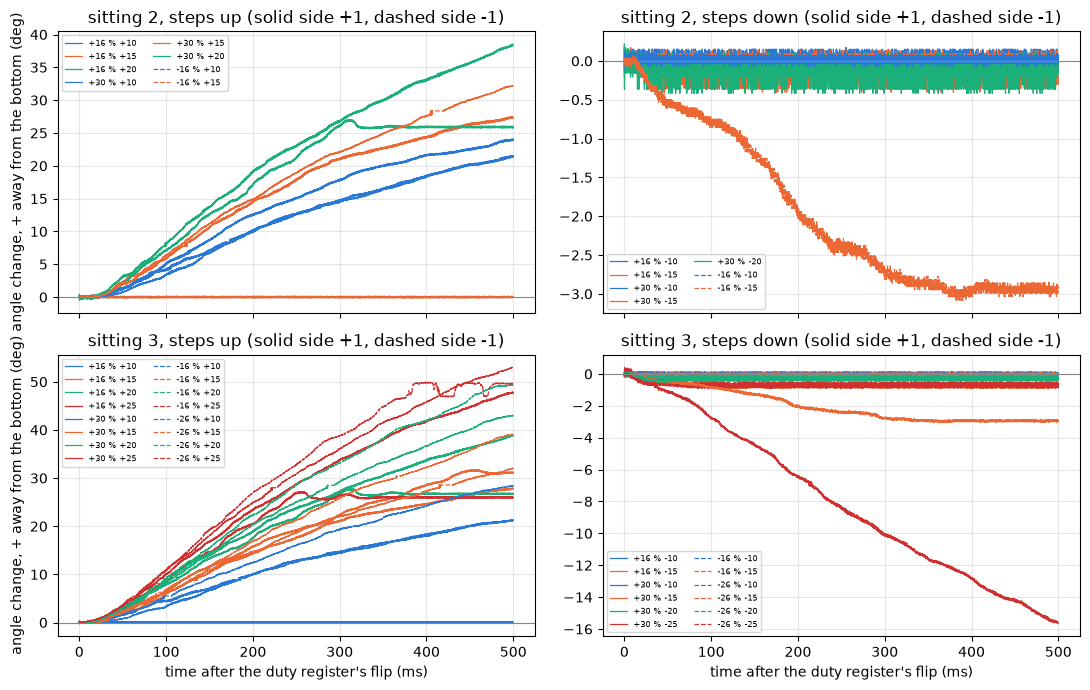

In [113]:
STEP_COLOR = {10: BLUE, 15: ORANGE, 20: GREEN, 25: RED}
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for row, n in zip(axes, (2, 3)):
    for ax, sign, way in ((row[0], 1, "up"), (row[1], -1, "down")):
        d = EDGES[(EDGES["sitting"] == n) & (EDGES["edge"] == "step")
                  & (np.sign(EDGES["step_pct"]) == sign)]
        for _, r in d.iterrows():
            t, a = r["trace"]
            ax.plot(t * 1e3, a, lw=0.9, color=STEP_COLOR[abs(r["step_pct"])],
                    ls="-" if r["side"] > 0 else "--",
                    label=f"{r['side'] * r['base_pct']:+d} % "
                    f"{r['step_pct']:+d}")
        ax.axhline(0, color=MUTED, lw=0.8)
        figures.label(ax, title=f"sitting {n}, steps {way} (solid side +1"
                      ", dashed side -1)")
        ax.legend(fontsize=6, ncol=2)
for ax in axes[1]:
    ax.set_xlabel("time after the duty register's flip (ms)")
for ax in axes[:, 0]:
    ax.set_ylabel("angle change, + away from the bottom (deg)")
figures.finish(fig)

What you are looking at. The angle after each step, positive away from the bottom, by sitting and by the step's sign, colored by its size. The up steps rise over a few hundred ms and the down steps mostly stay at zero.

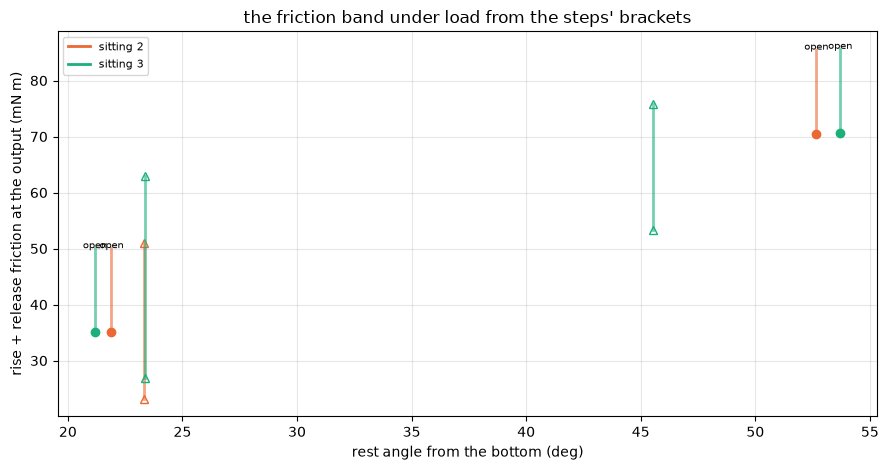

In [114]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for _, r in BAND3.iterrows():
    style = figures.direction_style(r["side"], SIT_COLOR[r["sitting"]])
    hi = r["band_hi"] if np.isfinite(r["band_hi"]) else r["band_lo"] + 15
    ax.plot([r["theta_deg"]] * 2, [r["band_lo"], hi], "-", lw=2, alpha=0.6,
            color=SIT_COLOR[r["sitting"]])
    ax.plot(r["theta_deg"], r["band_lo"], **style)
    if np.isfinite(r["band_hi"]):
        ax.plot(r["theta_deg"], r["band_hi"], **style)
    else:
        ax.annotate("open", (r["theta_deg"], hi), fontsize=7, ha="center")
for n in (2, 3):
    ax.plot([], [], "-", color=SIT_COLOR[n], lw=2, label=f"sitting {n}")
figures.label(ax, x="rest angle from the bottom (deg)",
              y="rise + release friction at the output (mN m)",
              title="the friction band under load from the steps' brackets")
ax.legend(fontsize=8)
figures.finish(fig)

What you are looking at. Per rung, the rise plus release friction between the steps that held and the steps that moved, against the rest angle. A bracket marked open has no moving step on one side.

### 11.5 From above, both ways

Sitting 2 approached its from-above rungs 16 % over the duty and walked down a stair of 2 % every 300 ms. Sitting 3 approached from one step over a predicted overshoot and stepped down once. The motor's torque at the end is the winding current through the side's Kt through the gears.

In [115]:
def window_table(df, n):
    """Per streamed segment after the first: its duty, the angle at its
    end and its length."""
    rows = []
    for seg in sorted(df["seg"].unique())[1:]:
        g = df[df["seg"] == seg]
        rows.append({"duty_pct": g["duty_counts"].abs().median()
                     / TICKS_PER_PCT, "pos_last": g["pos"].iloc[-200:].median(),
                     "ms": len(g) / FS * 1e3})
    out = pd.DataFrame(rows)
    out["theta_last"] = theta_deg(out["pos_last"], SITS.loc[n, "bottom"])
    return out


rows, ABOVE_SEGS = [], {}
for _, r in LAD[(LAD["approach"] == "above")
                & (LAD["sitting"] >= 2)].iterrows():
    n, side = int(r["sitting"]), int(r["side"])
    df, _ = load_sweep(DATA / f"ladder-{n}" / f"ladder/{int(r['k'])}")
    per = window_table(df, n)
    ABOVE_SEGS[(n, int(r["k"]))] = per
    to_stop = min(r["rest_pos"] - SERVO_ENDS[0], SERVO_ENDS[1] - r["rest_pos"])
    grav = SITS.loc[n, "tau_h"] * np.sin(np.radians(abs(r["theta"])))
    motor = KT_SIDE[side] * r["i_w_a"]           # mN m at the end
    rows.append({"sitting": n, "k": int(r["k"]), "side": side,
                 "duty_pct": int(r["duty_pct"]),
                 "over_duty": per["duty_pct"].iloc[0],
                 "theta_over": per["theta_last"].iloc[0],
                 "theta_end": per["theta_last"].iloc[-1],
                 "rest_pos": r["rest_pos"], "to_stop": to_stop,
                 "at_stop": to_stop <= 40, "i_end_ma": r["i_w_a"] * 1e3,
                 "motor_mn_m": motor, "gravity_mn_m": grav,
                 "held_mn_m": grav - motor})
ABOVE3 = pd.DataFrame(rows)
show(ABOVE3.round(1), n=None)

,sitting,k,side,duty_pct,over_duty,theta_over,theta_end,rest_pos,to_stop,at_stop,i_end_ma,motor_mn_m,gravity_mn_m,held_mn_m
0,2,29,1,16,32.000,1.400,62.300,3228.000,564.000,False,157.100,31.100,60.100,29.000
1,2,30,1,26,42.000,6.200,82.100,3760.000,32.000,True,256.400,50.800,67.200,16.400
2,2,31,1,34,50.000,13.100,82.600,3775.000,17.000,True,333.500,66.100,67.300,1.200
3,2,32,-1,16,32.000,-19.900,-73.300,579.000,497.000,False,155.800,40.300,65.000,24.700
4,2,33,-1,24,40.000,-7.100,-92.600,94.000,12.000,True,236.300,61.200,67.800,6.700
5,2,34,-1,30,46.000,-8.000,-93.100,82.000,0.000,True,295.300,76.400,67.800,-8.600
6,3,29,1,16,36.000,20.700,66.900,3352.000,440.000,False,157.400,31.200,62.500,31.300
7,3,30,1,26,36.000,2.300,68.900,3406.000,386.000,False,260.100,51.500,63.400,11.800
8,3,31,-1,16,32.000,-19.600,-71.200,630.000,548.000,False,192.500,49.800,64.300,14.500


In [116]:
STAIR_MAX = 0           # counts, the largest move of one stair step
for (n, k), per in ABOVE_SEGS.items():
    if n != 2:
        continue
    stair = per["pos_last"].iloc[1:-2]          # the 2 % steps
    moves = np.diff(np.r_[per["pos_last"].iloc[0], stair])
    STAIR_MAX = max(STAIR_MAX, np.abs(moves[1:]).max())
    # the first entry is the rise under the overshoot to the first step
    print(f"sitting 2 k{k}: rose {abs(moves[0]):.0f} counts by the first 2 % "
          f"step, then {np.abs(moves[1:]).max():.0f} counts at most per "
          f"step over the next {len(moves) - 1}; the hold's end "
          f"{per['pos_last'].iloc[-1] - stair.iloc[0]:+.0f} counts from the "
          f"first step's")
at = ABOVE3[ABOVE3["at_stop"]]
print("at the stop: " + "; ".join(
    f"k{r.k} {r.side * r.duty_pct:+d} % at {r.rest_pos:.0f} counts "
    f"({abs(r.theta_end):.0f} deg), {r.i_end_ma:.0f} mA, motor "
    f"{r.motor_mn_m:.0f} against gravity {r.gravity_mn_m:.0f} mN m"
    for r in at.itertuples()))

sitting 2 k29: rose 1181 counts by the first 2 % step, then 0 counts at most per step over the next 6; the hold's end +0 counts from the first step's
sitting 2 k30: rose 1637 counts by the first 2 % step, then 1 counts at most per step over the next 6; the hold's end -1 counts from the first step's
sitting 2 k31: rose 1521 counts by the first 2 % step, then 0 counts at most per step over the next 6; the hold's end +0 counts from the first step's
sitting 2 k32: rose 1088 counts by the first 2 % step, then 0 counts at most per step over the next 6; the hold's end +1 counts from the first step's
sitting 2 k33: rose 1786 counts by the first 2 % step, then 0 counts at most per step over the next 6; the hold's end +0 counts from the first step's
sitting 2 k34: rose 1782 counts by the first 2 % step, then 0 counts at most per step over the next 6; the hold's end +0 counts from the first step's
at the stop: k30 +26 % at 3760 counts (82 deg), 256 mA, motor 51 against gravity 67 mN m; k31 +34 % 

Sitting 2's overshoot carried the arm over the top on four of six rungs, k30 and k31 to 3760 and 3775 counts and k33 and k34 to 94 and 82, against the stops at 236 to 334 mA. After the rise none of the six moved more than 1 count per stair step. At the stop gravity past 90 degrees pushes the arm into the stop, so those rests are the stop's reaction plus the motor, not a friction reading. Sitting 3's three rungs all stayed at 66.9 to 71.2 degrees after the step down, holding 31.3, 11.8 and 14.5 mN m with the motor's share taken off, and sitting 2's two rungs that missed the stops held 29.0 and 24.7. A stair of 2 % does not walk a load down this train. The release needs a cut of 20 to 25 % at once.

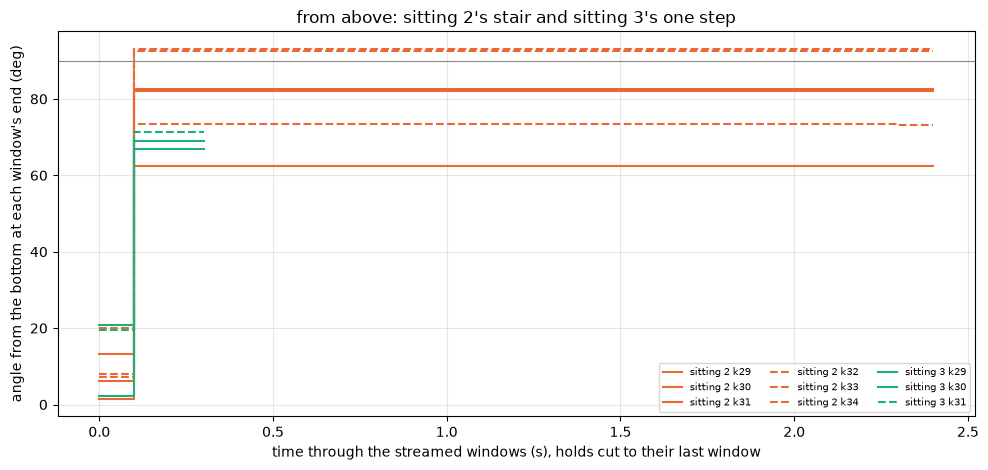

In [117]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for (n, k), per in ABOVE_SEGS.items():
    t = np.cumsum(np.r_[0, per["ms"].to_numpy()]) / 1e3
    th = per["theta_last"].abs().to_numpy()
    ax.step(t, np.r_[th, th[-1]], where="post", color=SIT_COLOR[n],
            ls="-" if per["theta_last"].iloc[-1] > 0 else "--",
            label=f"sitting {n} k{k}")
ax.axhline(90, color=MUTED, lw=0.8)
figures.label(ax, x="time through the streamed windows (s), holds cut to "
              "their last window", y="angle from the bottom at each "
              "window's end (deg)",
              title="from above: sitting 2's stair and sitting 3's one step")
ax.legend(fontsize=7, ncol=3)
figures.finish(fig)

What you are looking at. The angle at the end of each streamed window through the from-above schedules, holds cut to their last window. Sitting 2's stairs stay flat after the first window.

### 11.6 The lift and the fall of the lighter arm

The lifts go through sitting 1's `lift_row` with each sitting's drive rows and bottom. The loss share is $R_C (i_w - i_{free}) / K_e$ over the free rung's speed less the loaded speed, both currents under construction C. The falls follow section 7's definitions with each sitting's gravity and inertia.

In [118]:
LIFT3, FALL3_ROWS, LIFT3_TRACES = [], {}, {}
for n in SITTINGS:
    cyc = pd.read_csv(DATA / f"lift-{n}" / "cycles.csv")
    drive, traces = {}, {}
    for _, r in cyc.iterrows():
        df, _ = load_sweep(DATA / f"lift-{n}" / r["folder"])
        s1 = df[df["seg"] == 1].reset_index(drop=True)
        s2 = df[df["seg"] == 2].reset_index(drop=True)
        drive[r["k"]] = tel.drive_rows(s1).reset_index(drop=True)
        z = int(np.flatnonzero(s2["duty_counts"].to_numpy() == 0)[0]) + 2
        FALL3_ROWS[(n, r["k"])] = s2.iloc[z:].reset_index(drop=True)
    rows = pd.DataFrame([lift_row(r, drive, SITS.loc[n, "bottom"], traces)
                         for _, r in cyc.iterrows()])
    for k, d in drive.items():      # the free rung's current under C too
        v_on = np.abs(d["vdiff_v"].iloc[40:]).mean()
        r = rows[rows["k"] == k].iloc[0]
        rows.loc[rows["k"] == k, "i_free_c"] = construction_c(
            r["duty_pct"] / 100, v_on, r["i_free"])[1]
    LIFT3.append(rows.assign(sitting=n))
    LIFT3_TRACES[n] = traces
LIFT3 = pd.concat(LIFT3, ignore_index=True)
for a0 in (10, 20, 30):
    LIFT3[f"lost_{a0}"] = LIFT3["w_free"] - LIFT3[f"w_{a0}"]   # rev/s
    LIFT3[f"pred_{a0}"] = (R_C * (LIFT3[f"i_{a0}"] - LIFT3["i_free_c"])
                           / KE / (2 * np.pi))                  # rev/s
    LIFT3[f"share_{a0}"] = LIFT3[f"pred_{a0}"] / LIFT3[f"lost_{a0}"]
speeds = LIFT3.groupby(["side", "duty_pct", "sitting"])[
    ["w_10", "w_20", "w_30"]].mean().round(0)
print(speeds.unstack("sitting").to_string())

                w_10                 w_20                 w_30              
sitting            1      2      3      1      2      3      1      2      3
side duty_pct                                                               
-1   20         62.0   66.0   60.0   14.0   51.0   52.0    NaN   26.0   25.0
     30        122.0  114.0  133.0  104.0  120.0  119.0   63.0   99.0   95.0
     40        137.0  172.0  165.0  157.0  177.0  176.0  136.0  165.0  159.0
 1   20         53.0   51.0   55.0    4.0   38.0   40.0    NaN   14.0   16.0
     30         99.0  110.0  114.0   82.0   97.0   94.0   44.0   76.0   74.0
     40        140.0  147.0  146.0  137.0  153.0  147.0  111.0  135.0  132.0


In [119]:
# the share's median at each of 10, 20 and 30 deg, per sitting and side
for (n, side), d in LIFT3.groupby(["sitting", "side"]):
    med = [d[f"share_{a0}"].median() for a0 in (10, 20, 30)]
    print(f"sitting {n} side {side:+d}: R_C di / Ke explains "
          + ", ".join(f"{m:.2f}" for m in med)
          + " of the loss at 10, 20, 30 deg (medians)")

sitting 1 side -1: R_C di / Ke explains 1.10, 1.15, 1.07 of the loss at 10, 20, 30 deg (medians)
sitting 1 side +1: R_C di / Ke explains 0.72, 0.83, 0.88 of the loss at 10, 20, 30 deg (medians)
sitting 2 side -1: R_C di / Ke explains 0.84, 1.16, 1.22 of the loss at 10, 20, 30 deg (medians)
sitting 2 side +1: R_C di / Ke explains 0.66, 0.78, 0.85 of the loss at 10, 20, 30 deg (medians)
sitting 3 side -1: R_C di / Ke explains 0.69, 1.16, 1.09 of the loss at 10, 20, 30 deg (medians)
sitting 3 side +1: R_C di / Ke explains 0.61, 0.66, 0.80 of the loss at 10, 20, 30 deg (medians)


At matched duty the light arm lifts faster, and the gap grows with the angle. At 30 degrees +30 % runs 76 and 74 rev/s against the heavy arm's 44, -30 % runs 99 and 95 against 63, and +40 % 135 and 132 against 111. The winding's resistance explains 0.61 to 0.85 of the loss on the up side and 0.69 to 1.22 on the down side, against sitting 1's 0.72 to 0.88 and 1.07 to 1.15. The down side's share sits higher at both masses, the same side pattern as section 11.3 in motion.

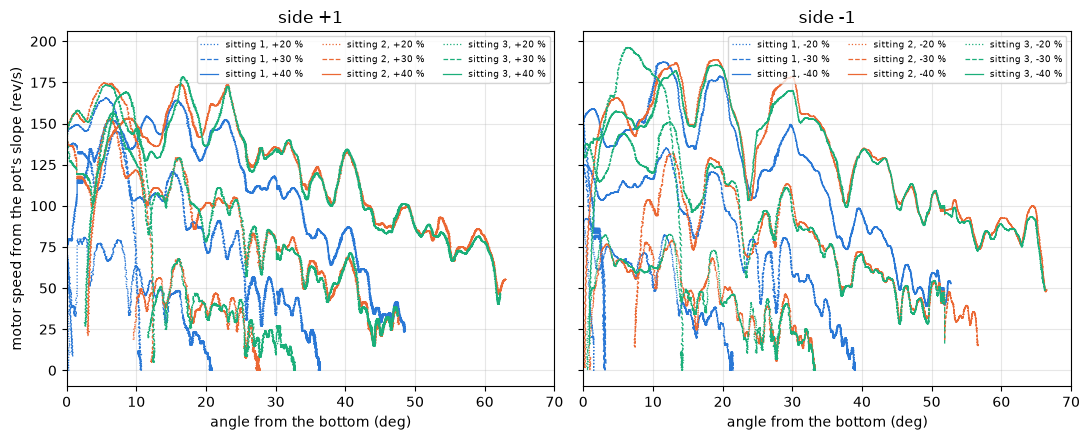

In [120]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, side in zip(axes, (1, -1)):
    for n in SITTINGS:
        d = LIFT3[(LIFT3["sitting"] == n) & (LIFT3["side"] == side)
                  & (LIFT3["repeat"] == 0)]
        for _, r in d.iterrows():
            th, w = LIFT3_TRACES[n][r["k"]]
            ax.plot(th, w, lw=0.9, color=SIT_COLOR[n],
                    ls={20: ":", 30: "--", 40: "-"}[r["duty_pct"]],
                    label=f"sitting {n}, {side * r['duty_pct']:+d} %")
    figures.label(ax, x="angle from the bottom (deg)",
                  title=f"side {side:+d}")
    ax.set_xlim(0, 70)
    ax.legend(fontsize=6.5, ncol=3)
axes[0].set_ylabel("motor speed from the pot's slope (rev/s)")
figures.finish(fig)

What you are looking at. The motor speed from the pot's slope against the angle through each first lift, one color per sitting, dotted at 20 %, dashed at 30 % and solid at 40 %.

In [121]:
SG_FALL = 801           # rows, the Savitzky-Golay window, 40 ms


def inner_fall(n, f, side):
    """One fall: the speed from the pot and from the EMF, the friction at
    the speed peak, the EMF's travel against the pot's, Coulomb + viscous
    by least squares over |w| > 20 deg/s."""
    tf = np.arange(len(f)) / FS
    th = np.asarray(theta_deg(f["pos"], SITS.loc[n, "bottom"]))
    w = savgol_filter(th, SG_FALL, 3, deriv=1, delta=1 / FS)    # deg/s
    al = savgol_filter(th, SG_FALL, 3, deriv=2, delta=1 / FS)   # deg/s2
    w_emf = emf_deg_s(f["emf_v"].to_numpy())
    peak = int(np.nanargmax(np.abs(w[:40000])))
    fast = np.abs(w) > 100
    end = f["pos"].iloc[-10000:].median()
    moving = np.flatnonzero(np.abs(f["pos"].to_numpy() - end) > 3)
    stop = moving[-1] + 1 if len(moving) else 0
    travel = th[min(stop, len(th) - 1)] - th[0]
    j, tau_h = SITS.loc[n, "j_out"], SITS.loc[n, "tau_h"] / 1e3   # SI
    mv = np.abs(w) > 20
    y = j * np.radians(al[mv]) + tau_h * np.sin(np.radians(th[mv]))
    design = np.c_[-np.sign(w[mv]), -np.radians(w[mv])]
    coef = np.linalg.lstsq(design, y, rcond=None)[0]
    return {"sitting": n, "side": side, "theta0": th[0],
            "w_peak": w[peak], "friction_peak": SITS.loc[n, "tau_h"]
            * np.sin(np.radians(abs(th[peak]))),
            "emf_over_pot": np.nanmean(w_emf[fast] / w[fast])
            if fast.sum() > 200 else np.nan,
            "travel_ratio": np.trapezoid(w_emf[:stop], dx=1 / FS) / travel
            if stop > 10 and travel else np.nan,
            "end_theta": th[-10000:].mean(), "tc": coef[0] * 1e3,
            "b": coef[1] * 1e3, "fit_rms": np.sqrt(((y - design @ coef) ** 2)
                                                  .mean()) * 1e3,
            "trace": (tf, w, w_emf)}

In [122]:
FALLS3 = pd.DataFrame([
    {**inner_fall(n, f, int(LIFT3[(LIFT3["sitting"] == n)
                                  & (LIFT3["k"] == k)]["side"].iloc[0])),
     "k": k} for (n, k), f in FALL3_ROWS.items()])
for n, d in FALLS3.groupby("sitting"):
    e = d.dropna(subset=["emf_over_pot"])
    print(f"sitting {n}: EMF / pot speed {e['emf_over_pot'].mean():.3f} sd "
          f"{e['emf_over_pot'].std():.3f} (n {len(e)}); friction at the "
          f"peak {d['friction_peak'].mean():.1f} sd "
          f"{d['friction_peak'].std():.1f} mN m at "
          f"{d['w_peak'].abs().min():.0f} to {d['w_peak'].abs().max():.0f}"
          f" deg/s; Coulomb {d['tc'].mean():.0f} sd {d['tc'].std():.0f} "
          f"mN m, viscous {d['b'].mean():.1f} sd {d['b'].std():.1f} mN m "
          f"s/rad, rms {d['fit_rms'].min():.0f} to {d['fit_rms'].max():.0f}")
    print("   EMF travel / pot travel " + ", ".join(
        f"side {s:+d} {x['travel_ratio'].mean():.3f} sd "
        f"{x['travel_ratio'].std():.3f}" for s, x in d.groupby("side")))

sitting 1: EMF / pot speed 0.974 sd 0.124 (n 9); friction at the peak 31.8 sd 10.1 mN m at 74 to 295 deg/s; Coulomb 15 sd 6 mN m, viscous 6.1 sd 3.9 mN m s/rad, rms 13 to 35
   EMF travel / pot travel side -1 1.082 sd 0.060, side +1 1.151 sd 0.067
sitting 2: EMF / pot speed 0.940 sd 0.134 (n 11); friction at the peak 26.3 sd 5.3 mN m at 91 to 302 deg/s; Coulomb 20 sd 3 mN m, viscous 3.6 sd 2.3 mN m s/rad, rms 12 to 32
   EMF travel / pot travel side -1 1.044 sd 0.030, side +1 1.068 sd 0.028
sitting 3: EMF / pot speed 0.934 sd 0.124 (n 12); friction at the peak 27.2 sd 4.5 mN m at 114 to 295 deg/s; Coulomb 20 sd 3 mN m, viscous 3.7 sd 1.6 mN m s/rad, rms 14 to 38
   EMF travel / pot travel side -1 1.016 sd 0.024, side +1 1.079 sd 0.033


In [123]:
both = LIFT3.merge(FALLS3[["sitting", "k", "end_theta"]], on=["sitting", "k"])
key = ["side", "duty_pct", "repeat"]
two = both[both["sitting"] == 2].set_index(key)
three = both[both["sitting"] == 3].set_index(key)
cols = ["theta_top", "w_20", "end_theta", "theta_start", "w_10"]
d = LIFT_REP = three[cols] - two[cols]           # sitting 3 less 2
print(f"3 less 2 at matched side, duty and repeat (n {len(d)}): top "
      f"{d['theta_top'].mean():+.2f} sd {d['theta_top'].std():.2f} deg; "
      f"speed at 20 deg {d['w_20'].mean():+.1f} sd {d['w_20'].std():.1f} "
      f"rev/s; fall end {d['end_theta'].mean():+.2f} sd "
      f"{d['end_theta'].std():.2f} deg; largest start gap "
      f"{d['theta_start'].abs().max():.1f} deg with "
      f"{d.loc[d['theta_start'].abs().idxmax(), 'w_10']:+.0f} rev/s at 10")

3 less 2 at matched side, duty and repeat (n 12): top -0.19 sd 2.16 deg; speed at 20 deg -1.4 sd 2.7 rev/s; fall end -0.25 sd 0.65 deg; largest start gap 6.7 deg with +50 rev/s at 10


The falls back-drive the motor with no slip. The EMF over the pot's speed above 100 deg/s is 0.940 and 0.934 in sittings 2 and 3 (0.974 in sitting 1). Over a whole fall the EMF travels 1.068 and 1.079 of the pot's travel on the up side and 1.044 and 1.016 on the down side, sitting 1 1.151 and 1.082, so the motor turns a few percent more per pot degree on the up side with a symmetric Ke. The friction at the speed peak reads 26.3 sd 5.3 and 27.2 sd 4.5 mN m at 91 to 302 deg/s, against sitting 1's 31.8 sd 10.1. The Coulomb plus viscous fit gives 20 sd 3 mN m and 3.6 and 3.7 mN m s/rad with rms 12 to 38 mN m, low confidence. Between sittings 2 and 3 the tops agree to -0.19 sd 2.16 degrees, the speed at 20 degrees to -1.4 sd 2.7 rev/s and the fall ends to -0.25 sd 0.65 degrees. One lift started 6.7 degrees higher and ran 50 rev/s faster at 10 degrees.

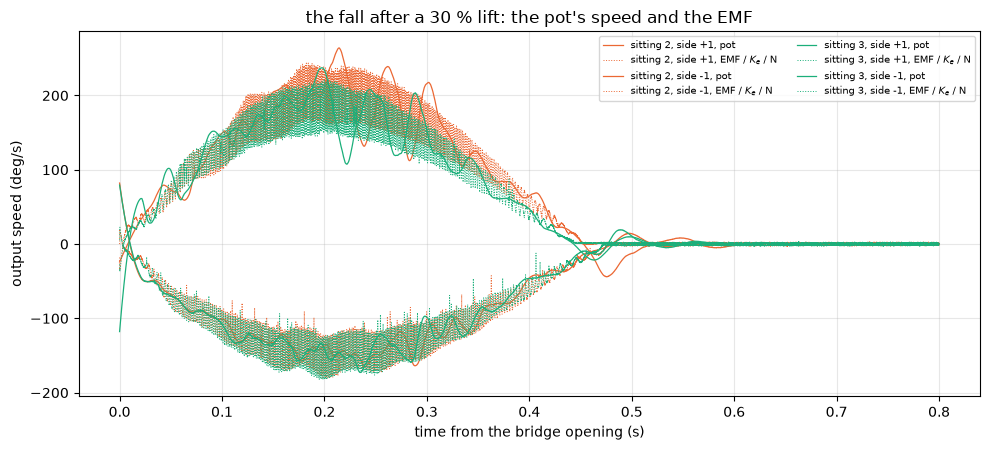

In [124]:
fig, ax = plt.subplots(figsize=(10, 4.6))
for _, r in FALLS3.iterrows():
    lift = LIFT3[(LIFT3["sitting"] == r["sitting"]) & (LIFT3["k"] == r["k"])]
    if r["sitting"] == 1 or lift["duty_pct"].iloc[0] != 30 or lift[
            "repeat"].iloc[0] != 0:
        continue
    tf, w, w_emf = r["trace"]
    m = tf < 0.8
    lab = f"sitting {r['sitting']}, side {r['side']:+d}"
    ax.plot(tf[m], w[m], lw=0.9, color=SIT_COLOR[r["sitting"]],
            label=lab + ", pot")
    ax.plot(tf[m], w_emf[m], lw=0.7, ls=":", color=SIT_COLOR[r["sitting"]],
            label=lab + ", EMF / $K_e$ / N")
figures.label(ax, x="time from the bridge opening (s)",
              y="output speed (deg/s)",
              title="the fall after a 30 % lift: the pot's speed and the EMF")
ax.legend(fontsize=7, ncol=2)
figures.finish(fig)

What you are looking at. The output speed through the fall after each first 30 % lift of sittings 2 and 3, from the pot (solid) and from the EMF through $K_e$ and N (dotted). The two lie on top of each other through the fall.

### 11.7 The static friction measured

The bottom blocks of sittings 2 and 3 lifted the arm at 20 % for 1 s and opened the bridge for a 3 s coast, so a drop now starts past the static band. Sitting 1's 12 % rests are read again from its hang for the events below.

In [125]:
RELEASE_WIN_S = 0.08    # s, the quadratic start of a fall, as section 3
rows, DROP3_TRACES = [], {}
for n in SITTINGS:
    for _, r in pd.read_csv(DATA / f"bottom-{n}" / "bottom.csv").iterrows():
        df, _ = load_sweep(DATA / f"bottom-{n}" / r["folder"])
        s1 = df[df["seg"] == 1]
        s2 = df[df["seg"] == 2].reset_index(drop=True)
        s2 = s2.iloc[np.flatnonzero(s2["duty_counts"] == 0)[0] + 2:]
        tf = np.arange(len(s2)) / FS
        th = np.asarray(theta_deg(s2["pos"], SITS.loc[n, "bottom"]))
        top = float(theta_deg(s1["pos"].iloc[-400:].median(),
                              SITS.loc[n, "bottom"]))
        end, end_pos = th[-10000:].mean(), s2["pos"].iloc[-10000:].median()
        moving = np.flatnonzero(np.abs(s2["pos"].to_numpy() - end_pos) > 3)
        q = np.polyfit(tf[tf < RELEASE_WIN_S],
                       np.radians(th[tf < RELEASE_WIN_S]), 2)
        tau_g0 = -SITS.loc[n, "tau_h"] * np.sin(np.radians(th[0]))
        j_alpha = SITS.loc[n, "j_out"] * 2 * q[0] * 1e3        # mN m
        same = np.sign(q[0]) == np.sign(tau_g0)
        cross = np.flatnonzero(np.sign(th[:-1]) != np.sign(th[1:]))
        rows.append({"sitting": n, "k": int(r["k"]), "side": int(r["side"]),
                     "top_deg": top, "end_deg": end,
                     "fell": abs(top - end) > 1.0, "crossed": len(cross) > 0,
                     "t_stop_s": (moving[-1] + 1) / FS if len(moving) else 0,
                     "release_mn_m": abs(tau_g0) - abs(j_alpha) if same
                     else np.nan})
        DROP3_TRACES[(n, int(r["k"]))] = (tf, th, int(r["side"]))
DROPS3 = pd.DataFrame(rows)
for col, th in (("tau_top", "top_deg"), ("tau_end", "end_deg")):
    DROPS3[col] = (DROPS3["sitting"].map(SITS["tau_h"])
                   * np.sin(np.radians(DROPS3[th].abs())))
show(DROPS3.round(2), n=None)

,sitting,k,side,top_deg,end_deg,fell,crossed,t_stop_s,release_mn_m,tau_top,tau_end
0,1,0,1,9.010,8.760,False,False,2.990,NaN,15.770,15.340
1,1,1,1,9.660,9.460,False,False,2.930,NaN,16.910,16.560
2,1,2,1,9.360,9.260,False,False,2.090,NaN,16.390,16.210
3,1,3,-1,-8.740,-8.630,False,False,0.030,NaN,15.320,15.120
4,1,4,-1,-10.280,-10.100,False,False,0.020,NaN,17.980,17.660
5,1,5,-1,-10.040,-9.730,False,False,2.990,NaN,17.560,17.020
6,2,0,1,32.910,8.600,True,False,0.660,32.870,36.880,10.160
7,2,1,1,31.810,8.880,True,False,0.520,29.920,35.790,10.480
8,2,2,1,32.050,8.870,True,False,0.630,34.310,36.030,10.470
9,2,3,-1,-33.810,-9.610,True,False,3.000,NaN,37.780,11.330


In [126]:
for n in (2, 3):
    d = DROPS3[DROPS3["sitting"] == n]
    f = d[d["fell"]]
    print(f"sitting {n}: top {d['top_deg'].abs().min():.1f} to "
          f"{d['top_deg'].abs().max():.1f} deg ({d['tau_top'].min():.1f} to "
          f"{d['tau_top'].max():.1f} mN m); fell {len(f)} of {len(d)}, "
          f"crossed the bottom {int(d['crossed'].sum())}; died at "
          f"{f['end_deg'].abs().min():.1f} to {f['end_deg'].abs().max():.1f}"
          f" deg ({f['tau_end'].min():.1f} to {f['tau_end'].max():.1f} mN m)"
          f" in {f['t_stop_s'].min():.2f} to {f['t_stop_s'].max():.2f} s")
f = DROPS3[(DROPS3["sitting"] >= 2) & DROPS3["fell"]]
stuck = DROPS3[(DROPS3["sitting"] >= 2) & ~DROPS3["fell"]]
print(f"quadratic-start release {f['release_mn_m'].mean():.1f} sd "
      f"{f['release_mn_m'].std():.1f} mN m (n {len(f)}); up "
      f"{f[f['side'] == 1]['release_mn_m'].mean():.1f}, down "
      f"{f[f['side'] == -1]['release_mn_m'].mean():.1f}")
print("did not fall: " + "; ".join(
    f"sitting {r.sitting} k{r.k} at {abs(r.top_deg):.1f} deg holding "
    f"{r.tau_top:.1f} mN m" for r in stuck.itertuples()))

sitting 2: top 31.8 to 34.0 deg (35.8 to 37.9 mN m); fell 6 of 6, crossed the bottom 0; died at 8.6 to 9.6 deg (10.2 to 11.3 mN m) in 0.45 to 3.00 s
sitting 3: top 27.7 to 33.3 deg (31.6 to 37.3 mN m); fell 5 of 6, crossed the bottom 0; died at 7.8 to 9.4 deg (9.2 to 11.1 mN m) in 0.40 to 2.83 s
quadratic-start release 32.7 sd 1.7 mN m (n 11); up 32.7, down 32.7
did not fall: sitting 3 k1 at 27.7 deg holding 31.6 mN m


The drops drop. The 20 % lift took the light arm to 31.8 to 34.0 degrees (35.8 to 37.9 mN m) and 11 of 12 fell, dying at 7.8 to 9.6 degrees without crossing the bottom. The twelfth, sitting 3's k1, stopped at 27.7 degrees on the way up and held 31.6 mN m through the whole coast with the bridge open. The quadratic-start release reads 32.7 sd 1.7 mN m on both sides, the same as section 3's 33.4 under heavier loads. That says the number belongs to the method, the lash unwinding inside its 80 ms, more than to the friction, and the events below supersede it.

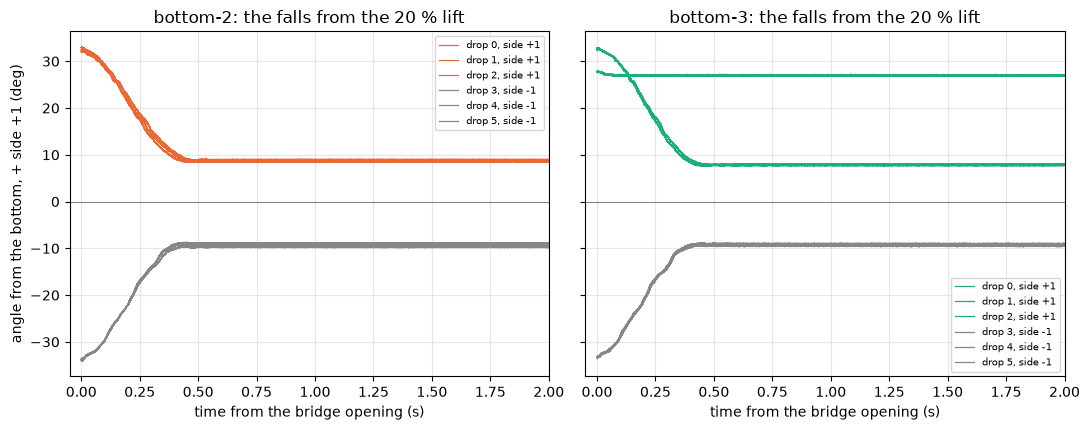

In [127]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, n in zip(axes, (2, 3)):
    for (nn, k), (tf, th, side) in DROP3_TRACES.items():
        if nn == n:
            ax.plot(tf, th, lw=0.9, color=SIT_COLOR[n] if side == 1
                    else MUTED, label=f"drop {k}, side {side:+d}")
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_xlim(-0.05, 2.0)
    figures.label(ax, x="time from the bridge opening (s)",
                  title=f"bottom-{n}: the falls from the 20 % lift")
    ax.legend(fontsize=7)
axes[0].set_ylabel("angle from the bottom, + side +1 (deg)")
figures.finish(fig)

What you are looking at. The angle after the bridge opens for each drop of sittings 2 and 3, side +1 in color and side -1 in gray. Five of six fall in sitting 3, the sixth stays at 27.7 degrees.

In [128]:
# the current under the window floor, from the hot as-read stall line of
# sittings 2 and 3 (section 11.8) less the crest term at low duty
MA_PER_PCT = 10.42      # mA per % of duty, the analysis note's value
G_TERM_MA = 17          # mA, the crest term g (1 - D) V_on at low duty


def event(source, n, side, theta, load, motor, kind):
    """One held or released event: the friction bound is the load less
    the motor's torque at that moment."""
    return {"source": source, "sitting": n, "side": side, "theta": theta,
            "load_mn_m": load, "motor_mn_m": motor, "kind": kind,
            "bound_mn_m": load - motor}

In [129]:
ev = []
for r in EDGES[(EDGES["edge"] == "step") & (EDGES["step_pct"] < 0)
               ].itertuples():
    measured = r.i_window_ok and np.isfinite(r.di_end_ma)
    amps = ((r.i_before_ma + r.di_end_ma) if measured else max(
        r.duty_to * MA_PER_PCT - G_TERM_MA, 0)) / 1e3
    motor, tau_h = KT_SIDE[r.side] * amps, SITS.loc[r.sitting, "tau_h"]
    g0, g1 = (tau_h * np.sin(np.radians(abs(t)))
              for t in (r.theta_before, r.theta_after))
    name = f"step s{r.sitting} k{r.k} {r.side * r.base_pct:+d}{r.step_pct:+d}"
    if r.moved:
        ev.append(event(name, r.sitting, r.side, abs(r.theta_before), g0,
                        motor, "released"))
        ev.append(event(name + " re-stuck", r.sitting, r.side,
                        abs(r.theta_after), g1, motor, "held after a fall"))
    else:
        ev.append(event(name, r.sitting, r.side, abs(r.theta_before), g0,
                        motor, "held"))
for r in ABOVE3[~ABOVE3["at_stop"]].itertuples():
    ev.append(event(f"above s{r.sitting} k{r.k}", r.sitting, r.side,
                    abs(r.theta_end), r.gravity_mn_m, r.motor_mn_m, "held"))
for r in DROPS3.itertuples():
    open_ = "released, bridge open" if r.fell and r.sitting >= 2 else \
        "held, bridge open"
    ev.append(event(f"drop s{r.sitting} k{r.k}", r.sitting, r.side,
                    abs(r.top_deg), r.tau_top, 0.0, open_))
    if r.fell and r.sitting >= 2:
        ev.append(event(f"drop s{r.sitting} k{r.k} died", r.sitting, r.side,
                        abs(r.end_deg), r.tau_end, 0.0, "held after a swing"))
for r in FALLS3.itertuples():
    ev.append(event(f"lift fall s{r.sitting} k{r.k}", r.sitting, r.side,
                    abs(r.theta0), SITS.loc[r.sitting, "tau_h"] * np.sin(
                        np.radians(abs(r.theta0))), 0.0,
                    "released, bridge open"))
EVENTS3 = pd.DataFrame(ev).sort_values(["kind", "load_mn_m"])
EVENTS3["at_motor_un_m"] = EVENTS3["bound_mn_m"] / GEAR * 1e3
show(EVENTS3[~EVENTS3["kind"].str.contains("open")].round(1), n=None)

,source,sitting,side,theta,load_mn_m,motor_mn_m,kind,bound_mn_m,at_motor_un_m
9,step s3 k3 +16-15,3,1,20.700,24.000,0.000,held,24.000,77.900
1,step s2 k3 +16-15,2,1,20.800,24.100,0.000,held,24.100,78.200
8,step s3 k1 +16-10,3,1,22.200,25.600,13.900,held,11.700,38.100
0,step s2 k1 +16-10,2,1,22.300,25.700,14.100,held,11.600,37.600
5,step s2 k12 -16-10,2,-1,23.300,26.800,22.400,held,4.400,14.300
14,step s3 k15 -16-10,3,-1,23.300,26.800,18.700,held,8.200,26.500
17,step s3 k21 -26-10,3,-1,43.600,46.800,45.000,held,1.900,6.000
19,step s3 k25 -26-20,3,-1,45.700,48.600,18.200,held,30.400,98.700
18,step s3 k23 -26-15,3,-1,46.300,49.100,31.700,held,17.300,56.300
2,step s2 k6 +30-10,2,1,50.100,52.100,43.100,held,9.000,29.200


In [130]:
held = EVENTS3[EVENTS3["kind"].str.startswith("held")
               & ~EVENTS3["kind"].str.contains("swing")]
rel = EVENTS3[EVENTS3["kind"].str.startswith("released")]
for lo, hi in ((0, 20), (20, 30), (30, 40), (40, 50), (50, 60), (60, 70)):
    h = held[held["load_mn_m"].between(lo, hi, inclusive="left")]
    r = rel[rel["load_mn_m"].between(lo, hi, inclusive="left")]
    print(f"load {lo:2d} to {hi:2d} mN m: held >= "
          f"{h['bound_mn_m'].max():5.1f} (n {len(h)}), released at <= "
          f"{r['bound_mn_m'].min():5.1f} (n {len(r)})")
# the band the held and released events with the motor near zero bracket,
# read off the table and the bands above
T_S_BAND = (25, 36)     # mN m at the output
lo, hi = (t / GEAR * 1e3 for t in T_S_BAND)
print(f"static friction {T_S_BAND[0]} to {T_S_BAND[1]} mN m = {lo:.0f} to "
      f"{hi:.0f} uN m at the motor")

load  0 to 20 mN m: held >=  18.0 (n 6), released at <=   nan (n 0)
load 20 to 30 mN m: held >=  24.1 (n 8), released at <=  26.7 (n 2)
load 30 to 40 mN m: held >=  35.4 (n 2), released at <=  30.9 (n 23)
load 40 to 50 mN m: held >=  30.4 (n 3), released at <=  49.2 (n 1)
load 50 to 60 mN m: held >=  49.4 (n 7), released at <=  50.4 (n 10)
load 60 to 70 mN m: held >=  31.3 (n 5), released at <=  60.0 (n 10)
static friction 25 to 36 mN m = 81 to 117 uN m at the motor


Every held or released event gives a bound, gravity's torque less the motor's at that moment. With the motor near zero the train held 24.0 and 24.1 mN m at 21 degrees (the -15 % steps on the up side, both sittings), 31.6 at 28 degrees (the stuck drop) and 35.4 at 31 degrees (re-stuck after the -25 % fall), and released at 26.7 and 26.9 (the -15 % steps on the down side, a 2.9 degree slip onto 23.5 in both sittings), at 35.8 to 37.9 in the drops, from 30.9 up in the lifts' falls, and at 49.2 at 46 degrees. The static holding friction of the back-driven train is 25 to 36 mN m with an event-to-event scatter of about 6, 81 to 117 uN m at the motor. The friction notebook sets it against the running Coulomb term. Section 3's held bound of 16.6 is superseded, and its release of 33.4 is confirmed by a route without the lash. Under drive the bounds agree, -20 % steps held 34.3 at 56 degrees with the motor at 22, and the one -25 % step to 5 % held 49.4 with the motor estimated at 7 from the hot line, its window under the current floor. Between 24 and 36 mN m of load the friction sits at the load from both sides, and at 46 to 56 it is at least 34 by two measured events and at most 49 by one. Whether the band grows with load is not established.

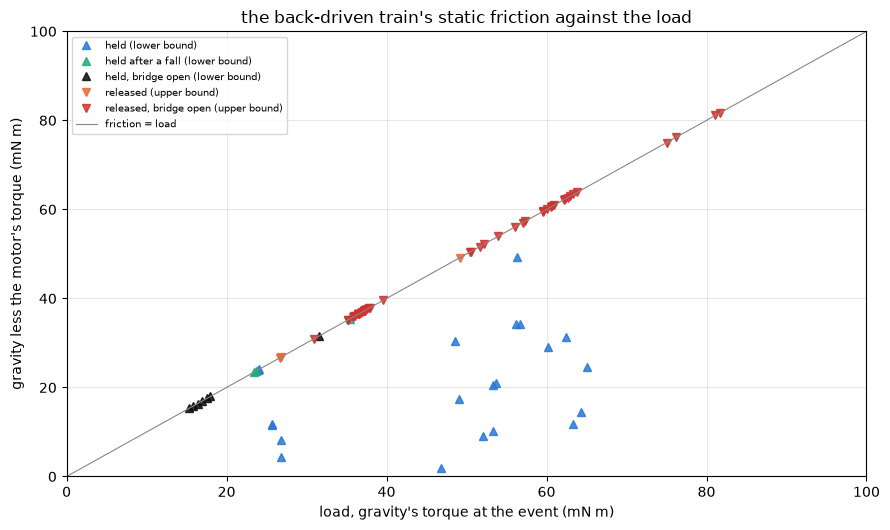

In [131]:
KIND_STYLE = {"held": ("^", BLUE), "held after a fall": ("^", GREEN),
              "held, bridge open": ("^", INK),
              "released": ("v", ORANGE),
              "released, bridge open": ("v", RED)}
fig, ax = plt.subplots(figsize=(9, 5.4))
for kind, (mk, color) in KIND_STYLE.items():
    d = EVENTS3[EVENTS3["kind"] == kind]
    ax.plot(d["load_mn_m"], d["bound_mn_m"], mk, color=color, alpha=0.85,
            label=kind + (" (lower bound)" if kind.startswith("held")
                          else " (upper bound)"))
ax.plot([0, 100], [0, 100], "-", color=MUTED, lw=0.8,
        label="friction = load")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
figures.label(ax, x="load, gravity's torque at the event (mN m)",
              y="gravity less the motor's torque (mN m)",
              title="the back-driven train's static friction against the "
              "load")
ax.legend(fontsize=7.5, loc="upper left")
figures.finish(fig)

What you are looking at. Every event's friction bound against its load. Up triangles are lower bounds, the train held, and down triangles upper bounds, it released. The gray line is friction equal to the load.

### 11.8 The stall line and the NTC across sittings

The stall lines take every settled rung of 6 % or more with a valid window, sitting 2's stop rungs included, as section 8 does.

In [132]:
STALL3 = LAD[LAD["stalled"] & LAD["i_valid"] & (LAD["duty_pct"] >= 6)].copy()
STALL3["v_a_v"] = STALL3["D"] * STALL3["v_on_v"]     # V, as read
STALL_LINES = {}
for key, sel in (("s1", STALL3["sitting"] == 1), ("s2", STALL3["sitting"]
                 == 2), ("s3", STALL3["sitting"] == 3),
                 ("s2+3", STALL3["sitting"] >= 2),
                 ("s1 <= 34 %", (STALL3["sitting"] == 1)
                  & (STALL3["duty_pct"] <= 34))):
    d = STALL3[sel]
    fa = results.fit_line(d["v_a_v"], d["i_crest_a"])   # as read
    fc = results.fit_line(d["i_w_a"], d["v_c_v"])       # construction C
    STALL_LINES[key] = (fa, fc, d)
    worst = int(np.argmax(np.abs(fc["resid"])))
    v_on = d["v_on_v"].mean()
    print(f"{key:10s}: {fa['slope'] * v_on / 100 * 1e3:.2f} mA per % at "
          f"V_on {v_on:.2f}, {fa['intercept'] * 1e3:+.1f} mA at zero; cold "
          f"over hot {(1 - fa['slope'] * R_STOP_A) * 100:.1f} %; C: R "
          f"{fc['slope']:.3f} +/- {fc['slope_se']:.3f} ohm, V0 "
          f"{fc['intercept'] * 1e3:+.0f} mV, rms {fc['rms'] * 1e3:.0f} mV, "
          f"largest k{int(d['k'].iloc[worst])} "
          f"{fc['resid'][worst] * 1e3:+.0f} mV; {d['duty_pct'].min():.0f} to"
          f" {d['duty_pct'].max():.0f} %")

s1        : 10.00 mA per % at V_on 4.79, +15.3 mA at zero; cold over hot 8.6 %; C: R 4.538 +/- 0.032 ohm, V0 -82 mV, rms 26 mV, largest k19 +79 mV; 6 to 54 %
s2        : 10.43 mA per % at V_on 4.83, +8.6 mA at zero; cold over hot 5.5 %; C: R 4.335 +/- 0.023 ohm, V0 -44 mV, rms 10 mV, largest k34 +30 mV; 6 to 34 %
s3        : 10.41 mA per % at V_on 4.84, +10.4 mA at zero; cold over hot 5.9 %; C: R 4.320 +/- 0.073 ohm, V0 -46 mV, rms 31 mV, largest k31 -162 mV; 6 to 34 %
s2+3      : 10.42 mA per % at V_on 4.84, +9.5 mA at zero; cold over hot 5.7 %; C: R 4.329 +/- 0.037 ohm, V0 -45 mV, rms 23 mV, largest k31 -164 mV; 6 to 34 %
s1 <= 34 %: 10.44 mA per % at V_on 4.82, +8.7 mA at zero; cold over hot 5.3 %; C: R 4.333 +/- 0.025 ohm, V0 -45 mV, rms 12 mV, largest k43 +41 mV; 6 to 34 %


In [133]:
m = RUNIN = STALL3[STALL3["approach"] == "below"].pivot_table(
    index=["side", "duty_pct"], columns="sitting", values="i_w_a").dropna()
for a, b in ((2, 1), (3, 1), (3, 2)):
    ratio = m[a] / m[b]
    print(f"end-of-hold current, sitting {a} over {b}: {ratio.mean():.3f} sd "
          f"{ratio.std():.3f} (n {len(ratio)})")

end-of-hold current, sitting 2 over 1: 0.999 sd 0.011 (n 26)
end-of-hold current, sitting 3 over 1: 0.996 sd 0.011 (n 26)
end-of-hold current, sitting 3 over 2: 0.997 sd 0.008 (n 26)


As read, the hot line is 10.43 and 10.41 mA per % at a $V_{on}$ of 4.83 and 4.84 V in sittings 2 and 3, and sitting 1 over the same 6 to 34 % gives 10.44. Sitting 1's 10.00 comes from its rungs up to 54 %, where the warming bow is largest, so the three sittings agree over the span they share. The cold line sits 5.5 and 5.9 % over the hot one there, against 8.6 % over sitting 1's full span. Construction C gives 4.335 +/- 0.023 and 4.320 +/- 0.073 ohm with $V_0$ -44 and -46 mV, against the resistance result's cold 4.177. Sitting 3's rms of 31 mV comes from k31, 162 mV under the line, the from-above rung whose current ran high for 3 s with the pot still. The end-of-hold current at matched duty agrees between the sittings to 0.999, 0.996 and 0.997, so no run-in shows over three sittings.

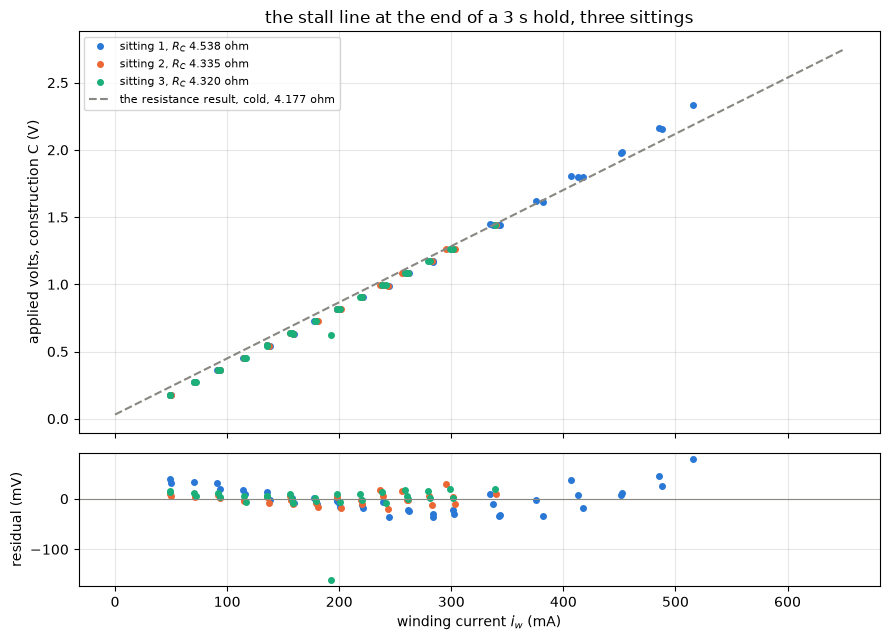

In [134]:
fig, (ax, ax_res) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True,
                                 gridspec_kw={"height_ratios": [3, 1]})
for key in ("s1", "s2", "s3"):
    fa, fc, d = STALL_LINES[key]
    n = int(key[1])
    ax.plot(d["i_w_a"] * 1e3, d["v_c_v"], "o", color=SIT_COLOR[n], ms=4,
            label=f"sitting {n}, $R_C$ {fc['slope']:.3f} ohm")
    ax_res.plot(d["i_w_a"] * 1e3, fc["resid"] * 1e3, "o", color=SIT_COLOR[n],
                ms=4)
amps = np.linspace(0, 0.65, 5)
ax.plot(amps * 1e3, V0_C + R_C * amps, "--", color=MUTED,
        label=f"the resistance result, cold, {R_C:.3f} ohm")
ax_res.axhline(0, color=MUTED, lw=0.8)
figures.label(ax, y="applied volts, construction C (V)",
              title="the stall line at the end of a 3 s hold, three sittings")
figures.label(ax_res, x="winding current $i_w$ (mA)", y="residual (mV)")
ax.legend(fontsize=8)
figures.finish(fig)

What you are looking at. The applied volts under construction C against the winding current at each settled rung, with the residual below. The dashed line is the resistance result's cold line.

In [135]:
for n in SITTINGS:
    p = LOGS[n][1]
    print(f"sitting {n}: NTC {p['ntc_c'].iloc[0]:.1f} to "
          f"{p['ntc_c'].iloc[-1]:.1f} C over "
          f"{(p['t_host'].max() - p['t_host'].min()) / 60:.0f} min; rail "
          f"probe {p['rail_v'].mean():.3f} sd {p['rail_v'].std():.3f} V")
gap = LOGS[3][1]["t_host"].min() - LOGS[2][1]["t_host"].max()
print(f"sitting 3 began {gap / 60:.0f} min after sitting 2's last probe")

sitting 1: NTC 26.3 to 27.1 C over 63 min; rail probe 4.987 sd 0.008 V
sitting 2: NTC 26.8 to 27.7 C over 56 min; rail probe 4.987 sd 0.007 V
sitting 3: NTC 27.0 to 28.3 C over 66 min; rail probe 4.989 sd 0.008 V
sitting 3 began 2 min after sitting 2's last probe


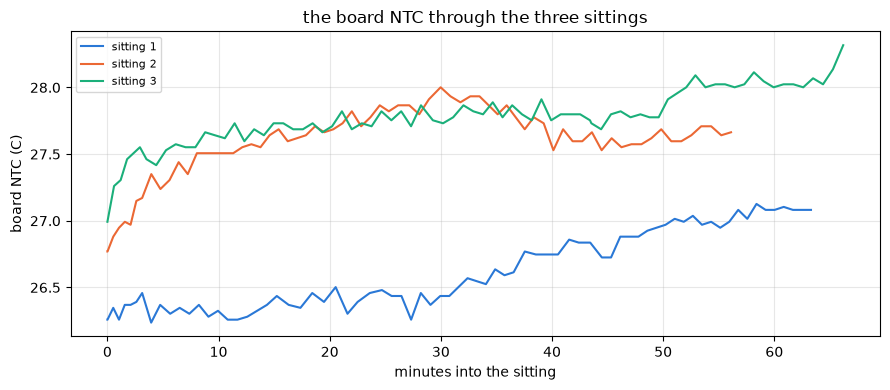

In [136]:
fig, ax = plt.subplots(figsize=(9, 4))
for n in SITTINGS:
    p = LOGS[n][1]
    ax.plot((p["t_host"] - p["t_host"].min()) / 60, p["ntc_c"], "-",
            color=SIT_COLOR[n], label=f"sitting {n}")
figures.label(ax, x="minutes into the sitting", y="board NTC (C)",
              title="the board NTC through the three sittings")
ax.legend(fontsize=8)
figures.finish(fig)

The board NTC went from 26.3 to 27.1, 26.8 to 27.7 and 27.0 to 28.3 C through the three sittings, and sitting 3 began 2 min after sitting 2's last probe. What you are looking at. The NTC at every probe against the minutes into each sitting.

### 11.9 Capture notes

The manifests, the index files and the sweep folders, read together.

In [137]:
for n in (2, 3):
    metas = {p.parent.relative_to(DATA).as_posix(): json.loads(p.read_text())
             for p in sorted(DATA.glob(f"*-{n}/**/meta.json"))}
    done = [m for m in metas.values() if "rows_dropped" in m]
    probes = LOGS[n][1]["folder"]
    unlisted = []
    for blk, csv in (("bottom", "bottom.csv"), ("ladder", "ladder.csv"),
                     ("lift", "cycles.csv"), ("steps", "chains.csv")):
        listed = set(pd.read_csv(DATA / f"{blk}-{n}" / csv)["folder"])
        unlisted += [f for f in metas if f.startswith(f"{blk}-{n}/")
                     and f.split("/", 1)[1] not in listed]
    print(f"sitting {n}: {len(metas)} sweeps, {len(done)} complete, rows "
          f"dropped {sum(m['rows_dropped'] for m in done)}, current limit "
          f"{sorted({m['drive']['current_limit_counts'] for m in done})} "
          f"counts; not in an index {unlisted or 'none'}; probed twice "
          f"{sorted(set(probes[probes.duplicated()])) or 'none'}")
    seek = theta_deg(LAD[LAD["sitting"] == n]["first_pos"],
                     SITS.loc[n, "bottom"])
    print(f"   the seek left the arm at {seek.min():+.1f} to {seek.max():+.1f}"
          f" deg before the ladder's rungs")
stop = STOP_STEPS = EDGES[(EDGES["edge"] == "step")
                          & (EDGES["theta_after"].abs() > 80)]
print("steps onto a stop: " + "; ".join(
    f"s{r.sitting} k{r.k} {r.side * r.base_pct:+d}{r.step_pct:+d} to "
    f"{abs(r.theta_after):.0f} deg at {(r.i_before_ma + r.di_end_ma):.0f} mA"
    for r in stop.itertuples()) + f"; held-stall cap {SERVO.stop_hold_a} A")
low = EDGES[(EDGES["edge"] == "step") & ~EDGES["i_window_ok"]]
print(f"steps whose target window sits under the current floor of "
      f"{BOARD.i_window_min_ticks} ticks: "
      f"{sorted(int(x) for x in low['duty_to'].unique())} % of duty")

sitting 2: 69 sweeps, 68 complete, rows dropped 0, current limit [942] counts; not in an index ['steps-2/chains/15']; probed twice none
   the seek left the arm at -15.7 to +12.9 deg before the ladder's rungs
sitting 3: 78 sweeps, 78 complete, rows dropped 0, current limit [942] counts; not in an index none; probed twice ['steps-3/chains/1']
   the seek left the arm at -14.6 to +16.0 deg before the ladder's rungs
steps onto a stop: s2 k9 +30+20 to 82 deg at 516 mA; s3 k8 +30+15 to 82 deg at 467 mA; s3 k10 +30+20 to 82 deg at 511 mA; s3 k12 +30+25 to 83 deg at 560 mA; s3 k22 -26+15 to 83 deg at 322 mA; s3 k24 -26+20 to 92 deg at 366 mA; s3 k26 -26+25 to 96 deg at 526 mA; held-stall cap 0.5 A
steps whose target window sits under the current floor of 64 ticks: [1, 5] % of duty


- Rows dropped 0 in every complete sweep, and the current limit stayed at 942 counts.
- Sitting 2 ended at `steps-2/chains/15`, the +20 % step at the 16 % down rung. Its seek failed and the folder holds a baseline and a `meta.json` without `rows_dropped`, no row in `chains.csv`. Sitting 3's retry of `chains/1`, probed twice, completed on the second try.
- Seven steps ran the arm over the top onto a stop at 82 to 96 degrees and 322 to 560 mA for 0.5 s, four of them over the 0.5 A held-stall cap. The step back did not bring the arm back, since past 90 degrees gravity pushes it into the stop, and the next seek did. The steps' plan checks the duty only and needs the ladder's rest prediction and a refusal past 75 degrees, as the from-above rungs have.
- Sitting 2's ladder pressed the stops on four from-above rungs, its 16 % overshoot carrying the arm over the top.
- The seek leaves the arm anywhere from -15.7 to +16.0 degrees, so the 8 to 12 % rungs depend on the side the arm sat.
- The steps to 1 and 5 % sit under the current floor of 64 ticks and have no measured current. The 4 % rungs have no current and the 6 % rungs no tap, so $V_{on}$ comes from each side's line there.
- Sitting 2 worked from the count midpoint 2004 for its guards and nominal degrees. This section uses the hand hang for both inner-pair sittings.

## 12. What stages 4 to 7 read from here

The numbers below hold over the three sittings, two masses on one train. Each is printed in the section named beside it.

| quantity | value | bracket | section |
|:-|:-|:-|:-|
| Kt through the gears, both directions, at a rising stall | 225.7 mN m/A, 0.632 of $K_e N$ | 221.3 to 242.0 (0.620 to 0.678), the full range to the range below 41.5 degrees | 11.2, 11.3 |
| Kt through the gears by direction | one value for both | the down side 4.5 to 19.8 % over the up side below 41.5 degrees, not established | 11.3 |
| the dip at 42 to 49 degrees from the bottom | -6.3 mN m up, -3.3 to -3.6 down | cause open | 11.3 |
| static holding friction, back-driven, motor near zero | 25 to 36 mN m at the output | 81 to 117 uN m at the motor | 11.7 |
| the hold's deadband, a ratchet | up 5 to 10 % of duty | down 20 to 25 % | 11.4 |
| the friction band under load, rise plus release | 23.1 to 51.1 mN m at 23 degrees, 53.2 to 75.8 at 45.5 | 75 to 246 uN m at the motor | 11.4 |
| the step response when the arm moves | delay 25 ms, 10 to 90 % in 338 ms (median) | overshoot 3.5 %, 4 of 22 settled within 500 ms | 11.4 |
| the current per % of duty at a step | 10.03 mA | sd 1.36, settled 8.06 with the arm moving | 11.4 |
| the hot stall line after a 3 s hold at 5 V | 10.42 mA per % over 6 to 34 %, 10.00 over 6 to 54 % (sitting 1) | the cold line 5.5 to 5.9 % over it on 6 to 34 %, 8.6 % on 6 to 54 % | 8, 11.8 |
| the arm's own term | 17.04 mN m, weighed | the data's joint fit 18.2 +/- 2.7 | 1, 11.2 |

- A stage 5 gravity feed-forward built on one Kt through the gears for both directions is off by at most about 6 mN m at 42 to 49 degrees, inside the static friction band.
- A duty hold follows a rise of 10 % within half a second and holds through a cut of 20 %, so the position after a step depends on the direction it came from by the whole band.
- The fall back-drives the motor with no slip, so the EMF reads the output speed through $K_e$ and N whenever the arm falls.
- A stall fault set from the cold line sits above a warm hold's current.

### Open discrepancies

1. The rests dip at 42 to 49 degrees from the bottom on both sides, at all three sittings and both masses, -6.3 mN m on the up side and -3.3 to -3.6 on the down. Something that rides with the arm's angle (the coins, which slide and rattle in their cups, or the arm on the horn) and two tight places in the train both fit. The design clearance bounds a coin shift at 0.61 mN m, a tenth of the dip. Pack the coins so they stay put and repeat one ladder, and re-seat the arm 2 or 3 spline teeth and repeat one ladder. The dip goes away with the coins packed or moves with the arm if it rides with the arm, and stays at the counts if the train holds it.
2. Under the dip sits a constant offset, the up side losing 1.2 to 3.7 mN m more in motion and the down side holding 3.14 more at rest in sitting 1. The same two ladders separate a train effect, which stays with the direction, from a rig effect, which moves with the arm.
3. Whether the static friction grows with the load. One estimated event, 49.4 at 56 mN m, against bounds of 34.3 and 49.2. Steps of 20, 22, 25 and 30 % at three angles a side, twice each, from base duties of 30 % or more so the target windows stay above the current floor, measure it.
4. The EMF turns a few percent more per pot degree on the up side, 1.068 and 1.079 against 1.044 and 1.016, with $K_e$ symmetric by direction. The pot's scale by side and the lash's take-up by direction both fit. A fall through the same count span both ways, the arm re-seated so the falls cover the same counts, separates them.
5. Sitting 3's from-above rung k31 sat 162 mV under the stall line for 3 s with the pot still. A brush bridging two segments fits. Ten repeated 3 s holds at 16 % from above count how often a rung sits that far off the line.
6. The stall currents of sitting 1 sit under the cold line with a bow a warming term fits, and a mis-scaled crest term $g$ at low duty fits too. A locked hold of 3 s at 25 and 45 % streamed whole gives the current's decay with time, and the DC ammeter at 6 to 12 % duty extends the $g$ band below 16 %.
7. The pot's rest noise is 1.28 counts on the up side and 0.74 on the down in sitting 1. A rest series at matched angles both ways in one block tells a side effect from the time between the two halves of a ladder.

### A sitting 4

The plan on disk wants these changes before a fourth sitting.

- The steps need the ladder's rest prediction and a refusal past 75 degrees, as the from-above rungs have, so no step runs the arm onto a stop.
- The step sizes bracket what section 11.4 measured, 5, 8, 10 and 12 % up and 20, 22, 25 and 30 % down, each repeated twice, since one try per size does not resolve an event scatter of about 6 mN m.
- A from-above rung overshoots by 20 to 25 % so the arm falls after the step down, or the approach is dropped as a method.
- One more ladder of the inner pair adds little as it is. The two discriminators of the dip do. One ladder runs with the coins packed so they stay put, and one with the arm re-seated 2 or 3 spline teeth, each with 1 % steps over the duties that bracket 42 to 49 degrees.
- The 20 % drops are the right static friction measurement and can run 6 a side.

### The result file

Every quantity with its bounds and unit, the torques absolute with the factor recorded beside them. Sitting 1's keys keep their values. Section 11's keys are new, and the notes say which earlier key each supersedes.

In [138]:
q, pm = results.quantity, results.pm


def by_side(f):
    """{"+1": f(+1), "-1": f(-1)}"""
    return {"+1": f(1), "-1": f(-1)}


def kt_q(key):
    v, lo, hi = KT_GEAR[key]
    return q(v, lo, hi, "mN m/A")

In [139]:
QUANTITIES = {
    "coins_mass_g": q(COINS_G, COINS_G * (1 - COIN_TOL),
                      COINS_G * (1 + COIN_TOL), "g"),
    "coins_radius_mm": q(COINS_R_MM, unit="mm"),
    "coin_block_g": q(BLOCK_G, unit="g"),
    "coin_block_radius_mm": q(BLOCK_R_MM, unit="mm"),
    "arm_mount_g": q(MOUNT_G, unit="g"),
    "arm_mount_radius_mm": q(MOUNT_R_MM, unit="mm"),
    "tau_coins_horizontal_mn_m": q(TAU_COINS, unit="mN m"),
    "tau_arm_horizontal_mn_m": q(TAU_ARM, TAU_ARM - SPLIT, TAU_ARM + SPLIT,
                                 "mN m"),
    "tau_horizontal_mn_m": q(TAU_H, TAU_H * SCALE_LO / SCALE,
                             TAU_H * SCALE_HI / SCALE, "mN m"),
    "gravity_torque_scale": q(SCALE, SCALE_LO, SCALE_HI, "ratio"),
    "bottom_counts": q(BOTTOM, BOTTOM_LO, BOTTOM_HI, "counts"),
    "bottom_plan_counts": q(PLAN_BOTTOM, unit="counts"),
    "bottom_hand_counts": q(HAND, unit="counts"),
    "hold_rest_12pct_deg": {
        "+1": results.mean_sd(TH_UP, "deg"),
        "-1": results.mean_sd(TH_DN, "deg")},
    "static_friction_held_lower_mn_m": q(HELD_LO, unit="mN m"),
    "static_friction_release_mn_m": results.mean_sd(
        RELEASE["release_mn_m"], "mN m"),
    "static_hold_band_deg": q(np.r_[TH_UP, TH_DN].mean(), unit="deg"),
    "swing_rest_deg_range": q(SWING.median(), SWING.min(), SWING.max(),
                                  "deg"),
    "kt_gear_mn_m_per_a": {
        "+1": kt_q(1), "-1": kt_q(-1), "pooled": kt_q("pooled"),
        "+1 table-only": results.line_q(TABLE_ONLY[1], "slope", "mN m/A"),
        "-1 table-only": results.line_q(TABLE_ONLY[-1], "slope",
                                        "mN m/A")},
}
print(len(QUANTITIES), "keys")

19 keys


In [140]:
QUANTITIES.update({
    "kt_gear_over_ke_n": {k: q(v / KT_IDEAL, lo / KT_IDEAL, hi / KT_IDEAL,
                               "ratio")
                          for k, (v, lo, hi) in (("+1", KT_GEAR[1]),
                                                 ("-1", KT_GEAR[-1]),
                                                 ("pooled",
                                                  KT_GEAR["pooled"]))},
    "train_efficiency_stall": q(
        KT_GEAR["pooled"][0] / KT_IDEAL, KT_GEAR[1][0] / KT_IDEAL,
        KT_GEAR[-1][0] / KT_IDEAL, "ratio"),
    "torque_line_intercept_mn_m": by_side(
        lambda s: q(*INTERCEPT[s], "mN m")),
    "torque_line_rms_mn_m": by_side(lambda s: q(FITS[s]["rms"],
                                                unit="mN m")),
    "torque_line_flat_band_pct": by_side(lambda s: q(
        BELOW[BELOW["side"] == s]["duty_pct"].mean(),
        BELOW[BELOW["side"] == s]["duty_pct"].min(),
        BELOW[BELOW["side"] == s]["duty_pct"].max(), "%")),
    "torque_curve_rungs_used": q(len(USE), unit="rungs"),
    "kt_gear_bottom_spread_pct": {
        line: q(np.ptp(g["slope"]) / g.set_index("bottom").loc[
            BOTTOM, "slope"] * 100, unit="%")
        for line, g in SENS.groupby("line", sort=False)},
    "friction_band_lower_mn_m": q(BAND_LO[0], BAND_LO[0], BAND_LO[1],
                                  "mN m"),
    "hold_deadband_duty_pct": q(STEP_PCT, unit="% (lower bound)"),
    "hold_deadband_ma": q(UP["di_jump_ma"].abs().mean(),
                          UP["di_jump_ma"].abs().min(),
                          UP["di_jump_ma"].abs().max(), "mA (lower bound)"),
    "above_rungs_moved": bool(ABOVE["moved"].any()),
    "side_current_ratio_matched_duty": results.mean_sd(
        SIDES["i_dn_over_up"], "ratio"),
    "side_torque_per_amp_ratio": q(SIDE_TPA[BOTTOM],
                                   min(SIDE_TPA.values()),
                                   max(SIDE_TPA.values()), "ratio"),
    "side_kt_gear_split_sigma": {"table-only": q(SPLIT_TABLE, unit="sigma"),
                                 "all": q(SPLIT_ALL, unit="sigma")},
})
print(len(QUANTITIES), "keys")

33 keys


In [141]:
QUANTITIES.update({
    "stall_line_as_read_ma_per_v": results.line_q(FA, "slope", "mA/V",
                                                  1e3),
    "stall_line_as_read_intercept_ma": results.line_q(FA, "intercept",
                                                      "mA", 1e3),
    "stall_ma_per_pct_5v_hot": q(FA["slope"] * V_ON / 100 * 1e3,
                                 unit="mA per %"),
    "stall_cold_line_over_hot_pct": q((1 - FA["slope"] * R_STOP_A) * 100,
                                      unit="%"),
    "r_app_as_read_hot_ohm": q(1 / FA["slope"], unit="ohm"),
    "r_c_hot_ohm": results.line_q(FC, "slope", "ohm"),
    "v0_c_hot_mv": results.line_q(FC, "intercept", "mV", 1e3),
    "r0_cubic_ohm": pm(R0_3, CUBIC_SE[1], "ohm"),
    "v0_cubic_mv": pm(V0_3, CUBIC_SE[0], "mV", 1e3),
    "warming_ohm_per_a2": pm(C_3, CUBIC_SE[2], "ohm/A^2"),
    "stall_line_resid_band_mv": q(0, -RESID_BAND, RESID_BAND, "mV"),
    "stall_rungs_used": q(len(ST), unit="rungs"),
    "hold_warming_pct_at_0p5a_3s": q(WARM_CUBIC * 100, meter_scaled * 100,
                                     WARM_CUBIC * 100, "% (low)"),
    "ntc_c_open": q(NTC_OPEN, unit="C"),
    "ntc_c_close": q(NTC_CLOSE, unit="C"),
    "ntc_rise_c": q(NTC_CLOSE - NTC_OPEN, unit="C"),
    "lift_speed_at_10deg_rev_s": {
        f"{int(r['side'] * r['duty_pct']):+d} % rep {int(r['repeat'])}":
        q(r["w_10"], unit="rev/s") for _, r in LIFT.iterrows()},
    "lift_speed_free_rev_s": {
        f"{d * p:+d} %": q(FREE[(p, d)][0], unit="rev/s")
        for p, d in FREE if p in (20, 30, 40)},
    "lift_speed_loss_rev_s": {
        f"{int(r['side'] * r['duty_pct']):+d} % at {int(r['deg'])} deg "
        f"k{int(r['k'])}": q(r["lost"], unit="rev/s")
        for _, r in LOSS.iterrows()},
    "lift_loss_share_r_di_ke": by_side(lambda s: q(
        SHARE[s].median(), SHARE[s].min(), SHARE[s].max(), "ratio")),
    "lift_current_at_30deg_over_static": q(LIFT_RATIO.mean(),
        LIFT_RATIO.min(), LIFT_RATIO.max(), "ratio"),
})
print(len(QUANTITIES), "keys")

54 keys


In [142]:
QUANTITIES.update({
    "fall_emf_over_pot_speed": results.mean_sd(EMF_R, "ratio"),
    "fall_friction_at_peak_mn_m": {
        f"{int(r['side'] * r['duty_pct']):+d} % rep {int(r['repeat'])}":
        q(r["peak_mn_m"], unit=f"mN m at {abs(r['w_peak']):.0f} deg/s")
        for _, r in FALL.iterrows()},
    "fall_coulomb_mn_m": results.mean_sd(COULOMB, "mN m"),
    "fall_viscous_mn_m_s_per_rad": results.mean_sd(VISCOUS,
                                                   "mN m s/rad"),
    "fall_recoil_deg": results.mean_sd(RECOIL, "deg"),
    "fall_end_theta_deg": results.median_range(FALL["end_deg"].abs(),
                                               "deg"),
    "fall_time_s": results.median_range(FALL["stop_s"], "s"),
    "lift_repeat_range": {
        col: results.median_range(REPEAT[col], u) for col, u in
        (("w10", "rev/s"), ("top", "deg"), ("end", "deg"))},
    "steps_k_i_jump_ma_per_pct": results.mean_sd(UP["k_jump"], "mA/%"),
    "steps_k_i_settled_ma_per_pct": results.mean_sd(UP["k_end"], "mA/%"),
    "steps_edges_measured": q(len(UP), unit="edges"),
    "steps_motion_deg_max": q(UP["d_theta"].abs().max(), unit="deg"),
    "steps_moved": False,
    "steps_current_drift_300ms_pct": q(
        UP["drift_pct"].abs().mean(), UP["drift_pct"].abs().min(),
        UP["drift_pct"].abs().max(), "%"),
    "steps_back_current_ma": q(BACK_DIFF.mean(), BACK_DIFF.min(),
                               BACK_DIFF.max(), "mA"),
    "pot_torque_coupling_deg_per_50ma": pm(POT_DIFF, POT_SE, "deg"),
    "pot_rest_sd_counts": by_side(lambda s: q(
        USE[USE["side"] == s]["rest_sd"].mean(), unit="counts")),
    "stop_rungs": {f"k{int(r['k'])}": {
        "pos": q(r["rest_pos"], unit="counts"),
        "current_a": q(r["i_crest_a"], unit="A"),
        "duty_pct": q(r["duty_pct"], unit="%")}
        for _, r in STOPS.iterrows()},
    "stop_cap_exceeded": bool((STOPS["i_crest_a"] > SERVO.lap_cap_a).any()),
    "ke_used": q(KE, unit="V s/rad"), "r_used": q(R_LOCKED, unit="ohm"),
    "g_used": q(G_S * 1e3, unit="mS"), "j_used": q(J_MOTOR, unit="kg m^2"),
    "kt_type_mg90b": q(KT_TYPE, unit="V s/rad"),
})
print(len(QUANTITIES), "keys")

78 keys


In [143]:
def fq(f, unit="mN m/A"):
    """A fitted slope with its standard error as the bounds."""
    return pm(f["slope"], f["slope_se"], unit)


def ms(x, unit):
    return results.mean_sd(pd.Series(x).dropna(), unit)


ratio_q = lambda r, s: {"ratio": q(r, unit="down over up"),
                        "sigma": q(s, unit="sigma")}
QUANTITIES.update({
    "sittings": "1 outer cup pair, 2 and 3 inner cup pair",
    "coins_radius_inner_mm": q(INNER_R_MM, unit="mm"),
    "tau_coins_horizontal_inner_mn_m": q(SITS.loc[2, "tau_coins"],
                                         unit="mN m"),
    "tau_horizontal_inner_mn_m": q(SITS.loc[2, "tau_h"], unit="mN m"),
    "gravity_torque_scale_inner": q(SITS.loc[2, "tau_h"]
                                    / SITS.loc[2, "tau_coins"], unit="ratio"),
    "bottom_counts_by_sitting": {str(n): q(SITS.loc[n, "bottom"],
                                           unit="counts") for n in SITTINGS},
    "arm_term_from_data_mn_m": pm(*ARM_JOINT["both"][:2], "mN m"),
    "arm_term_agrees_with_scale": True,
    "arm_term_matched_mn_m": {("+1" if k == 1 else "-1" if k == -1 else k):
                              pm(a, se, "mN m")
                              for k, (a, se, _) in ARM_MATCHED.items()},
})

In [144]:
QUANTITIES.update({
    "kt_gear_pooled_mn_m_per_a": {g: fq(KT3[("both", g)]) for g in GROUP},
    "kt_gear_full_range_by_side_inner_mn_m_per_a": by_side(
        lambda s: fq(KT3[(s, "s2+3")])),
    "kt_gear_over_ke_n_inner": by_side(
        lambda s: q(KT3[(s, "s2+3")]["slope"] / KT_IDEAL, unit="ratio")),
    "kt_gear_matched_by_side_mn_m_per_a": {g: by_side(
        lambda s: fq(MATCHED[(g, s)])) for g in GROUPS},
    "kt_gear_matched_one_slope_mn_m_per_a": {
        g: pm(*ONE_SLOPE[(g, "below")], "mN m/A")
        for g in ("s1", "s2+3", "all")},
    "kt_gear_all_sittings_mn_m_per_a": q(
        KT3[("both", "s1+2+3")]["slope"], ONE_SLOPE[("s1", "full")][0],
        ONE_SLOPE[("s2+3", "below")][0], "mN m/A"),
    "train_efficiency_all_sittings": q(
        KT3[("both", "s1+2+3")]["slope"] / KT_IDEAL,
        ONE_SLOPE[("s1", "full")][0] / KT_IDEAL,
        ONE_SLOPE[("s2+3", "below")][0] / KT_IDEAL, "of Ke N"),
    "matched_range_edge_deg": q(EDGE_DEG[2], unit="deg"),
})

In [145]:
below_edge = BY_SELECTION[BY_SELECTION["rests"] == "below the edge"]
band = BAND_TABLE[BAND_TABLE["band"] == "41.5-49.5"]
up_lift = WIN[(WIN["window"] == "up 2790-2859") & (WIN["kind"] == "lift")]
lift_sd = SCAN[SCAN["kind"] == "lift"].groupby(["grp", "side"])["mean"].std()
QUANTITIES.update({
    "torque_line_intercept_inner_mn_m": by_side(
        lambda s: q(-KT3[(s, "s2+3")]["intercept"], unit="mN m")),
    "torque_line_rms_inner_mn_m": by_side(
        lambda s: q(KT3[(s, "s2+3")]["rms"], unit="mN m")),
    "side_kt_gear_ratio_full_range_inner": {
        **ratio_q(*SPLIT3["s2+3"]), "reading": "the bend above 41.5 deg"},
    "side_kt_gear_ratio_matched": {
        r["group"]: ratio_q(r["ratio"], r["sigma"])
        for _, r in below_edge.iterrows()},
    "side_split_established": False,
    "side_split_bound_pct": {
        "lo": (below_edge["ratio"].min() - 1) * 100,
        "hi": (below_edge["ratio"].max() - 1) * 100,
        "unit": "% down over up below the edge"},
    "side_current_ratio_inner": ms(pd.concat(SIDE_I3.values()), "ratio"),
    "rest_dip_angle_deg": {"lo": BANDS[1][1], "hi": BANDS[1][2],
                           "unit": "deg"},
    "rest_dip_depth_mn_m": {("+1" if s == 1 else "-1"): {
        r["group"]: q(float(min(map(float, r["residuals"].split()))),
                      unit="mN m") for _, r in band[band["side"] == s]
        .iterrows()} for s in (1, -1)},
    "rest_dip_follows": "position or angle, not torque",
    "rest_dip_cause": "open: rides with the arm, or two places in the train",
    "up_window_counts": q(W_UP[0], W_UP[0], W_UP[1], "counts"),
    "sticky_pairs": {"sticky": len(STICKY), "of": len(STAIR),
                     "in_up_window": len(IN_UP)},
    "up_window_lift_loss_bump_mn_m": results.mean_se(
        up_lift["loss_bump"], "mN m"),
    "up_window_lift_speed_dip_pct": results.mean_se(up_lift["v_dip_pct"],
                                                    "%"),
})

In [146]:
QUANTITIES.update({
    "up_window_emf_travel_per_count": {
        "lifts": results.mean_se(up_lift["emf_ratio"], "of the flanks"),
        "needed": q(1 / IN_UP["ratio"].mean(), (1 / IN_UP["ratio"]).min(),
                    (1 / IN_UP["ratio"]).max(), "x, a flat pot")},
    "pot_flat_place_ruled_out": True,
    "loss_bump_sd_by_position_mn_m": q(lift_sd.median(), lift_sd.min(),
                                       lift_sd.max(), "mN m, the lifts"),
    "side_loss_offset_lift_mn_m": q(np.median(MOTION_GAP), min(MOTION_GAP),
                                    max(MOTION_GAP), "mN m, up less down"),
    "side_torque_offset_matched_current_s1_mn_m": results.mean_se(
        OFFSET[(OFFSET["sitting"] == 1) & OFFSET["both_matched"]]["d_tau"],
        "mN m, down less up"),
    "coins_slide_in_cups": {"value": True, "how": "by hand"},
    "coin_clearance_design_mm": q(RIG.cup_clear, unit="mm on the diameter"),
    "coin_shift_design_bound_mn_m": q(COIN_BOUND, unit="mN m"),
})

In [147]:
fell = DROPS3[(DROPS3["sitting"] >= 2) & DROPS3["fell"]]
light = DROPS3[DROPS3["sitting"] >= 2]
quiet = EVENTS3[EVENTS3["motor_mn_m"].abs() < 1]      # the motor near 0
both_ends = BAND3.dropna(subset=["band_hi"])
DEADBAND_UP = (STEP_PCT, 10)    # %, sitting 1's +5 % held, +10 % moved
DEADBAND_DOWN = (20, 25)        # %, -20 % held everywhere, -25 % once
QUANTITIES.update({
    "rest_repeat_2v3_deg": ms(BOTH["d_theta"], "deg, 3 less 2"),
    "rest_repeat_2v3_ma": ms(BOTH["d_i_ma"], "mA, 3 less 2"),
    "drop_top_deg": results.median_range(light["top_deg"].abs(), "deg"),
    "drop_fell": {"fell": len(fell), "of": len(light)},
    "drop_rest_deg": results.median_range(fell["end_deg"].abs(), "deg"),
    "drop_stuck_held_mn_m": q(light[~light["fell"]]["tau_top"].iloc[0],
                              unit="mN m"),
    "static_friction_release_inner_mn_m": ms(
        fell["release_mn_m"], "mN m, quadratic start, lash in it"),
    "static_friction_held_mn_m": q(quiet[quiet["kind"].str.startswith(
        "held") & ~quiet["kind"].str.contains("swing|open")]["bound_mn_m"]
        .max(), unit="mN m, the motor near zero"),
    "static_friction_released_mn_m": q(quiet[quiet["kind"] == "released"][
        "bound_mn_m"].min(), unit="mN m, the motor near zero"),
    "static_friction_mn_m": q(np.mean(T_S_BAND), *T_S_BAND, "mN m"),
    "static_friction_un_m_motor": q(np.mean(T_S_BAND) / GEAR * 1e3,
                                    *(t / GEAR * 1e3 for t in T_S_BAND),
                                    "uN m"),
    "static_friction_grows_with_load": "not established",
    "friction_band_inner_mn_m": [
        {"sitting": r.sitting, "side": r.side, "theta_deg": r.theta_deg,
         "band": q(r.band_lo, r.band_lo, r.band_hi, "mN m")}
        for r in BAND3.itertuples()],
    "friction_band_un_m_motor": q(both_ends["band_lo"].min() / GEAR * 1e3,
                                  both_ends["band_lo"].min() / GEAR * 1e3,
                                  both_ends["band_hi"].max() / GEAR * 1e3,
                                  "uN m"),
    "hold_deadband_up_duty_pct": q(DEADBAND_UP[1], *DEADBAND_UP, "%"),
    "hold_deadband_down_duty_pct": q(DEADBAND_DOWN[0], *DEADBAND_DOWN, "%"),
    "hold_is_a_ratchet": True,
    "steps_moved_inner": True,
})

In [148]:
QUANTITIES.update({
    "step_delay_ms": results.median_range(STEP_UP["delay_ms"], "ms"),
    "step_rise_10_90_ms": q(STEP_RISE.median(), STEP_RISE.quantile(0.25),
                            STEP_RISE.quantile(0.75), "ms, quartiles"),
    "step_overshoot_pct": results.median_range(STEP_UP["overshoot_pct"],
                                               "%"),
    "step_settled_in_500ms": {"settled": int((~STEP_UP["still_moving"])
                                             .sum()), "of": len(STEP_UP)},
    "step_lands_short_of_rest_deg": ms(STEP_UP["short_deg"], "deg"),
    "step_back_returns_deg": results.median_range(
        STEP_BACK["d_theta_side"].abs(), "deg"),
    "steps_k_i_jump_inner_ma_per_pct": ms(K_STEP3[0], "mA per %"),
    "steps_k_i_settled_moving_ma_per_pct": ms(K_STEP3[1], "mA per %"),
    "stair_moved_counts": q(STAIR_MAX, unit="counts per 2 % step, max"),
    "above_rungs_at_stop_s2": int(ABOVE3[(ABOVE3["sitting"] == 2)][
        "at_stop"].sum()),
    "above_rungs_moved_inner": "sitting 2: none by the stair, 4 onto the "
    "stops; sitting 3: none fell after the one-step drop",
    "above_held_mn_m": [q(v, unit="mN m") for v in ABOVE3[~ABOVE3[
        "at_stop"]]["held_mn_m"]],
    "lift_loss_share_inner": by_side(lambda s: results.median_range([
        LIFT3[(LIFT3["sitting"] == n) & (LIFT3["side"] == s)][
            f"share_{a0}"].median() for n in (2, 3) for a0 in (10, 20, 30)],
        "ratio")),
    "fall_emf_over_pot_speed_inner": ms(FALLS3[FALLS3["sitting"] >= 2][
        "emf_over_pot"], "ratio"),
    "fall_emf_travel_over_pot_by_side": by_side(lambda s: ms(FALLS3[
        (FALLS3["sitting"] >= 2) & (FALLS3["side"] == s)]["travel_ratio"],
        "ratio")),
    "fall_friction_at_peak_inner_mn_m": ms(FALLS3[FALLS3["sitting"] >= 2][
        "friction_peak"], "mN m"),
    "lift_repeat_2v3": {c: ms(LIFT_REP[c], u) for c, u in (
        ("theta_top", "deg"), ("w_20", "rev/s"), ("end_theta", "deg"))},
})

In [149]:
fa23, fc23, _ = STALL_LINES["s2+3"]
v_on23 = STALL_LINES["s2+3"][2]["v_on_v"].mean()
QUANTITIES.update({
    "stall_ma_per_pct_5v_hot_6_34": q(fa23["slope"] * v_on23 / 100 * 1e3,
                                      unit="mA per %, sittings 2 and 3"),
    "stall_cold_line_over_hot_6_34_pct": {
        k: q((1 - STALL_LINES[k][0]["slope"] * R_STOP_A) * 100, unit="%")
        for k in ("s2", "s3", "s1 <= 34 %")},
    "r_c_hot_inner_ohm": {k: fq(STALL_LINES[k][1], "ohm")
                          for k in ("s2", "s3")},
    "v0_c_hot_inner_mv": {k: q(STALL_LINES[k][1]["intercept"] * 1e3,
                               unit="mV") for k in ("s2", "s3")},
    "run_in_current_ratio": {f"s{a}/s{b}": ms(RUNIN[a] / RUNIN[b], "ratio")
                             for a, b in ((2, 1), (3, 1), (3, 2))},
    "ntc_c_by_sitting": {str(n): q(LOGS[n][1]["ntc_c"].iloc[-1],
                                   LOGS[n][1]["ntc_c"].iloc[0],
                                   LOGS[n][1]["ntc_c"].iloc[-1], "C")
                         for n in SITTINGS},
    "stop_presses_steps": [
        {"sitting": r.sitting, "k": r.k, "theta_deg": abs(r.theta_after),
         "current_a": (r.i_before_ma + r.di_end_ma) / 1e3}
        for r in STOP_STEPS.itertuples()],
    "stop_cap_exceeded_steps": bool(((STOP_STEPS["i_before_ma"] + STOP_STEPS[
        "di_end_ma"]) / 1e3 > SERVO.stop_hold_a).any()),
    "seek_failed_sweep": "steps-2/chains/15",
    "seek_rest_span_deg": results.median_range(theta_deg(
        LAD["first_pos"], LAD["sitting"].map(SITS["bottom"])), "deg"),
})
print(f"{len(QUANTITIES)} keys")

163 keys


The notes that define every key.

In [150]:
NOTES = (
    "stage 3 load of mg90-d on dev-v006-2A-D, sitting servo-load-1 (the "
    "rig on its side, the printed arm on the horn, 22 US quarters in the "
    "outer cup pair, 5 V; blocks bottom-1, ladder-1, lift-1, steps-1; push "
    "not run). Torques absolute: gravity's torque at horizontal is the "
    "coins at the mint spec (5.670 g each, not weighed alone, +/-1 %) at "
    "the outer pair's CAD radius plus the arm weighed by hand on a kitchen "
    "scale (whole arm 166 g, block with lid, quarters and screws 153 g): "
    "block + lid + screws at the cups' center, the load mount at its STL "
    "centroid; gravity_torque_scale is that over the coins alone, bounds "
    "the coins' 1 % and 1 g moved between block and mount. Angles through "
    "the pot-table table, linear past its ends at the end rows' slope, "
    "from bottom_counts, the 12 % rests' degree midpoint (bounds the "
    "plan's count midpoint and the hand reading). Currents over each "
    "sweep's torque-off zero, the stage 1 in-drive offset out; "
    "construction C (resistance result) for i_w and v_c. kt_gear: "
    "gravity's torque on i_w over the from-below rungs that moved, "
    "settled and stayed inside the soft limits; bounds span the three "
    "bottoms and the fit's se about each. friction_band_lower and "
    "hold_deadband_* are lower bounds: the from-above step of 6 % and the "
    "+/-5 % steps moved nothing. "
)

In [151]:
NOTES += (
    "Stall lines over every settled rung of 6 % or more with a valid "
    "window, the three stop rungs included; the cubic v_c = V0 + R0 i + "
    "c i^3. Lift speeds the pot's slope over +/-12.5 ms, means over "
    "+/-2 deg windows past 30 ms; the loss share R_C (i_w - i_free) / Ke, "
    "both currents under construction C (the free 5 V ladder rung's own "
    "sweeps, the held duty's last window), over the free rung's speed "
    "less the loaded speed at 20 and 30 deg. Falls from 2 rows after the "
    "bridge opens; release friction "
    "gravity less J alpha from a quadratic over 80 ms, gravity the coins and "
    "the arm, J the coins, the block and lid and the mount as point masses "
    "and the reflected rotor and train (the beam's own spread left out); "
    "friction at the speed peak gravity at "
    "the peak of a 40 ms Savitzky-Golay speed; Coulomb and viscous by "
    "least squares over |w| > 20 deg/s with the same gravity and J. "
    "Steps: jump 1 to "
    "3 ms after the flip, settled the last 50 ms, per % of the duty "
    "change; k6 and k7's step edges have no rows before the flip and are "
    "left out. One sitting, one servo."
)

In [152]:
NOTES += (
    " Section 11, sittings servo-load-2 and servo-load-3: the same rig and "
    "arm, the 22 quarters in the inner cup pair (blocks bottom-2/3, "
    "ladder-2/3, lift-2/3, steps-2/3). Keys with _inner, _by_sitting, "
    "_all_sittings, _6_34 or a sitting name come from section 11, which "
    "reads all three sittings from their hand hangs (2024, 2025, 2025); "
    "every earlier key stays sitting 1's at the bottom 2021. Kt_gear of "
    "record over three sittings is kt_gear_all_sittings_mn_m_per_a (both "
    "sides, the full range; bounds the one-slope fits over the full and "
    "the matched range below the up window, matched_range_edge_deg). The "
    "side split as a ratio is not established (side_split_*); the rests "
    "dip at rest_dip_angle_deg on both sides, cause open. Static friction "
    "from held and released events, gravity less Kt_gear x i "
    "(static_friction_*), supersedes static_friction_held_lower_mn_m; "
    "hold_deadband_up/down supersede hold_deadband_*; "
    "friction_band_inner_mn_m supersedes friction_band_lower_mn_m. "
    "Bootstraps seeded, rows sorted by sitting and k."
)

In [153]:
path = results.write("3-servo", "load", DATA, pair=PAIR, notes=NOTES,
                     **QUANTITIES)
written = results.read("3-servo", "load", pair=PAIR)
print("wrote", path, "with", len(QUANTITIES), "keys, capture",
      written["capture"])
flat = [{"key": k, **v} for k, v in written.items()
        if isinstance(v, dict) and "value" in v]
show(pd.DataFrame(flat), n=None)

wrote stages/3-servo/load/results/mg90-d__dev-v006-2A-D.json with 163 keys, capture telemetry/mg90-d__dev-v006-2A-D/load


,key,value,lo,hi,unit,how
0,coins_mass_g,124.740,123.493,125.987,g,NaN
1,coins_radius_mm,68.430,NaN,NaN,mm,NaN
2,coin_block_g,28.260,NaN,NaN,g,NaN
3,coin_block_radius_mm,55.000,NaN,NaN,mm,NaN
4,arm_mount_g,13.000,NaN,NaN,g,NaN
...,...,...,...,...,...,...
97,stair_moved_counts,1.000,NaN,NaN,"counts per 2 % step, max",NaN
98,fall_emf_over_pot_speed_inner,0.937,0.811,1.063,ratio,NaN
99,fall_friction_at_peak_inner_mn_m,26.723,21.916,31.530,mN m,NaN
100,stall_ma_per_pct_5v_hot_6_34,10.417,NaN,NaN,"mA per %, sittings 2 and 3",NaN


## Conclusion

Three sittings hung the same arm with its 22 quarters at two radii, 100.75 and 67.89 mN m at horizontal. With both sides pooled, Kt through the gears is 225.7 mN m/A over the three sittings, 0.632 of the lossless $K_e N$, and it does not move with the mass, 222.8 for the heavy arm and 221.8 for the light one. The joint fit of the two masses gives the arm's own term as 18.2 +/- 2.7 mN m, which agrees with the weighed 17.04. The two inner-pair sittings repeat each other to +0.75 sd 1.24 degrees at matched duty.

Over the full range the light arm's sides split, 198.2 against 258.9 mN m/A at 7.8 sigma. Below 41.5 degrees the up side reads 225.3 and 222.7 at the two masses, and the split falls to 1.045 and 1.198, a ratio that differs between the masses. A direction-dependent Kt through the gears is not established. What the data show is a dip of the rests at 42 to 49 degrees on both sides and at both masses, about -6.3 mN m up and -3.3 down, with the up side sticking in counts 2790 to 2859 and a constant offset of a few mN m between the sides beneath it. A flat place in the pot is ruled out. The coins slide in their cups by hand, but the design clearance bounds their shift at 0.61 mN m, so the cause stays open between the rig and the train. Packing the coins and re-seating the arm separate the two.

The drops of the light arm start past the static band and fall, and the back-driven train holds 25 to 36 mN m with the motor near zero, 81 to 117 uN m at the motor. A duty hold is a ratchet. It follows a rise of 10 % of duty to the ladder's rest at the new duty in about a third of a second and holds through a cut of 20 %, and the step back leaves the arm within 2.3 degrees of where it went. A stair of 2 % does not walk a load down this train. The light arm lifts faster than the heavy one at matched duty, and its falls back-drive the motor with no slip. Over 6 to 34 % the three sittings give the same hot stall line, 10.41 to 10.44 mA per % of duty, with no run-in. Seven steps ran the arm onto a stop and four of them past the 0.5 A held-stall cap, so the next plan refuses a step its rest predicts past 75 degrees.